***
<h3 align="center">
<strong>DS312: Data Mining and Application</strong>
</h3>

***
<h1 align="center">
Phase 3
</h1>

<p style="text-align: center;"><code>Group 7 | Final Project</code><br>
Phase 3<br>
1st Semester A.Y. 2026-2027 | Instructor: Nicole S. Menorias<br>
<em>Group members: Abdula | Aque | Bautro | Budlong | Mashburn | Orano | Pandi | Prollo</em><br>
Revised: November 16, 2026</p>


**DS312 · Group 7 · Phase 3 notebook template**

This notebook continues from Phase 2. It loads and checks the saved Phase 2 CSV outputs, then uses each table for the questions it can answer. The analysis moves from event-level descriptions to group comparisons, hypothesis tests, pattern spotting, and answers to the Phase 1 business questions. The final Task 7 insights and modeling-implications section is left for completion.

> **Reading path:** project questions → shared setup and Phase 2 CSVs → univariate → bivariate/multivariate → hypothesis tests → pattern spotting → Phase 1 business-question answers → limitations and references → Task 7 placeholder.

## 3.1 Purpose, audience, and decision

### Purpose
Describe patterns, relationships, and unusual periods in the cleaned Gaza data. Use the evidence to refine the Phase 4 plan for spatial clustering and weekly anomaly detection.

### Audience and decision
The audience is human-rights documentation teams, civilian-protection analysts, investigative journalists, and research coordinators. The findings should help prioritize locations, periods, and incident groups for source verification and contextual investigation.

### Interpretation boundary
This notebook describes **recorded ACLED events**. The project focal-event flag is a reproducible coding rule, not proof of intent, responsibility, or legal classification.

### Narrative sequence
1. Read the Phase 2 outputs and confirm their units, dates, and intended use.
2. Describe individual variables before comparing groups.
3. Compare periods, event types, actors, severity, and precision with explicit denominators.
4. Test two exploratory hypotheses using the populations and assumptions stated in the test section.
5. Spot unusual values, trends, seasonality, persistence, class imbalance, and district/spatial patterns.
6. Answer or refine the five Phase 1 business questions using the results.
7. Complete the evidence-backed insights and modeling implications in the final Task 7 section.

## 3.2 Phase 3 requirements and definition of done

This notebook is complete when it:

1. Uses the Phase 2 processed outputs and explains which table answers each question.
2. Includes univariate, bivariate, multivariate/grouped, temporal, and spatial exploration relevant to the business questions.
3. Presents **at least 8 purposeful visualizations**. Every figure has a question-led title, labeled axes/legend, and a 1–2 sentence interpretation.
4. States and tests **at least 2 hypotheses**, reporting test, assumptions/checks, p-value, effect size where appropriate, and a plain-language conclusion.
5. Includes **5–8 key insights** and a Phase 4 modeling plan grounded in the evidence.
6. Documents limitations and avoids causal language for observational associations.
7. Runs top-to-bottom reproducibly; paths, date parsing, and any filtering are explicit.

### Definition of done checklist
- [ ] Each chart answers a stated question and has an interpretation.
- [ ] Denominators match the event group, area, and period shown.
- [ ] Sparse categories and small expected test counts are handled transparently.
- [ ] Before/after period lengths and incomplete final week are acknowledged.
- [ ] EDA is exploratory; no future information is used to claim a predictive result.
- [ ] Findings link back to a Phase 1 business question.

## 3.3 Business questions guiding the analysis

Phase 1 established five questions. Phase 2 narrowed the working data to Gaza, so this notebook applies the questions within that scope. Before-and-after comparisons use the cleaned event master; post–October 7 temporal analysis uses the weekly CSVs; spatial exploration uses the land focal-incident CSV.

| ID | Question for Phase 3 | Main Phase 2 output | Phase 4 use |
|---|---|---|---|
| BQ1 | How do recorded focal-event counts and their share of political-violence events differ before and after October 7, 2023 in Gaza? | Cleaned event master | Descriptive baseline and sensitivity questions |
| BQ2 | Which recorded actors and event/sub-event types recur among focal events? | Cleaned event master | Interpretable event profiles; review notes before assigning roles |
| BQ3 | Where are post–October 7 land focal events concentrated, and how does precision affect the view? | Focal-incident table | DBSCAN settings and precision sensitivity |
| BQ4 | Which district-weeks show high or sustained focal activity relative to recent local history? | District-week and Gaza-week tables | Weekly anomaly features and baseline choices |
| BQ5 | Which patterns change under alternative periods, geography, or precision restrictions? | Relevant output table(s) | Robustness checks |

A planned question is not a result. Write each result only after the relevant table and plot have been reviewed.

### Shared notebook setup

#### Packages and runtime

In [1]:
# Set thread limits before importing NumPy or scikit-learn on Windows.
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count() or 1))
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from IPython import get_ipython
from IPython.display import display
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.dates as mdates
from matplotlib.colors import LogNorm
from matplotlib.patches import Rectangle
import seaborn as sns
from scipy.stats import (
    MonteCarloMethod,
    binomtest,
    chi2_contingency,
    fisher_exact,
    spearmanr,
)
from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler


#### Plotting and reproducibility defaults

In [2]:
# One shared set of warning, plot, and reproducibility defaults.
warnings.filterwarnings("ignore", message=".*physical cores.*")
warnings.filterwarnings("ignore", message=".*memory leak on Windows.*")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "axes.titleweight": "bold",
                     "axes.labelsize": 10, "legend.fontsize": 9})
plt.rcParams["axes.grid.axis"] = "y"  # horizontal gridlines only; maps and heatmaps adjust below

SEED = 42
np.random.seed(SEED)
ALPHA = 0.05
N_RESAMPLES = 99_999
Z = 1.96

# Shared chart colors: focal = dark red, other/non-focal = blue, context = grey.
C_FOCAL, C_OTHER, C_GREY, C_WARN = "#8D3B42", "#315A7D", "#9AA5B1", "#E0A458"


### Phase 2 output path

In [3]:
# Run from the project root (the folder containing data/processed/).
DATA_DIR = Path("data/processed")
if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_DIR.resolve()}. Run this notebook from the project root."
    )
print("Reading Phase 2 CSVs from:", DATA_DIR.resolve())


Reading Phase 2 CSVs from: C:\Users\USER\Desktop\DMA PIT\data\processed


## 3.4 Read the Phase 2 outputs before exploring them

Phase 2 saved four CSVs in `data/processed/`. They represent different populations and units. Load them in separate cells so it is clear which file supports each part of the analysis. Run this notebook from the project folder so the relative paths resolve.

| Phase 2 CSV | What one row represents | Use it for | Important scope note |
|---|---|---|---|
| `acled_events_clean.csv` | One Gaza event record, across both periods | Event-level variables, before/after comparisons, actor and event-type profiles, fatalities | Retains Gaza events, including coast-coded records and four records without a district. |
| `acled_gaza_week.csv` | One Gaza-wide calendar week after October 7 | Gaza-wide counts, shares, and temporal context | Zero-event weeks are present; final week may be incomplete; share is undefined with zero political events. |
| `acled_district_week.csv` | One known district and calendar week after October 7 | District comparisons, weekly persistence, heatmaps, lag features | District table excludes four records without `admin2`; use it only for district-level analysis. |
| `acled_focal_incidents.csv` | One post–October 7 land focal incident | Coordinate distribution and precision sensitivity | Coast-coded focal events are excluded for land spatial analysis; repeated coordinates are retained. |

The next cells load each file separately. Read the accompanying note before each cell; it explains why that output exists and what it can support.

### 3.4.1 Cleaned event master — `acled_events_clean.csv`

**Why this file:** it is the event-level Gaza master across the full download window. Use it for variable distributions, event/actor profiles, and the October 7 descriptive comparison. It is not the spatially restricted table.

**Read/check:** parse event, month, and week dates and restore precision codes as ordered categories; confirm the date span and inspect a few rows.

In [4]:
master = pd.read_csv(DATA_DIR / "acled_events_clean.csv", parse_dates=["event_date", "month_start", "week_start"])
for col in ("geo_precision", "time_precision"):
    master[col] = pd.Categorical(master[col], categories=[1, 2, 3], ordered=True)

print("Clean event master:", master.shape)
print("Event dates:", master.event_date.min().date(), "to", master.event_date.max().date())
display(master[["event_date", "period", "event_type", "fatalities", "focal_event", "admin2"]].head())

Clean event master: (26664, 43)
Event dates: 2022-01-01 to 2025-09-30


,event_date,period,event_type,fatalities,focal_event,admin2
0,2022-01-01,"Before Oct 7, 2023",Strategic developments,0,False,North Gaza
1,2022-01-01,"Before Oct 7, 2023",Strategic developments,0,False,Khan Yunis
2,2022-01-01,"Before Oct 7, 2023",Strategic developments,0,False,Deir El Balah
3,2022-01-01,"Before Oct 7, 2023",Strategic developments,0,False,Gaza City
4,2022-01-01,"Before Oct 7, 2023",Strategic developments,0,False,North Gaza


In [5]:
events = master

print("Dataset shape:", events.shape)
print("\nColumn names:")
print(events.columns.tolist())

print("\nFirst 5 rows:")
display(events.head())

Dataset shape: (26664, 43)

Column names:
['event_id_cnty', 'event_date', 'year', 'time_precision', 'disorder_type', 'event_type', 'sub_event_type', 'actor1', 'assoc_actor_1', 'inter1', 'actor2', 'assoc_actor_2', 'inter2', 'interaction', 'civilian_targeting', 'iso', 'region', 'country', 'admin1', 'admin2', 'location', 'latitude', 'longitude', 'geo_precision', 'source', 'source_scale', 'notes', 'fatalities', 'tags', 'timestamp', 'district_missing', 'high_fatalities_review', 'period', 'month_start', 'week_start', 'fatalities_log1p', 'targeting_flagged', 'political_violence', 'focal_event', 'geo_precision_1', 'time_precision_1', 'coastal_location', 'land_spatial_eligible']

First 5 rows:


,event_id_cnty,event_date,year,time_precision,disorder_type,event_type,sub_event_type,actor1,assoc_actor_1,inter1,...,month_start,week_start,fatalities_log1p,targeting_flagged,political_violence,focal_event,geo_precision_1,time_precision_1,coastal_location,land_spatial_eligible
0,PSE13133,2022-01-01,2022,1,Strategic developments,Strategic developments,Other,Military Forces of Israel (2021-2022),NaN,External/Other forces,...,2022-01-01,2022-01-01,0.0,False,False,False,False,True,True,False
1,PSE13151,2022-01-01,2022,1,Strategic developments,Strategic developments,Other,Military Forces of Israel (2021-2022),NaN,External/Other forces,...,2022-01-01,2022-01-01,0.0,False,False,False,False,True,False,False
2,PSE23994,2022-01-01,2022,1,Strategic developments,Strategic developments,Other,Military Forces of Israel (2021-2022),NaN,External/Other forces,...,2022-01-01,2022-01-01,0.0,False,False,False,False,True,False,False
3,PSE13152,2022-01-01,2022,1,Strategic developments,Strategic developments,Other,Military Forces of Israel (2021-2022),NaN,External/Other forces,...,2022-01-01,2022-01-01,0.0,False,False,False,False,True,True,False
4,PSE24024,2022-01-01,2022,1,Strategic developments,Strategic developments,Other,Military Forces of Israel (2021-2022),NaN,External/Other forces,...,2022-01-01,2022-01-01,0.0,False,False,False,False,True,False,False


### 3.4.2 Gaza-wide weekly table — `acled_gaza_week.csv`

**Why this file:** Phase 2 aligned Gaza-wide event totals to a weekly calendar, including zero-record weeks. Use it to describe weekly counts and shares after October 7 and to inspect the available historical features.

**Read/check:** parse both week boundaries and review completeness, activity, and lag columns.

In [6]:
gaza_weekly = pd.read_csv(
    DATA_DIR / "acled_gaza_week.csv",
    parse_dates=["week_start", "week_end"],
)
print("Gaza-week table:", gaza_weekly.shape)
display(gaza_weekly[["week_start", "week_end", "complete_week", "political_events",
                     "focal_events", "focal_share", "previous_week_focal",
                     "previous_four_weeks_focal"]].head())

Gaza-week table: (104, 13)


,week_start,week_end,complete_week,political_events,focal_events,focal_share,previous_week_focal,previous_four_weeks_focal
0,2023-10-07,2023-10-13,True,234,139,0.594017,NaN,NaN
1,2023-10-14,2023-10-20,True,218,159,0.729358,139.0,NaN
2,2023-10-21,2023-10-27,True,289,203,0.702422,159.0,NaN
3,2023-10-28,2023-11-03,True,360,254,0.705556,203.0,NaN
4,2023-11-04,2023-11-10,True,365,233,0.638356,254.0,755.0


### 3.4.3 District-week table — `acled_district_week.csv`

**Why this file:** each row is a district-week built from records with a known district. Use it to compare district activity over the same calendar weeks and to explore eligible history. Do not substitute it for the Gaza-wide table.

**Read/check:** parse week boundaries and verify the district and week fields before building grouped views.

In [7]:
district_weekly = pd.read_csv(
    DATA_DIR / "acled_district_week.csv",
    parse_dates=["week_start", "week_end"],
)
print("District-week table:", district_weekly.shape)
print("Districts:", district_weekly.admin2.nunique(),
      "| weeks:", district_weekly.week_start.nunique())
display(district_weekly[["admin2", "week_start", "complete_week", "political_events",
                         "focal_events", "focal_share", "history_eligible"]].head())

District-week table: (520, 14)
Districts: 5 | weeks: 104


,admin2,week_start,complete_week,political_events,focal_events,focal_share,history_eligible
0,Deir El Balah,2023-10-07,True,31,17,0.548387,True
1,Deir El Balah,2023-10-14,True,30,21,0.700000,True
2,Deir El Balah,2023-10-21,True,46,34,0.739130,True
3,Deir El Balah,2023-10-28,True,51,44,0.862745,True
4,Deir El Balah,2023-11-04,True,55,36,0.654545,True


### 3.4.4 Land focal-incident table — `acled_focal_incidents.csv`

**Why this file:** Phase 2 prepared post–October 7 focal events for land-based spatial analysis and added coordinates in radians for later haversine clustering. Use the degree coordinates for maps and the precision fields for sensitivity views.

**Read/check:** parse event, month, and week dates, restore precision categories, then inspect coordinate ranges and repeated locations.

In [8]:
incidents = pd.read_csv(
    DATA_DIR / "acled_focal_incidents.csv",
    parse_dates=["event_date", "month_start", "week_start"],
)
for col in ("geo_precision", "time_precision"):
    incidents[col] = pd.Categorical(incidents[col], categories=[1, 2, 3], ordered=True)
print("Land focal incidents:", incidents.shape)
print("Distinct coordinate pairs:", len(incidents[["latitude", "longitude"]].drop_duplicates()))
print("Precision 1 records:", incidents.geo_precision_1.sum())
display(incidents[["event_date", "location", "latitude", "longitude",
                   "geo_precision", "geo_precision_1"]].head())

Land focal incidents: (10583, 45)
Distinct coordinate pairs: 101
Precision 1 records: 7576


,event_date,location,latitude,longitude,geo_precision,geo_precision_1
0,2023-10-07,Khan Yunis - West (Municipal Stadium),31.3484,34.2961,1,True
1,2023-10-07,Gaza - Shujaiyya,31.4988,34.4699,1,True
2,2023-10-07,Gaza - Unspecified,31.5045,34.4743,2,False
3,2023-10-07,Gaza - Northern Remal,31.5240,34.4505,1,True
4,2023-10-07,Bani Suheila,31.3424,34.3250,2,False


In [9]:
# Shared aliases for the source bivariate contribution.
gaza_week, district_week = gaza_weekly, district_weekly


### 3.4.5 Loading summary and transition to EDA

The files are now loaded as `master`, `gaza_weekly`, `district_weekly`, and `incidents`. The following audit checks expected fields and key scope facts before charts are made. After that, each EDA section names the table it uses so readers can trace every result back to a Phase 2 output.

In [10]:
# Period definitions follow Phase 2: Oct 7, 2023 is the cut-off; the two periods differ in length.
BEFORE, AFTER = "Before Oct 7, 2023", "Oct 7, 2023 onward"
COVERAGE_START, CUTOFF, COVERAGE_END = pd.Timestamp("2022-01-01"), pd.Timestamp("2023-10-07"), pd.Timestamp("2025-09-30")
PERIOD_DAYS = {BEFORE: (CUTOFF - COVERAGE_START).days, AFTER: (COVERAGE_END - CUTOFF).days + 1}

# Political-violence records are the denominator for every focal share in this notebook
political = master.loc[master.political_violence].copy()

# Integrity check: compare what we loaded with the figures documented in Phase 2.
checks = pd.DataFrame([
    ("Event master shape", (26664, 43), master.shape),
    ("Gaza-week table shape", (104, 13), gaza_week.shape),
    ("District-week table shape", (520, 14), district_week.shape),
    ("Focal events, all", 10714, int(master.focal_event.sum())),
    ("Focal events before Oct 7", 63, int(master.loc[master.period == BEFORE, "focal_event"].sum())),
    ("Focal events Oct 7 onward", 10651, int(master.loc[master.period == AFTER, "focal_event"].sum())),
    ("Political-violence records before Oct 7", 389, int((political.period == BEFORE).sum())),
    ("Political-violence records Oct 7 onward", 22364, int((political.period == AFTER).sum())),
    ("Focal events outside political violence", 0, int((master.focal_event & ~master.political_violence).sum())),
    ("Events with no district", 4, int(master.admin2.isna().sum())),
    ("Gaza-week focal total", 10651, int(gaza_week.focal_events.sum())),
    ("District-week focal total (3 focal events lack a district)", 10648, int(district_week.focal_events.sum())),
    ("Incomplete weeks in Gaza-week table", 1, int((~gaza_week.complete_week).sum())),
    ("Duplicate district-week keys", 0, int(district_week.duplicated(["admin2", "week_start"]).sum())),
], columns=["Check", "Expected (Phase 2)", "Observed"])
checks["Match"] = [e == o for e, o in zip(checks["Expected (Phase 2)"], checks["Observed"])]
display(checks)
print("All checks match Phase 2." if checks.Match.all() else "Some checks differ: review the table above before using the results.")
print("Incomplete week:", gaza_week.loc[~gaza_week.complete_week, "week_start"].dt.date.tolist(),
      "(week ends after the Sep 30, 2025 export boundary)")

,Check,Expected (Phase 2),Observed,Match
0,Event master shape,"(26664, 43)","(26664, 43)",True
1,Gaza-week table shape,"(104, 13)","(104, 13)",True
2,District-week table shape,"(520, 14)","(520, 14)",True
3,"Focal events, all",10714,10714,True
4,Focal events before Oct 7,63,63,True
5,Focal events Oct 7 onward,10651,10651,True
6,Political-violence records before Oct 7,389,389,True
7,Political-violence records Oct 7 onward,22364,22364,True
8,Focal events outside political violence,0,0,True
9,Events with no district,4,4,True


All checks match Phase 2.
Incomplete week: [datetime.date(2025, 9, 27)] (week ends after the Sep 30, 2025 export boundary)


In [11]:
# Period definitions follow Phase 2: Oct 7, 2023 is the cut-off; the two periods differ in length.
BEFORE, AFTER = "Before Oct 7, 2023", "Oct 7, 2023 onward"
CUTOFF = pd.Timestamp("2023-10-07")
EVENT_TYPES = ["Explosions/Remote violence", "Violence against civilians", "Battles", "Protests", "Riots"]

# Political-violence records are the denominator for every focal share (as in Phase 3)
political = master.loc[master.political_violence].copy()
period_from_date = np.where(master.event_date.ge(CUTOFF), AFTER, BEFORE)

# Integrity check: compare what we loaded with the figures documented in Phases 2 and 3.
checks = pd.DataFrame([
    ("Event master rows", 26664, len(master)),
    ("Records whose period label disagrees with the event date", 0, int((master.period != period_from_date).sum())),
    ("Repeated event IDs", 0, int(master.event_id_cnty.duplicated().sum())),
    ("Focal events, all", 10714, int(master.focal_event.sum())),
    ("Focal events before Oct 7", 63, int(master.loc[master.period == BEFORE, "focal_event"].sum())),
    ("Focal events Oct 7 onward", 10651, int(master.loc[master.period == AFTER, "focal_event"].sum())),
    ("Political-violence records before Oct 7", 389, int((political.period == BEFORE).sum())),
    ("Political-violence records Oct 7 onward", 22364, int((political.period == AFTER).sum())),
    ("Focal events outside political violence", 0, int((master.focal_event & ~master.political_violence).sum())),
    ("Event types among political-violence records", 5, int(political.event_type.nunique())),
    ("Political-violence records with an unexpected event type", 0, int((~political.event_type.isin(EVENT_TYPES)).sum())),
], columns=["Check", "Expected (Phases 2 and 3)", "Observed"])
checks["Match"] = [e == o for e, o in zip(checks["Expected (Phases 2 and 3)"], checks["Observed"])]
display(checks)
print("All checks match Phases 2 and 3." if checks.Match.all() else
      "Some checks differ: review the table above before using the results, because the text below quotes these counts.")

,Check,Expected (Phases 2 and 3),Observed,Match
0,Event master rows,26664,26664,True
1,Records whose period label disagrees with the ...,0,0,True
2,Repeated event IDs,0,0,True
3,"Focal events, all",10714,10714,True
4,Focal events before Oct 7,63,63,True
5,Focal events Oct 7 onward,10651,10651,True
6,Political-violence records before Oct 7,389,389,True
7,Political-violence records Oct 7 onward,22364,22364,True
8,Focal events outside political violence,0,0,True
9,Event types among political-violence records,5,5,True


All checks match Phases 2 and 3.


## 3.5 Data contract: variables, units, and roles

Use this as the minimum variable contract. Add or remove variables only with a written reason tied to a business question.

| Variable(s) | Type / role in EDA | Use | Handling note |
|---|---|---|---|
| `event_date`, `period`, `month_start`, `week_start` | Date / grouping | Before-after, monthly and weekly trends | Periods differ in duration; compare rates/shares as well as counts. |
| `focal_event` | Boolean outcome for description | Numerator in focal counts and shares | Project-derived rule from targeting flag and exact civilian actor label. |
| `political_violence` | Boolean denominator group | Context and denominator for focal share | Exact token matching was used in Phase 2. |
| `targeting_flagged`, `civilian_targeting` | Boolean / source category | Describe ACLED targeting coding | Blank source value is preserved; derived boolean means recorded flag present. |
| `actor1`, `actor2`, `event_type`, `sub_event_type`, `disorder_type` | Categorical | Actor/event profiles and cross-tabs | Actor labels are high-cardinality; show top groups plus an “Other” display bucket only if documented. |
| `fatalities`, `fatalities_log1p`, `high_fatalities_review` | Count / derived review flag | Severity distribution and comparisons | Retain raw counts; review flags do not mean invalid records. |
| `admin2`, `location` | Geographic categories | District summaries and location descriptions | Four events have missing district; exclude only when district is required. |
| `latitude`, `longitude`, `geo_precision`, `geo_precision_1` | Coordinates / quality | Spatial distribution and sensitivity | Preserve geographic geometry; precision codes are categories, not distances. |
| `time_precision`, `time_precision_1` | Quality category / flag | Sensitivity checks | Do not interpret code values as continuous measurements. |
| `recorded_events`, `political_events`, `focal_events`, `focal_share` | Weekly aggregates | Trends and district-week comparisons | `focal_share` is undefined when denominator is zero. |
| `previous_week_focal`, `previous_four_weeks_focal`, `history_eligible` | Historical features | Explore candidate Phase 4 predictors/baselines | Lagged by Phase 2; use only prior weeks for an alerting feature. |

### Basic integrity review


In [12]:
# Check the loaded Phase 2 tables before plotting or comparing groups.
required = {
    "master": {"event_date", "period", "event_type", "actor1", "fatalities", "focal_event", "political_violence", "admin2"},
    "gaza_weekly": {"week_start", "week_end", "political_events", "focal_events", "focal_share", "complete_week"},
    "district_weekly": {"admin2", "week_start", "focal_events", "political_events", "focal_share", "history_eligible"},
    "incidents": {"event_date", "location", "latitude", "longitude", "geo_precision", "geo_precision_1"},
}
frames = {"master": master, "gaza_weekly": gaza_weekly,
          "district_weekly": district_weekly, "incidents": incidents}
for name, cols in required.items():
    missing_cols = cols - set(frames[name].columns)
    print(name, "missing expected columns:", sorted(missing_cols))

print("\nEvent-level coverage and missing districts")
print("Missing admin2:", master.admin2.isna().sum())
print("\nFocal-event records by period")
display(master.groupby("period", dropna=False).focal_event.agg(["size", "sum", "mean"]))
print("\nTable shapes:")
for name, frame in frames.items():
    print(f"{name}: {frame.shape}")

master missing expected columns: []
gaza_weekly missing expected columns: []
district_weekly missing expected columns: []
incidents missing expected columns: []

Event-level coverage and missing districts
Missing admin2: 4

Focal-event records by period


,size,sum,mean
period,,,
"Before Oct 7, 2023",2254,63,0.027950
"Oct 7, 2023 onward",24410,10651,0.436338



Table shapes:
master: (26664, 43)
gaza_weekly: (104, 13)
district_weekly: (520, 14)
incidents: (10583, 45)


## 3.6 Analysis plan and visualization backlog

Complete the “Question / result / interpretation” prompts under each figure. The 10 candidate visuals below give options; select at least 8 and retain only those that reveal something relevant.

| ID | Level | Question and variables | Suggested visual | Requirement / caution |
|---|---|---|---|---|
| V1 | Univariate | What is the distribution of reported fatalities? `fatalities` | Histogram or ECDF; optionally side-by-side with `fatalities_log1p` | Show zeros and long tail; do not delete flagged high counts. |
| V2 | Univariate | Which event types dominate? `event_type` | Ordered count bar chart | Include counts and shares. |
| V3 | Univariate | Which actors recur in focal events? `actor1` / `actor2` | Top-actor bar chart | Explain missing actor2 as structural where applicable; actor labels are coding, not verified roles. |
| V4 | Bivariate | Does focal-event share differ by period? `period`, `focal_event`, `political_violence` | Period rate plot with numerator and denominator | Use political-violence records as denominator; show raw counts too. |
| V5 | Bivariate | Which event types have more focal events? `event_type`, `focal_event` | Grouped/stacked bars or rate chart | Counts can reflect different event-type volumes; include within-type percentages. |
| V6 | Bivariate | How does severity vary by focal status/type? `fatalities`, `focal_event`, `event_type` | Box/violin or ECDF | Heavy skew; show median/IQR or log view and sample sizes. |
| V7 | Multivariate | Which districts have persistent high weeks? `admin2`, `week_start`, `focal_events` | District-week heatmap | Mark zero weeks and report missing-district scope. |
| V8 | Temporal | How do Gaza-wide weekly counts and shares change? `focal_events`, `political_events`, `focal_share` | Line plots with clear denominator/units | Mark incomplete last week; share undefined at zero denominator. |
| V9 | Spatial | Where are land focal incidents recorded? `latitude`, `longitude` | Map/scatter density view | Discuss repeated coordinates and location precision; no inferred borders. |
| V10 | Sensitivity | How does the spatial pattern change for precision 1? `geo_precision_1`, coordinates | Side-by-side map or density plot | Same extent and symbols; describe coverage loss as well as pattern. |

For each visualization include a short Markdown interpretation: **what is visible, how strong/stable it appears, and why it matters for the business question**.

## 3.7 Reusable plotting helpers (optional)

The course guide does not require generic univariate, bivariate, or multivariate EDA functions. It requires purposeful analysis, at least eight interpreted visualizations, two tested hypotheses, and a closing modeling plan. Its reusable-pipeline example appears in the advanced Phase 2 cleaning criteria.

A few small plotting helpers can keep styles consistent. Keep filters, denominators, test choices, and interpretation visible in the analysis cells; each chart still needs its own written interpretation.

In [13]:
def plot_count(data, column, *, title, order=None, ax=None, normalize=False):
    """Count plot for one categorical variable; normalize=True shows within-column shares."""
    if ax is None:
        _, ax = plt.subplots(figsize=(9, 5))
    counts = data[column].value_counts(dropna=False, normalize=normalize)
    if order is not None:
        counts = counts.reindex(order).dropna()
    counts.sort_values().plot(kind="barh", ax=ax, color="#315A7D")
    ax.set_title(title)
    ax.set_xlabel("Share of records" if normalize else "Number of records")
    ax.set_ylabel(column.replace("_", " ").title())
    return ax


def plot_numeric(data, column, *, title, bins=30, log_x=False, ax=None):
    """Histogram for a numeric variable; choose log_x only when the scale is meaningful."""
    if ax is None:
        _, ax = plt.subplots(figsize=(9, 5))
    values = data[column].dropna()
    ax.hist(values, bins=bins, color="#4B8A78", edgecolor="white")
    if log_x:
        ax.set_xscale("log")
    ax.set_title(title)
    ax.set_xlabel(column.replace("_", " ").title())
    ax.set_ylabel("Number of records")
    return ax

## 3.8 Univariate analysis — what does each field look like?

**Source table:** `master` for event-level fields. Use `gaza_weekly` for the weekly distribution and `incidents` only for spatial-input quality. Begin with the distribution of each variable before asking what differs between groups.

Report counts/shares for categories and robust summaries for skewed counts. Show fatalities both as recorded and in the `log1p` display. Do not interpret precision codes as continuous measurements.

In [14]:
# Shared labels for summaries and figures in the univariate section.
BLUE, GREEN, RED, GREY = "#315A7D", "#4B8A78", "#8D3B42", "#8A8F98"
BEFORE, AFTER = "Before Oct 7, 2023", "Oct 7, 2023 onward"
cutoff = pd.Timestamp("2023-10-07")

### 3.8.1 Summary profiles of variables

**Question:** what does each column hold, how complete is it, and which summary fits its type?

The profile reports each included column's type group, missing count and percentage, number of distinct non-missing values, and a type-appropriate summary. Continuous/count variables receive min/median/mean/max; categorical variables receive their mode; Boolean flags receive the share of `True`; and dates receive their range. Precision codes are categories, while `year` and `iso` are identifiers/categories rather than measurements. The Unix `timestamp` is treated as a record-update timestamp, not as an event date.

The event master and both weekly tables are profiled across all columns. For the land focal-incident table, the profile is intentionally limited to the spatial and precision fields relevant to the next phase; it is not a full profile of all 45 columns.


In [15]:
def profile_table(frame, categorical_columns=None, timestamp_columns=None):
    """Profile columns with summaries appropriate to their meaning and dtype."""
    categorical_columns = set(categorical_columns or [])
    timestamp_columns = set(timestamp_columns or [])
    rows = []

    for col in frame.columns:
        s = frame[col]
        n_missing = int(s.isna().sum())
        distinct = int(s.nunique(dropna=True))
        non_missing = int(s.notna().sum())

        if col in timestamp_columns:
            dt = pd.to_datetime(s, unit="s", errors="coerce", utc=True)
            kind = "record timestamp (UTC)"
            summary = (f"{dt.min().date()} to {dt.max().date()}"
                       if dt.notna().any() else "no valid timestamps")
        elif col in categorical_columns:
            kind = "identifier / category"
            if non_missing == 0:
                summary = "all values missing"
            elif distinct == non_missing:
                summary = "unique in every non-missing row"
            else:
                counts = s.value_counts(dropna=True)
                summary = f"mode = {str(counts.index[0])[:38]} ({counts.iloc[0] / non_missing:.1%})"
        elif pd.api.types.is_bool_dtype(s):
            kind = "boolean"
            summary = f"True = {s.mean():.1%}" if non_missing else "all values missing"
        elif isinstance(s.dtype, pd.CategoricalDtype):
            kind = "ordered category"
            counts = s.value_counts(dropna=True)
            summary = (f"mode = {counts.index[0]} ({counts.iloc[0] / non_missing:.1%})"
                       if non_missing else "all values missing")
        elif pd.api.types.is_datetime64_any_dtype(s):
            kind = "date"
            summary = f"{s.min().date()} to {s.max().date()}" if non_missing else "all values missing"
        elif pd.api.types.is_numeric_dtype(s):
            kind = "numeric"
            summary = (f"min {s.min():.6g} | median {s.median():.6g} | "
                       f"mean {s.mean():.6g} | max {s.max():.6g}"
                       if non_missing else "all values missing")
        else:
            kind = "text / category"
            if non_missing == 0:
                summary = "all values missing"
            elif distinct == non_missing:
                summary = "unique in every non-missing row"
            else:
                counts = s.value_counts(dropna=True)
                summary = f"mode = {str(counts.index[0])[:38]} ({counts.iloc[0] / non_missing:.1%})"

        rows.append({
            "Column": col, "Kind": kind, "Missing": n_missing,
            "Missing (%)": round(100 * n_missing / len(s), 2) if len(s) else np.nan,
            "Distinct": distinct, "Summary": summary
        })

    return pd.DataFrame(rows).set_index("Column")


# These columns are numeric in storage but represent labels/identifiers.
MASTER_CATEGORICAL = {"year", "iso"}
WEEKLY_CATEGORICAL = {"year", "week", "iso"}
master_profile = profile_table(
    master, categorical_columns=MASTER_CATEGORICAL, timestamp_columns={"timestamp"}
)
print(f"Event master: {master.shape[0]:,} rows x {master.shape[1]} columns")
display(master_profile)


Event master: 26,664 rows x 43 columns


,Kind,Missing,Missing (%),Distinct,Summary
Column,,,,,
event_id_cnty,text / category,0,0.00,26664,unique in every non-missing row
event_date,date,0,0.00,1300,2022-01-01 to 2025-09-30
year,identifier / category,0,0.00,4,mode = 2024 (48.1%)
time_precision,ordered category,0,0.00,3,mode = 1 (99.2%)
disorder_type,text / category,0,0.00,4,mode = Political violence (85.3%)
event_type,text / category,0,0.00,6,mode = Explosions/Remote violence (76.0%)
sub_event_type,text / category,0,0.00,21,mode = Air/drone strike (46.3%)
actor1,text / category,0,0.00,34,mode = Military Forces of Israel (2022-) (81.1%)
assoc_actor_1,text / category,25789,96.72,143,mode = PIJ: Palestinian Islamic Jihad (22.6%)


In [16]:
print("Gaza-wide weekly table")
display(profile_table(gaza_weekly, categorical_columns=WEEKLY_CATEGORICAL))
print("\nDistrict-week table")
display(profile_table(district_weekly, categorical_columns=WEEKLY_CATEGORICAL))
spatial_fields = ["latitude", "longitude", "latitude_rad", "longitude_rad", "geo_precision",
                  "geo_precision_1", "time_precision", "location", "admin2", "coastal_location"]
print("\nLand focal incidents (selected spatial fields only; not all 45 columns)")
display(profile_table(incidents[spatial_fields], categorical_columns={"location", "admin2"}))


Gaza-wide weekly table


,Kind,Missing,Missing (%),Distinct,Summary
Column,,,,,
admin1,text / category,0,0.00,1,mode = Gaza Strip (100.0%)
week_start,date,0,0.00,104,2023-10-07 to 2025-09-27
recorded_events,numeric,0,0.00,77,min 23 | median 238.5 | mean 234.712 | max 367
political_events,numeric,0,0.00,77,min 22 | median 214 | mean 215.038 | max 365
focal_events,numeric,0,0.00,67,min 15 | median 97.5 | mean 102.413 | max 254
week_end,date,0,0.00,104,2023-10-13 to 2025-10-03
complete_week,boolean,0,0.00,2,True = 99.0%
political_activity_recorded,boolean,0,0.00,1,True = 100.0%
focal_share,numeric,0,0.00,101,min 0.295302 | median 0.475229 | mean 0.485999...



District-week table


,Kind,Missing,Missing (%),Distinct,Summary
Column,,,,,
admin1,text / category,0,0.00,1,mode = Gaza Strip (100.0%)
admin2,text / category,0,0.00,5,mode = Deir El Balah (20.0%)
week_start,date,0,0.00,104,2023-10-07 to 2025-09-27
recorded_events,numeric,0,0.00,112,min 0 | median 42 | mean 46.9346 | max 157
political_events,numeric,0,0.00,104,min 0 | median 39 | mean 43 | max 156
focal_events,numeric,0,0.00,67,min 0 | median 19 | mean 20.4769 | max 102
week_end,date,0,0.00,104,2023-10-13 to 2025-10-03
complete_week,boolean,0,0.00,2,True = 99.0%
political_activity_recorded,boolean,0,0.00,2,True = 99.4%



Land focal incidents (selected spatial fields only; not all 45 columns)


,Kind,Missing,Missing (%),Distinct,Summary
Column,,,,,
latitude,numeric,0,0.0,100,min 31.2431 | median 31.4486 | mean 31.4351 | ...
longitude,numeric,0,0.0,101,min 34.2299 | median 34.3925 | mean 34.3876 | ...
latitude_rad,numeric,0,0.0,100,min 0.545295 | median 0.548882 | mean 0.548646...
longitude_rad,numeric,0,0.0,101,min 0.597424 | median 0.600262 | mean 0.600177...
geo_precision,ordered category,0,0.0,3,mode = 1 (71.6%)
geo_precision_1,boolean,0,0.0,2,True = 71.6%
time_precision,ordered category,0,0.0,3,mode = 1 (99.6%)
location,identifier / category,0,0.0,101,mode = Gaza - Az Zaytun (4.6%)
admin2,identifier / category,0,0.0,5,mode = Gaza City (32.5%)


In [17]:
# Free-text and identifier columns: describe length and cardinality rather than a "distribution".
tags_split = master.tags.dropna().str.split(";").explode().str.strip()
text_summary = pd.DataFrame({
    "notes (characters)": master.notes.str.len().describe(percentiles=[.5, .95]).round(0),
}).T
display(text_summary)
print("Distinct source strings:", master.source.nunique(), "| distinct locations:", master.location.nunique())
print("\nsource_scale (top 6):")
display(master.source_scale.value_counts().head(6).rename("records").to_frame())
print("\nIndividual tag labels (a record can carry several; tags is blank for", master.tags.isna().sum(), "records):")
display(tags_split.value_counts().head(8).rename("records").to_frame())
print("\nrecord timestamp (Unix seconds, converted):",
      pd.to_datetime(master.timestamp, unit="s").min().date(), "to",
      pd.to_datetime(master.timestamp, unit="s").max().date())

,count,mean,std,min,50%,95%,max
notes (characters),26664.0,219.0,109.0,88.0,183.0,422.0,1578.0


Distinct source strings: 1504 | distinct locations: 117

source_scale (top 6):


,records
source_scale,
National,11251
New media-National,6823
Other,3145
Other-New media,1390
Other-National,1353
Local partner-New media,1079



Individual tag labels (a record can carry several; tags is blank for 333 records):


,records
tags,
Foreign military engagement,25865
Atrocity,1402
Terrorist activity,429
crowd size=small,345
crowd size=medium,43
local administrators,22
crowd size=large,17
Repression,10



record timestamp (Unix seconds, converted): 2024-05-13 to 2026-10-05


**Result.** The event master has 43 columns (30 source fields after dropping the empty `admin3`, plus 13 fields derived in Phase 2). Seven columns contain missing values: `assoc_actor_1` (96.7%), `assoc_actor_2` (81.9%), `civilian_targeting` (59.8%), `actor2` and `inter2` (32.4% each), `tags` (1.2%) and `admin2` (4 records, 0.02%). Four columns are constant (`iso`, `region`, `country`, `admin1`) and add no variation within this Gaza-only extract. `civilian_targeting` has a single non-blank label, so it behaves like a recorded flag. The weekly tables contain missing history features at positions where the required prior history is unavailable; district-week focal shares are undefined when the political-violence denominator is zero.

**Meaning.** Missingness is not automatically a data-entry error. `actor2`/`inter2` blanks are structural single-sided interactions, while a blank `civilian_targeting` means ACLED did not record a value for that field. Phase 2 left these values unfilled; downstream analysis should preserve that distinction rather than silently replacing blanks with zero.

**Limit.** `notes` has 26,655 distinct strings for 26,664 records, so a few narratives repeat; event IDs are unique and Phase 2 found no duplicate rows. `timestamp` is ACLED's Unix record-update timestamp, not the event date, and should not be interpreted as when an event occurred. The profile treats `year` and `iso` as labels rather than computing potentially misleading averages.


**Free-text and identifier fields.** `notes` is a narrative (median 183 characters, 95th percentile 422, maximum 1,578), `source` has 1,504 distinct strings (many records cite several outlets joined by `;`), and `tags` can hold several labels per record. These are not analyzed as distributions. They matter as evidence: Phase 4 recommendations should link back to `event_id_cnty`, `notes`, and `source` for verification.

### 3.8.2 Fatalities: `fatalities`, `fatalities_log1p`, and the review flag

**Question:** how many reported fatalities does a typical event record carry, and how heavy is the tail?
`fatalities` is the reported total for the whole event record, a count with many zeros and a long right tail, so the mean alone is misleading. We report the median, quartiles, and the 90th/95th/99th percentiles, show a pooled bar chart for small values, an ECDF on a symmetric-log axis, and the `log1p` view that Phase 2 saved for display. The `high_fatalities_review` flag (> 23, the full-export 99th percentile) is a review aid; no event is removed.

In [18]:
f = master.fatalities
REVIEW_THRESHOLD = int(master.loc[~master.high_fatalities_review, "fatalities"].max())
assert master.loc[master.high_fatalities_review, "fatalities"].min() > REVIEW_THRESHOLD

pct_labels = [.5, .75, .9, .95, .99]
fat_summary = pd.Series({
    "Records": len(f),
    "Total reported fatalities": f.sum(),
    "Mean": f.mean(),
    "Median": f.median(),
    "Q1 / Q3": f"{f.quantile(.25):.0f} / {f.quantile(.75):.0f}",
    "P90": f.quantile(.90),
    "P95": f.quantile(.95),
    "P99 (Gaza)": f.quantile(.99),
    "Maximum": f.max(),
    "Records with 0 fatalities": f"{(f == 0).sum():,} ({(f == 0).mean():.1%})",
    "Median among records with 1+": f[f > 0].median(),
    "Mean among records with 1+": round(f[f > 0].mean(), 2),
}).to_frame("fatalities")
display(fat_summary)

log_summary = master.fatalities_log1p.describe(percentiles=[.5, .9, .99]).round(3).to_frame("fatalities_log1p")
display(log_summary.T)

flagged = master[master.high_fatalities_review]
gaza_p99 = f.quantile(.99)
review = pd.Series({
    "Review threshold (full-export P99, from Phase 2)": f"> {REVIEW_THRESHOLD}",
    "Flagged records": f"{len(flagged):,} ({len(flagged) / len(master):.1%})",
    "Share of all reported fatalities in flagged records": f"{flagged.fatalities.sum() / f.sum():.1%}",
    "Flagged records before Oct 7, 2023": int((flagged.period == BEFORE).sum()),
    "Records above the Gaza-only P99 (comparison)": f"{(f > gaza_p99).sum():,} (P99 = {gaza_p99:.0f})",
}).to_frame("value")
display(review)
display(master.nlargest(5, "fatalities")[["event_id_cnty", "event_date", "location", "sub_event_type", "fatalities"]])

,fatalities
Records,26664
Total reported fatalities,68012
Mean,2.550705
Median,0.0
Q1 / Q3,0 / 2
P90,7.0
P95,12.0
P99 (Gaza),39.0
Maximum,471
Records with 0 fatalities,"17,634 (66.1%)"


,count,mean,std,min,50%,90%,99%,max
fatalities_log1p,26664.0,0.569,0.938,0.0,0.0,2.079,3.689,6.157


,value
"Review threshold (full-export P99, from Phase 2)",> 23
Flagged records,576 (2.2%)
Share of all reported fatalities in flagged records,37.6%
"Flagged records before Oct 7, 2023",0
Records above the Gaza-only P99 (comparison),262 (P99 = 39)


,event_id_cnty,event_date,location,sub_event_type,fatalities
2615,PSE37743,2023-10-17,Gaza - Az Zaytun,Air/drone strike,471
3030,PSE39856,2023-10-28,Gaza - Nasr,Air/drone strike,299
4095,PSE41414,2023-11-18,Jabalya Camp,Air/drone strike,232
5648,PSE44041,2023-12-26,Jabalya,Air/drone strike,162
3714,PSE40702,2023-11-10,Gaza - Ash Shati' Camp,Armed clash,150


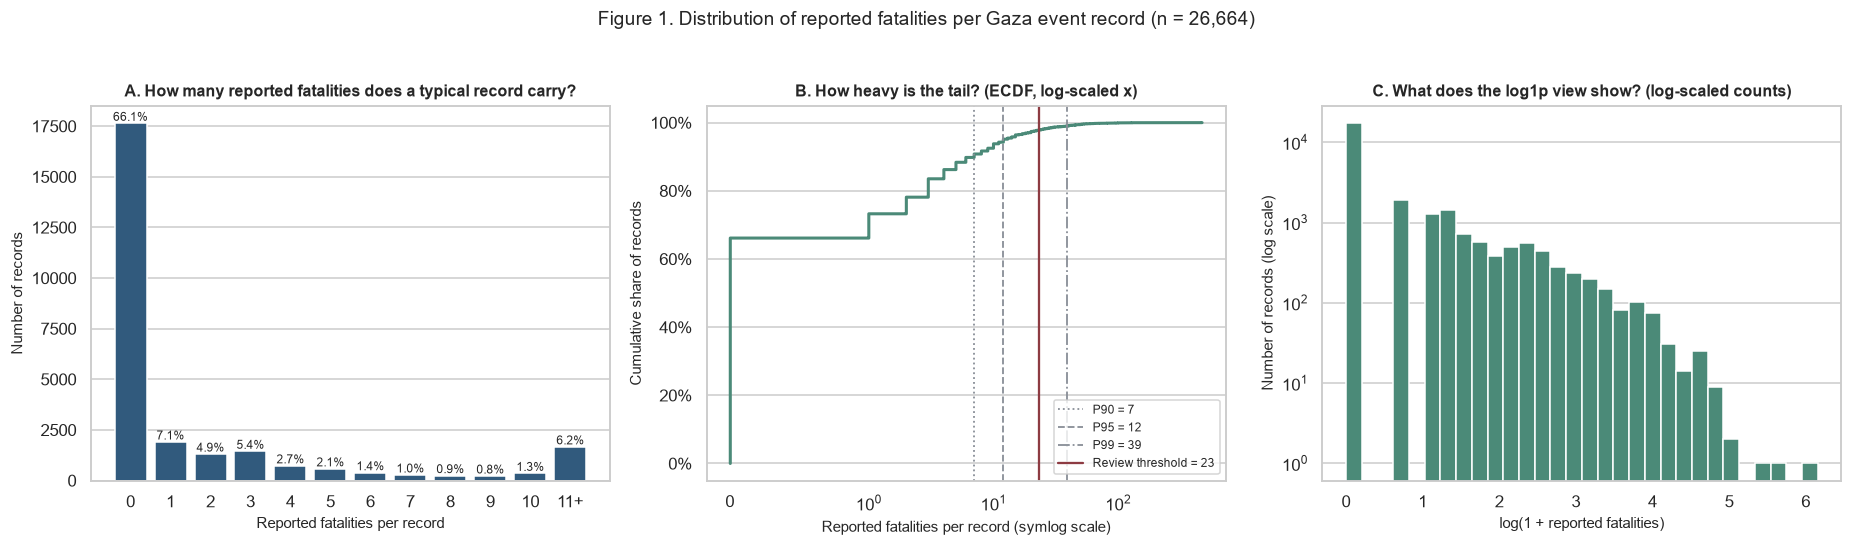

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# exact counts for small values, with a pooled 11+ bar
vc = f.clip(upper=11).value_counts().sort_index()
axes[0].bar([str(i) if i < 11 else "11+" for i in vc.index], vc.values, color=BLUE)
for x, v in enumerate(vc.values):
    axes[0].text(x, v, f"{v / len(f):.1%}", ha="center", va="bottom", fontsize=8)
axes[0].set_title("A. How many reported fatalities does a typical record carry?", fontsize=10.5)
axes[0].set_xlabel("Reported fatalities per record")
axes[0].set_ylabel("Number of records")

# ECDF on a symmetric-log x-axis
x = np.sort(f.to_numpy())
y = np.arange(1, len(x) + 1) / len(x)
axes[1].step(x, y, where="post", color=GREEN, lw=2)
axes[1].set_xscale("symlog", linthresh=1)
for q, ls in zip([.90, .95, .99], [":", "--", "-."]):
    axes[1].axvline(f.quantile(q), color=GREY, ls=ls, lw=1.2, label=f"P{int(q * 100)} = {f.quantile(q):.0f}")
axes[1].axvline(REVIEW_THRESHOLD, color=RED, lw=1.5, label=f"Review threshold = {REVIEW_THRESHOLD}")
axes[1].set_title("B. How heavy is the tail? (ECDF, log-scaled x)", fontsize=10.5)
axes[1].set_xlabel("Reported fatalities per record (symlog scale)")
axes[1].set_ylabel("Cumulative share of records")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].legend(fontsize=8, loc="lower right")

axes[2].hist(master.fatalities_log1p, bins=30, color=GREEN, edgecolor="white")
axes[2].set_yscale("log")
axes[2].set_title("C. What does the log1p view show? (log-scaled counts)", fontsize=10.5)
axes[2].set_xlabel("log(1 + reported fatalities)")
axes[2].set_ylabel("Number of records (log scale)")

fig.suptitle("Figure 1. Distribution of reported fatalities per Gaza event record (n = 26,664)", fontsize=12.5, y=1.03)
plt.tight_layout()
plt.show()

**Question.** How many reported fatalities does a record carry, and how heavy is the tail?

**Result.**
 Two out of three records (17,634; 66.1%) report zero fatalities and the median is 0 (Q1/Q3 = 0/2). Among the 9,030 records with at least one, the median is 3 but the mean is 7.53. The percentiles climb steeply: P90 = 7, P95 = 12, P99 = 39, maximum 471 (air/drone strike, Gaza – Az Zaytun, October 17, 2023). The 576 flagged records (2.2%) hold 37.6% of all 68,012 reported fatalities, and all of them occur on or after October 7, 2023. Using the Gaza-only P99 (39) instead of the Phase 2 threshold (23) would flag 262 records.

**Meaning.** 
Fatalities are zero-inflated and heavy-tailed, so means and standard deviations (mean 2.55, SD 8.50) describe a distribution that almost no record resembles. Later comparisons should use medians, IQR, percentiles, or `log1p`, and say how many records sit in the zero class.

**Limit.** 
Totals describe the whole event record, not the number of civilians killed, and the largest values should be checked against `notes` and `source` before being quoted.

### 3.8.3 Event categories: `event_type`, `sub_event_type`, `disorder_type`

**Question:** which recorded event types dominate, and are the categories large enough to compare later?
We report counts and shares of all 26,664 records. Sub-event types nest inside event types (checked by assertion), and `disorder_type` can hold two labels in one record, so we keep the recorded value and report the `political_violence` flag separately.

In [20]:
def count_table(series, total=None):
    total = total or len(series)
    out = series.value_counts(dropna=False).rename("Records").to_frame()
    out["Share (%)"] = (100 * out.Records / total).round(2)
    return out

print("event_type")
display(count_table(master.event_type))
print("\nsub_event_type (with its parent event_type)")
parent = master.groupby("sub_event_type").event_type.agg(["nunique", "first"])
assert (parent["nunique"] == 1).all(), "A sub_event_type maps to more than one event_type."
sub_tbl = count_table(master.sub_event_type)
sub_tbl.insert(0, "Parent event_type", parent["first"].reindex(sub_tbl.index))
display(sub_tbl)

print("\ndisorder_type (multi-label values kept as recorded)")
display(count_table(master.disorder_type))
both = master.disorder_type.str.contains(";", na=False).sum()
print(f"Records carrying two disorder labels: {both}")
print(f"political_violence flag (token match): {master.political_violence.sum():,} "
      f"({master.political_violence.mean():.1%} of records)")

event_type


,Records,Share (%)
event_type,,
Explosions/Remote violence,20276,76.04
Strategic developments,3517,13.19
Battles,1648,6.18
Violence against civilians,814,3.05
Protests,330,1.24
Riots,79,0.30



sub_event_type (with its parent event_type)


,Parent event_type,Records,Share (%)
sub_event_type,,,
Air/drone strike,Explosions/Remote violence,12357,46.34
Shelling/artillery/missile attack,Explosions/Remote violence,7617,28.57
Other,Strategic developments,1663,6.24
Armed clash,Battles,1647,6.18
Looting/property destruction,Strategic developments,1509,5.66
Attack,Violence against civilians,798,2.99
Peaceful protest,Protests,318,1.19
Change to group/activity,Strategic developments,301,1.13
Remote explosive/landmine/IED,Explosions/Remote violence,299,1.12



disorder_type (multi-label values kept as recorded)


,Records,Share (%)
disorder_type,,
Political violence,22746,85.31
Strategic developments,3517,13.19
Demonstrations,394,1.48
Political violence; Demonstrations,7,0.03


Records carrying two disorder labels: 7
political_violence flag (token match): 22,753 (85.3% of records)


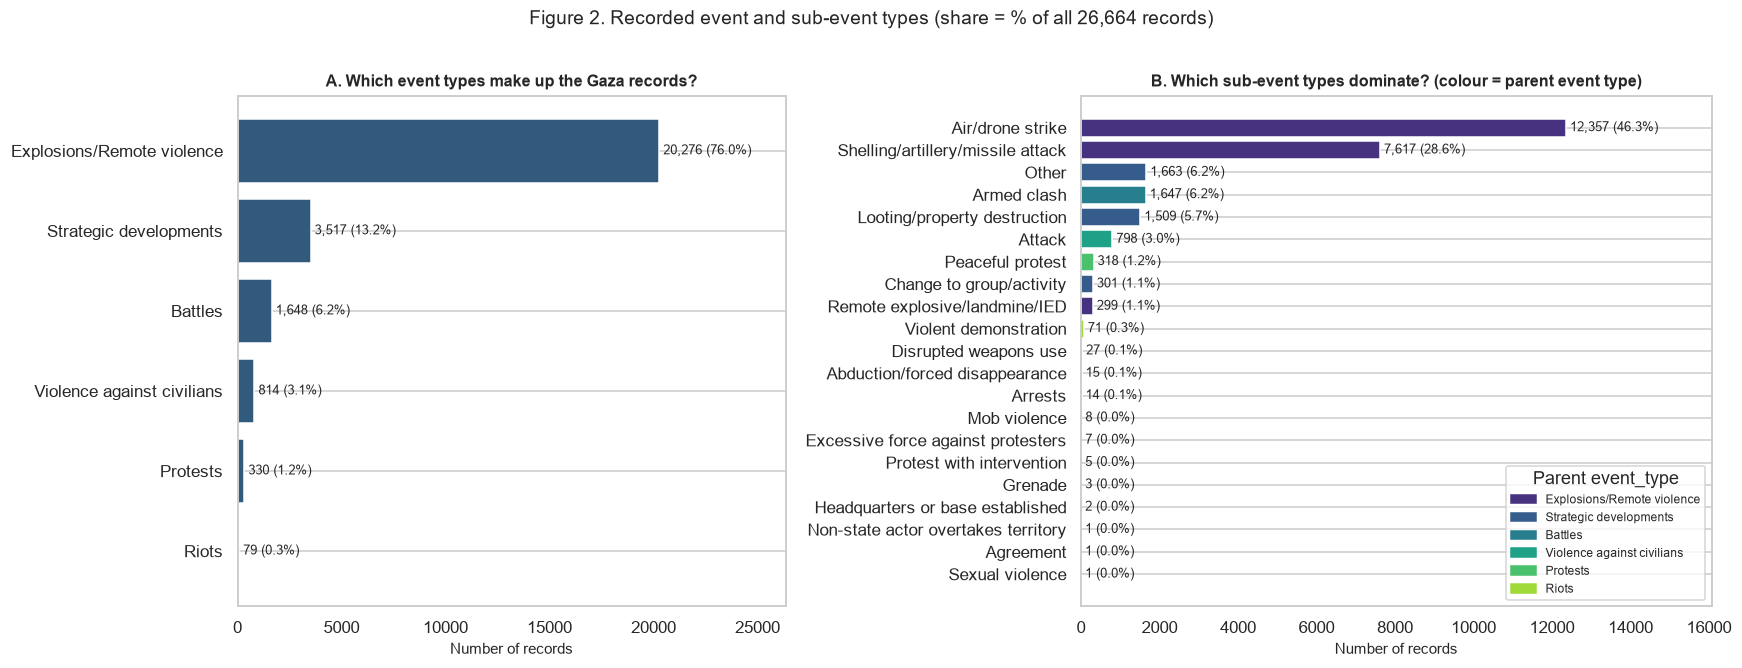

In [21]:
def short(label, n=46):
    label = str(label)
    return label if len(label) <= n else label[: n - 1] + "…"

def barh_counts(ax, counts, total, title, color=BLUE, xlabel="Number of records"):
    """Horizontal count bars (largest on top) labelled with count and share of `total`."""
    counts = counts.sort_values()
    ax.barh([short(i) for i in counts.index], counts.values, color=color)
    for ypos, v in enumerate(counts.values):
        ax.text(v, ypos, f" {v:,} ({v / total:.1%})", va="center", fontsize=8.5)
    ax.set_title(title, fontsize=10.5)
    ax.set_xlabel(xlabel)
    ax.set_xlim(0, counts.max() * 1.30)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1, 1.15]})
barh_counts(axes[0], master.event_type.value_counts(), len(master),
            "A. Which event types make up the Gaza records?")
type_order = master.event_type.value_counts().index.tolist()
palette = dict(zip(type_order, sns.color_palette("viridis", len(type_order))))
sub_counts = master.sub_event_type.value_counts().sort_values()
axes[1].barh([short(i) for i in sub_counts.index], sub_counts.values,
             color=[palette[parent["first"][i]] for i in sub_counts.index])
for ypos, v in enumerate(sub_counts.values):
    axes[1].text(v, ypos, f" {v:,} ({v / len(master):.1%})", va="center", fontsize=8.5)
axes[1].set_xlim(0, sub_counts.max() * 1.30)
axes[1].set_title("B. Which sub-event types dominate? (colour = parent event type)", fontsize=10.5)
axes[1].set_xlabel("Number of records")
handles = [plt.Rectangle((0, 0), 1, 1, color=palette[t]) for t in type_order]
axes[1].legend(handles, type_order, fontsize=8, loc="lower right", title="Parent event_type")
fig.suptitle("Figure 2. Recorded event and sub-event types (share = % of all 26,664 records)", fontsize=12.5, y=1.01)
plt.tight_layout()
plt.show()

**Question.** Which event types and sub-event types make up the Gaza records? <br>
**Result.** *Explosions/Remote violence* is 76.1% of records (20,276), followed by *Strategic developments* 13.2% (3,517), *Battles* 6.2% (1,648), *Violence against civilians* 3.1% (814), *Protests* 1.2% (330) and *Riots* 0.3% (79). Two sub-types, *Air/drone strike* (12,357; 46.3%) and *Shelling/artillery/missile attack* (7,617; 28.6%), together make up 74.9% of all records. Eleven of the 21 sub-types have fewer than 30 records. By `disorder_type`, 22,746 records are *Political violence*, 3,517 *Strategic developments*, 394 *Demonstrations*, and 7 carry both Political violence and Demonstrations, so the `political_violence` flag covers 22,753 records (85.3%).<br>
**Meaning.** The data is dominated by a few remote-violence categories. This is a class-imbalance problem for any event-type comparison (BQ2) and for Hypothesis B, which tests focal prevalence across event types within political-violence records.<br>
**Limit.** ACLED's `Strategic developments` includes sub-types such as *Looting/property destruction* and *Other*, so the label is not a measure of fighting. Rare categories (Riots, Protests, and the sub-types with a handful of records) will give sparse cells and should be grouped, or tested with a Monte Carlo method.

### 3.8.4 Actors: `actor1`, `actor2`, `inter1`, `inter2`

**Question:** which actor labels recur, how many are blank, and what changes when we look only at focal events?
Actor labels are ACLED's coding, not verified roles. `actor2` blanks are structural: Phase 2 showed they coincide with blank `inter2` and a single-sided interaction label, and the assertion below re-confirms that. We list top labels overall and among focal events (`focal_event == True`).

In [22]:
focal = master[master.focal_event]

actor_overview = pd.DataFrame({
    "actor1": [master.actor1.isna().sum(), master.actor1.nunique()],
    "actor2": [master.actor2.isna().sum(), master.actor2.nunique()],
    "inter1 (actor type)": [master.inter1.isna().sum(), master.inter1.nunique()],
    "inter2 (actor type)": [master.inter2.isna().sum(), master.inter2.nunique()],
}, index=["Missing", "Distinct labels"]).T
actor_overview["Missing (%)"] = (100 * actor_overview.Missing / len(master)).round(2)
display(actor_overview)

only = master.interaction.str.endswith(" only", na=False)
assert master.actor2.isna().equals(master.inter2.isna()) and (~master.actor2.isna() | only).all()
print("Blank actor2 = blank inter2 in every record, and every blank sits on a single-sided ('only') interaction.")

print("\nTop actor1 labels, all events")
display(count_table(master.actor1).head(10))
print("\nTop actor2 labels, all events (blank shown as NaN)")
display(count_table(master.actor2).head(8))
print(f"\nFocal events: {len(focal):,}")
print("Top actor1 labels among focal events")
display(count_table(focal.actor1).head(8))
print("actor2 among focal events:", focal.actor2.value_counts(dropna=False).to_dict())

print("\nActor-type (inter1) counts, all events")
display(count_table(master.inter1))

# Date range of the two Israeli-forces labels: are they versions rather than separate actors?
israel = master[master.actor1.str.startswith("Military Forces of Israel", na=False)]
display(israel.groupby("actor1").event_date.agg(["min", "max", "size"]))

,Missing,Distinct labels,Missing (%)
actor1,0,34,0.00
actor2,8641,41,32.41
inter1 (actor type),0,7,0.00
inter2 (actor type),8641,8,32.41


Blank actor2 = blank inter2 in every record, and every blank sits on a single-sided ('only') interaction.

Top actor1 labels, all events


,Records,Share (%)
actor1,,
Military Forces of Israel (2022-),21629,81.12
Hamas Movement,1942,7.28
Military Forces of Israel (2021-2022),1277,4.79
PIJ: Palestinian Islamic Jihad,622,2.33
Protesters (Palestine),329,1.23
Civilians (Palestine),135,0.51
Sahm Unit,124,0.47
Unidentified Armed Group (Palestine),97,0.36
Al Aqsa Martyrs Brigade,97,0.36



Top actor2 labels, all events (blank shown as NaN)


,Records,Share (%)
actor2,,
Civilians (Palestine),13638,51.15
NaN,8641,32.41
Military Forces of Israel (2022-),2933,11.00
Hamas Movement,876,3.29
PIJ: Palestinian Islamic Jihad,294,1.10
Unidentified Armed Group (Palestine),109,0.41
Police Forces of Palestine (2007-) Gaza Strip,41,0.15
Unidentified Communal Militia (Palestine),21,0.08



Focal events: 10,714
Top actor1 labels among focal events


,Records,Share (%)
actor1,,
Military Forces of Israel (2022-),10493,97.94
Sahm Unit,90,0.84
Military Forces of Israel (2021-2022),36,0.34
Hamas Movement,36,0.34
Unidentified Armed Group (Palestine),28,0.26
Unidentified Communal Militia (Palestine),9,0.08
Police Forces of Palestine (2007-) Gaza Strip,7,0.07
Unidentified Clan Militia (Palestine),4,0.04


actor2 among focal events: {'Civilians (Palestine)': 10714}

Actor-type (inter1) counts, all events


,Records,Share (%)
inter1,,
External/Other forces,22922,85.97
Political militia,3146,11.80
Protesters,330,1.24
Civilians,135,0.51
Rioters,79,0.30
Identity militia,38,0.14
State forces,14,0.05


,min,max,size
actor1,,,
Military Forces of Israel (2021-2022),2022-01-01,2022-12-28,1277
Military Forces of Israel (2022-),2022-12-29,2025-09-30,21629
Military Forces of Israel (2022-) Golani Brigade,2025-03-19,2025-04-17,2
Military Forces of Israel (2022-) Special Forces,2023-12-12,2023-12-13,11


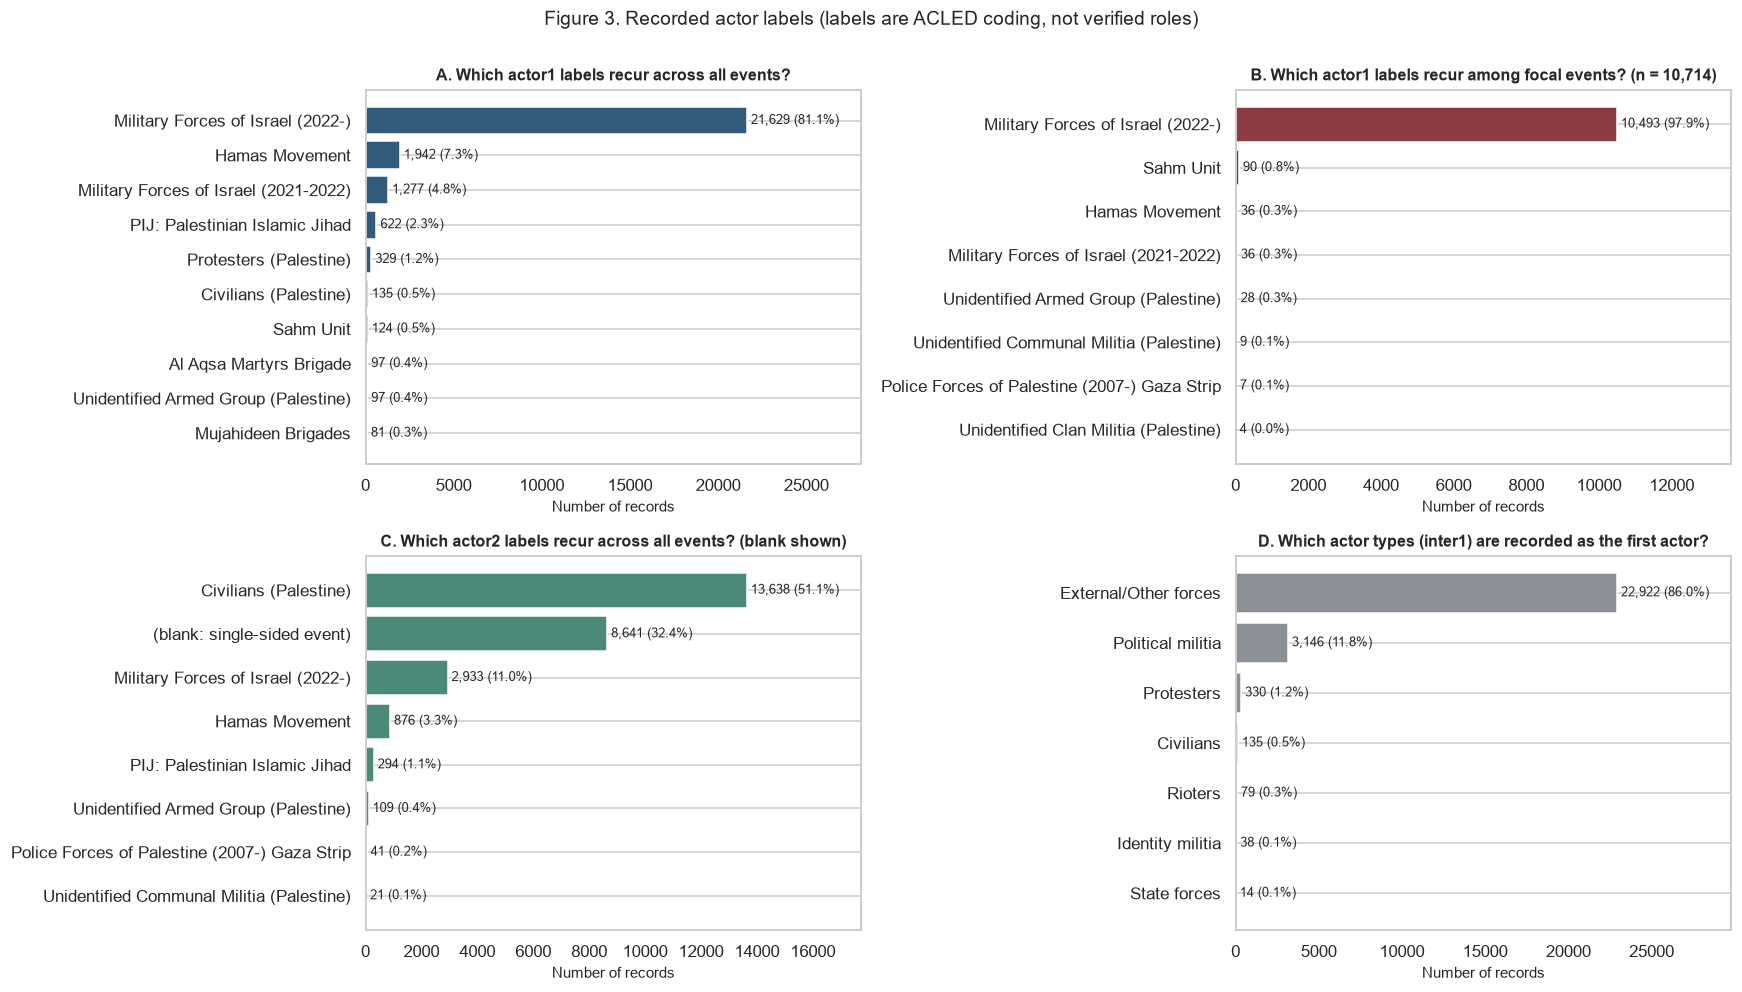

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(16, 9))

barh_counts(axes[0, 0], master.actor1.value_counts().head(10), len(master),
            "A. Which actor1 labels recur across all events?")
barh_counts(axes[0, 1], focal.actor1.value_counts().head(8), len(focal),
            "B. Which actor1 labels recur among focal events? (n = 10,714)", color=RED)

actor2_counts = master.actor2.fillna("(blank: single-sided event)").value_counts().head(8)
barh_counts(axes[1, 0], actor2_counts, len(master),
            "C. Which actor2 labels recur across all events? (blank shown)", color=GREEN)
barh_counts(axes[1, 1], master.inter1.value_counts(), len(master),
            "D. Which actor types (inter1) are recorded as the first actor?", color=GREY)

fig.suptitle("Figure 3. Recorded actor labels (labels are ACLED coding, not verified roles)", fontsize=12.5, y=1.0)
plt.tight_layout()
plt.show()

**Question.** Which actor labels recur across all events and among focal events? <br>
**Result.** `actor1` is never blank (34 labels); `actor2` is blank in 8,641 records (32.4%, structural) and has 41 labels. Across all events, *Military Forces of Israel (2022-)* is the `actor1` label in 21,629 records (81.1%), followed by *Hamas Movement* (1,942; 7.3%), the earlier-dated *Military Forces of Israel (2021-2022)* label (1,277; 4.8%) and *PIJ* (622; 2.3%). The two Israeli-forces labels switch on December 29, 2022 (the 2021–2022 label ends on December 28, 2022 and the 2022- label begins the next day), so they look like date-versioned names, not two different forces. `actor2` is *Civilians (Palestine)* in 13,638 records (51.1%). Among the 10,714 focal events, *Military Forces of Israel (2022-)* is `actor1` in 10,493 (97.9%), with *Sahm Unit* (90), then *Hamas Movement* and the 2021–2022 Israeli-forces label (36 each, tied) and *Unidentified Armed Group (Palestine)* (28). <br>
**Meaning.** Within focal events the `actor1` distribution is almost a single label, and `actor2` is always *Civilians (Palestine)* because the focal rule requires that label. Actor labels therefore separate focal from non-focal events by construction and carry little further information inside the focal group. BQ2 needs event types, notes and dates, not actor labels alone.<br>
**Limit.** Actor labels are coded categories. They do not establish who did what, intent, or responsibility, and the versioned Israeli-forces labels are kept separate (as in Phase 2); merging them is an analyst decision that should be documented.<br>

In [24]:
# Marginal distributions of the three Boolean flags; period comparisons are in Section 3.9.
for col in ["targeting_flagged", "political_violence", "focal_event"]:
    counts = master[col].value_counts(dropna=False).reindex([True, False], fill_value=0)
    table = pd.DataFrame({"count": counts, "share_pct": (100 * counts / len(master)).round(2)})
    print(f"\n{col}: denominator = all {len(master):,} Gaza event records")
    display(table)


targeting_flagged: denominator = all 26,664 Gaza event records


,count,share_pct
targeting_flagged,,
True,10732,40.25
False,15932,59.75



political_violence: denominator = all 26,664 Gaza event records


,count,share_pct
political_violence,,
True,22753,85.33
False,3911,14.67



focal_event: denominator = all 26,664 Gaza event records


,count,share_pct
focal_event,,
True,10714,40.18
False,15950,59.82


**Flag interpretation.** These are all-period marginal counts. `targeting_flagged` is the recorded ACLED targeting flag, `political_violence` defines the denominator used later, and `focal_event` applies the project's documented flag-plus-actor rule. Period-specific comparisons belong in Section 3.9.

### 3.8.5 Quality codes: `geo_precision` and `time_precision`

**Question:** how precisely are locations and dates recorded, and does the land focal table differ from the full master?
These are categorical codes (1, 2, 3), not measurements. We show them for the event master and the land focal incident table, and split `geo_precision` by period.

In [25]:
def code_share(frame, col):
    return (frame[col].value_counts(normalize=True).sort_index() * 100).round(2)

prec = pd.DataFrame({
    "geo_precision: master (n)": master.geo_precision.value_counts().sort_index(),
    "geo_precision: master (%)": code_share(master, "geo_precision"),
    "geo_precision: land focal incidents (n)": incidents.geo_precision.value_counts().sort_index(),
    "geo_precision: land focal incidents (%)": code_share(incidents, "geo_precision"),
})
display(prec)
tprec = pd.DataFrame({
    "time_precision: master (n)": master.time_precision.value_counts().sort_index(),
    "time_precision: master (%)": code_share(master, "time_precision"),
    "time_precision: land focal incidents (n)": incidents.time_precision.value_counts().sort_index(),
    "time_precision: land focal incidents (%)": code_share(incidents, "time_precision"),
})
display(tprec)
by_period_prec = pd.crosstab(master.period, master.geo_precision, normalize="index").mul(100).round(1)
by_period_prec.columns = [f"geo_precision {i} (%)" for i in by_period_prec.columns]
print("geo_precision by period (share of each period's records):")
display(by_period_prec.loc[[BEFORE, AFTER]])
print("geo_precision_1 =", f"{master.geo_precision_1.mean():.1%} of master;", f"{incidents.geo_precision_1.mean():.1%} of land focal incidents")
print("time_precision_1 =", f"{master.time_precision_1.mean():.1%} of master")

,geo_precision: master (n),geo_precision: master (%),geo_precision: land focal incidents (n),geo_precision: land focal incidents (%)
geo_precision,,,,
1,14313,53.68,7576,71.59
2,12231,45.87,2976,28.12
3,120,0.45,31,0.29


,time_precision: master (n),time_precision: master (%),time_precision: land focal incidents (n),time_precision: land focal incidents (%)
time_precision,,,,
1,26451,99.20,10541,99.60
2,188,0.71,37,0.35
3,25,0.09,5,0.05


geo_precision by period (share of each period's records):


,geo_precision 1 (%),geo_precision 2 (%),geo_precision 3 (%)
period,,,
"Before Oct 7, 2023",20.0,79.5,0.5
"Oct 7, 2023 onward",56.8,42.8,0.4


geo_precision_1 = 53.7% of master; 71.6% of land focal incidents
time_precision_1 = 99.2% of master


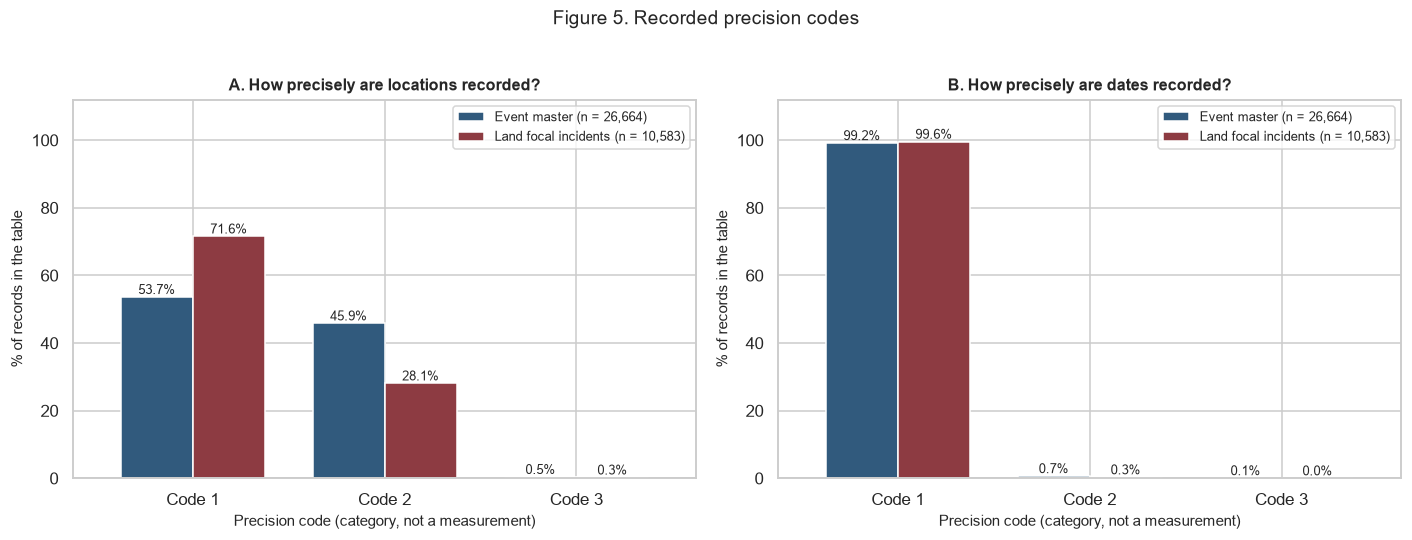

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, col, title in [(axes[0], "geo_precision", "A. How precisely are locations recorded?"),
                       (axes[1], "time_precision", "B. How precisely are dates recorded?")]:
    shares = pd.DataFrame({"Event master (n = 26,664)": master[col].value_counts(normalize=True).sort_index() * 100,
                           "Land focal incidents (n = 10,583)": incidents[col].value_counts(normalize=True).sort_index() * 100})
    shares.index = [f"Code {i}" for i in shares.index]
    shares.plot.bar(ax=ax, color=[BLUE, RED], rot=0, width=0.75)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f%%", fontsize=8.5)
    ax.set_title(title, fontsize=10.5)
    ax.set_ylabel("% of records in the table")
    ax.set_xlabel("Precision code (category, not a measurement)")
    ax.set_ylim(0, 112)
    ax.legend(fontsize=8.5)
fig.suptitle("Figure 5. Recorded precision codes", fontsize=12.5, y=1.02)
plt.tight_layout()
plt.show()

**Question.** How precisely are locations and dates recorded?<br>
**Result.** Dates are almost always precise: `time_precision` = 1 in 99.2% of the master (26,451 records; 188 are code 2 and 25 are code 3). Locations are not: `geo_precision` = 1 in 53.7% of records (14,313), code 2 in 45.9% (12,231) and code 3 in 0.45% (120; about 0.5% to one decimal place). In the land focal incidents, code 1 is higher at 71.6% (7,576 of 10,583). Precision also differs sharply by period: only 20.0% of pre-Oct 7 records are code 1, against 56.8% from Oct 7 onward.<br>
**Meaning.** The `geo_precision_1` subset is a real restriction: it keeps 71.6% of the focal incidents and a different mix of places. The much lower share of precise locations before Oct 7 also means maps and clusters from the two periods are not equally well located.<br>
**Limit.** Precision reflects how the location was documented, not where events happened. A pattern that changes with the precision restriction may be a documentation effect, and the Phase 4 sensitivity run has to show both views.

### 3.8.6 Area and time: `admin2`, `location`, `period`, `year`, `month_start`, `week_start`

**Question:** where and when are records logged?
We count records by district (the four with no district stay visible), summarize the monthly and weekly record counts, and mark October 7, 2023. These are record counts at the event level, not rates.

In [27]:
admin2_counts = master.admin2.fillna("(missing district)").value_counts()
admin_tbl = admin2_counts.rename("Records").to_frame()
admin_tbl["Share of all events (%)"] = (100 * admin_tbl.Records / len(master)).round(2)
admin_tbl["Share of known-district events (%)"] = (100 * admin_tbl.Records / master.admin2.notna().sum()).round(2)
admin_tbl.loc["(missing district)", "Share of known-district events (%)"] = np.nan
display(admin_tbl)
print("Missing-district records (all coast-coded in Phase 2):", int(master.district_missing.sum()))
print(f"Coast-coded locations: {master.coastal_location.sum():,} records ({master.coastal_location.mean():.1%}); "
      f"distinct location labels: {master.location.nunique()}")

display(master.groupby("year").size().rename("Records").to_frame().assign(
    **{"Share (%)": lambda d: (100 * d.Records / len(master)).round(2)}))

monthly = master.groupby("month_start").size()
weekly_n = master.groupby("week_start").size()
print(f"\nDistinct calendar months: {monthly.size} | distinct Saturday-start weeks: {weekly_n.size}")
display(pd.DataFrame({"Records per month": monthly.describe().round(1),
                      "Records per week": weekly_n.describe().round(1)}).T)
print("Peak month:", monthly.idxmax().strftime("%Y-%m"), f"({monthly.max():,} records)")
print("Peak week:", weekly_n.idxmax().date(), f"({weekly_n.max():,} records)")
print("Median monthly records, before vs from Oct 2023:",
      int(monthly[monthly.index < "2023-10-01"].median()), "vs", int(monthly[monthly.index >= "2023-10-01"].median()))

,Records,Share of all events (%),Share of known-district events (%)
admin2,,,
Gaza City,8036,30.14,30.14
Khan Yunis,6005,22.52,22.52
Deir El Balah,4781,17.93,17.93
North Gaza,4303,16.14,16.14
Rafah,3535,13.26,13.26
(missing district),4,0.02,NaN


Missing-district records (all coast-coded in Phase 2): 4
Coast-coded locations: 701 records (2.6%); distinct location labels: 117


,Records,Share (%)
year,,
2022,1430,5.36
2023,4449,16.69
2024,12823,48.09
2025,7962,29.86



Distinct calendar months: 45 | distinct Saturday-start weeks: 196


,count,mean,std,min,25%,50%,75%,max
Records per month,45.0,592.5,499.0,46.0,115.0,637.0,1044.0,1466.0
Records per week,196.0,136.0,117.5,3.0,25.0,80.0,241.2,367.0


Peak month: 2023-12 (1,466 records)
Peak week: 2023-10-28 (367 records)
Median monthly records, before vs from Oct 2023: 109 vs 1034


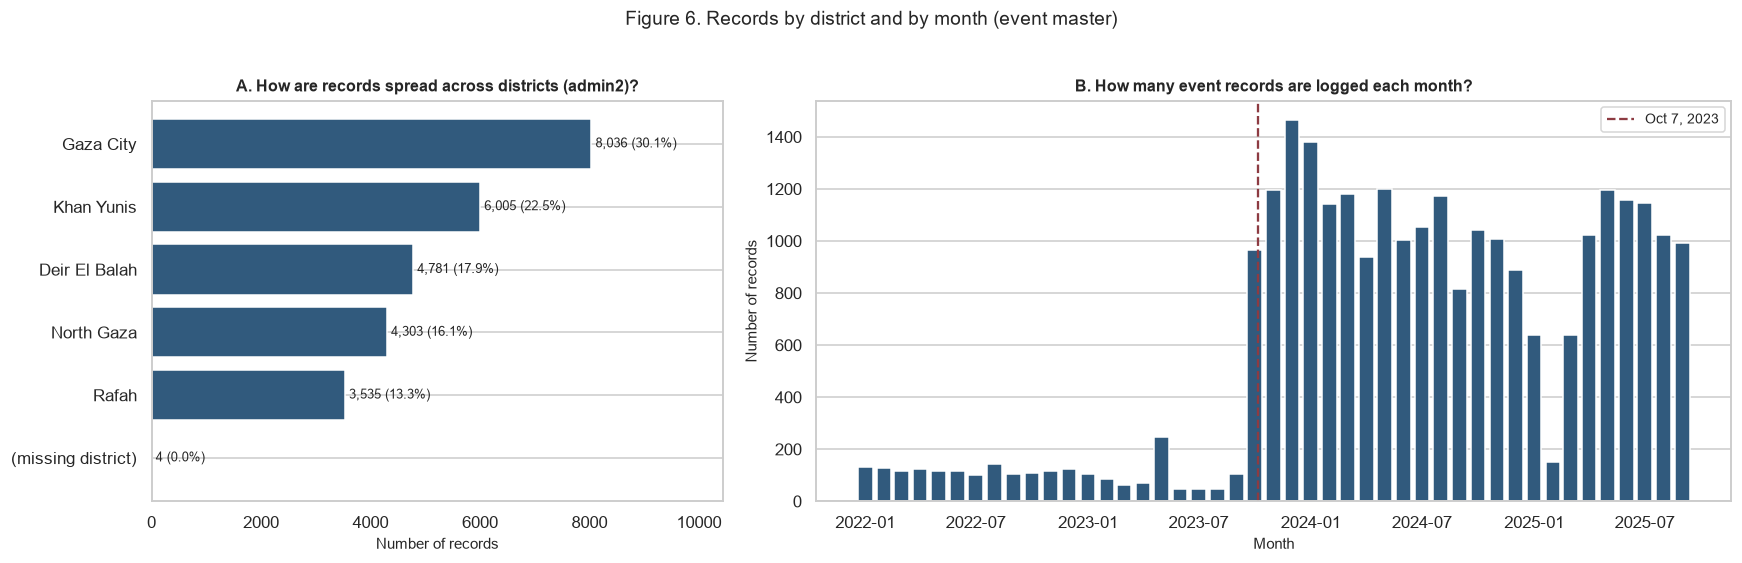

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1, 1.6]})
barh_counts(axes[0], admin2_counts, len(master), "A. How are records spread across districts (admin2)?")
axes[1].bar(monthly.index, monthly.values, width=24, color=BLUE)
axes[1].axvline(cutoff, color=RED, ls="--", lw=1.5, label="Oct 7, 2023")
axes[1].set_title("B. How many event records are logged each month?", fontsize=10.5)
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Number of records")
axes[1].legend(fontsize=9)
fig.suptitle("Figure 6. Records by district and by month (event master)", fontsize=12.5, y=1.02)
plt.tight_layout()
plt.show()

**Question.** How are records spread across districts, and how many are logged each month? <br>
**Result.** Records are logged in five districts: Gaza City 8,036 (30.1%), Khan Yunis 6,005 (22.5%), Deir El Balah 4,781 (17.9%), North Gaza 4,303 (16.1%) and Rafah 3,535 (13.3%); 4 records have no district (all coast-coded) and 701 records (2.6%) have a coast-coded location label. By year, 2022 has 1,430 records, 2023 has 4,449, 2024 has 12,823 (48.1%), and 2025 (January to September) has 7,962. The monthly median is 109 records before October 2023 and 1,034 from October 2023, with a peak of 1,466 in December 2023 and a peak week of 367 records (week starting October 28, 2023). Two months are notable departures from their immediate neighbors: May 2023 (248 records, against 69 in April and 49 in June) and February 2025 (150 records, against 638 in January and 637 in March). <br>
**Meaning.** Records concentrate in Gaza City, but no district is negligible. The monthly series changes substantially around October 2023 and contains a marked February 2025 trough relative to adjacent months. These are descriptive patterns only; the monthly counts do not establish why the changes occurred. Period, time and district should be considered in later comparisons. <br>
**Limit.** Record counts reflect both activity and reporting coverage, which can change over time and place. The four missing-district events remain in Gaza-wide totals and are excluded only from district summaries. May 2023 and February 2025 are descriptive observations; this table does not explain them.


## 3.9 Bivariate analysis — how do groups compare?

**Source table:** `master` unless the comparison is explicitly weekly or spatial. Start with Phase 1 questions: before/after period differences, event-type composition, actor/event profiles, severity, and precision. Use counts and rates together when group sizes differ.

For every share, state the denominator. For actor comparisons, describe recorded labels and consult notes before assigning actor roles. These are exploratory comparisons; an association is not a causal effect.

,events,political_events,focal_events,focal_share_of_all_events,focal_share_of_political_events
event_type,,,,,
Explosions/Remote violence,20276,20276,9906,0.488558,0.488558
Violence against civilians,814,814,808,0.992629,0.992629
Battles,1648,1648,0,0.000000,0.000000
Protests,330,7,0,0.000000,0.000000
Riots,79,8,0,0.000000,0.000000
Strategic developments,3517,0,0,0.000000,NaN


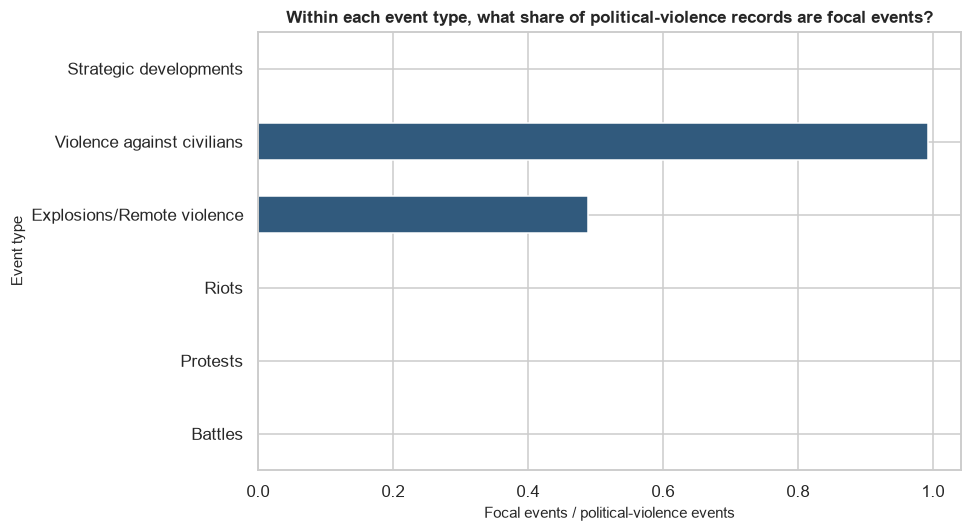

In [29]:
# Example: event-type denominators and focal-event counts/shares.
event_type_summary = master.groupby("event_type", dropna=False).agg(
    events=("event_id_cnty", "size"),
    political_events=("political_violence", "sum"),
    focal_events=("focal_event", "sum"),
)
event_type_summary["focal_share_of_all_events"] = event_type_summary.focal_events / event_type_summary.events
event_type_summary["focal_share_of_political_events"] = (
    event_type_summary.focal_events / event_type_summary.political_events.replace(0, np.nan)
)
display(event_type_summary.sort_values("focal_events", ascending=False))

ax = event_type_summary.sort_values("focal_share_of_political_events")["focal_share_of_political_events"].plot(
    kind="barh", figsize=(9, 5), color="#315A7D"
)
ax.set_title("Within each event type, what share of political-violence records are focal events?")
ax.set_xlabel("Focal events / political-violence events")
ax.set_ylabel("Event type")
plt.tight_layout()
plt.show()

# Interpretation: [Which event types have the largest focal shares? How do counts and denominators affect the comparison?]

# Phase 3 — Bivariate and Multivariate Analysis
## Patterns of Recorded Civilian Targeting in Gaza

**DS312 · Group 7 · Phase 3 EDA, bivariate and multivariate section**



## 1. Introduction

### Purpose and scope
This section looks at how recorded Gaza events relate to each other: how the focal share changes between periods, event types, precision levels, districts and weeks, and how fatalities differ between groups. It supports the Phase 1 business questions BQ1 (before/after), BQ2 (event and actor profiles), BQ4 (district-week concentration and persistence) and BQ5 (sensitivity to precision), and it tests whether the Phase 4 plan (weekly anomaly detection at district level) has enough structure to work with.

### Which table answers which question

| Question | Table (unit of analysis) | Charts |
|---|---|---|
| Before/after focal share; event-type mix and prevalence; fatalities; precision; actors | `acled_events_clean.csv` (one Gaza event) | 1 to 7 |
| Where and when focal activity is concentrated by district | `acled_district_week.csv` (one known district and week) | 8 and 10 |
| How Gaza-wide weekly counts and shares move | `acled_gaza_week.csv` (one Gaza-wide week) | 9 and 11 (left) |
| Which categorical fields are associated | `acled_events_clean.csv`, political-violence records only | 11 (right) |

We do not mix units. Event-level results are never added to weekly results without an explicit aggregation step.

### Interpretation boundaries
- We describe **recorded ACLED events** and the project's own focal-event rule (ACLED targeting flag **and** the exact label "Civilians (Palestine)" in either actor field). The rule is a reproducible coding convention, not proof of intent, responsibility or legal classification.
- **Focal share** always means focal events divided by political-violence records from the *same* group, area and period. Counts are shown next to every rate.
- A zero in these tables means zero **recorded** events or fatalities. It is not evidence that no harm occurred, and a zero fatality count can also mean that no fatality information was reported.
- Associations are exploratory. Events are related across time and place, so neither the correlations nor the group differences should be read as causal.

## 3. Bivariate analysis

Source table for this section: `master` (political-violence records unless stated). Every share names its numerator and denominator.

### 3.1 Focal share before vs. after October 7, 2023 (BQ1)

**Question.** Does the focal share of political-violence records differ between the two periods? The periods are 644 and 725 days long, and the earlier one is sparse, so the chart pairs the share with per-week rates.

,political_records,focal,not_focal,focal_share,calendar_days,focal_per_week,political_per_week
period,,,,,,,
"Before Oct 7, 2023",389,63,326,0.162,644,0.68,4.23
"Oct 7, 2023 onward",22364,10651,11713,0.476,725,102.84,215.93


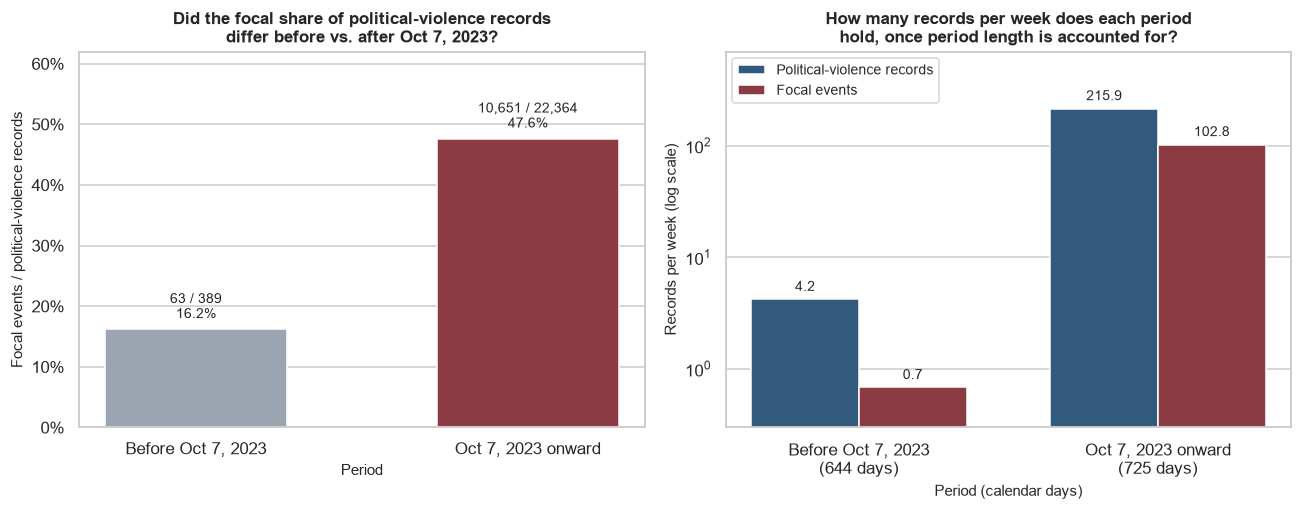

In [30]:
t1 = (political.groupby("period")
      .agg(political_records=("event_id_cnty", "size"), focal=("focal_event", "sum"))
      .loc[[BEFORE, AFTER]])
t1["not_focal"] = t1.political_records - t1.focal
t1["focal_share"] = t1.focal / t1.political_records
t1["calendar_days"] = [PERIOD_DAYS[p] for p in t1.index]
t1["focal_per_week"] = t1.focal * 7 / t1.calendar_days
t1["political_per_week"] = t1.political_records * 7 / t1.calendar_days
display(t1.round({"focal_share": 3, "focal_per_week": 2, "political_per_week": 2}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

# Left: focal share with numerator/denominator written on each bar
ax = axes[0]
bars = ax.bar(t1.index, t1.focal_share, color=[C_GREY, C_FOCAL], width=0.55)
for b, (_, r) in zip(bars, t1.iterrows()):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.012,
            f"{r.focal:,.0f} / {r.political_records:,.0f}\n{r.focal_share:.1%}", ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, 0.62)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylabel("Focal events / political-violence records")
ax.set_xlabel("Period")
ax.set_title("Did the focal share of political-violence records\ndiffer before vs. after Oct 7, 2023?")

# Right: per-week rates (log scale because the two periods differ by about 150x)
ax = axes[1]
x = np.arange(len(t1)); w = 0.36
b1 = ax.bar(x - w / 2, t1.political_per_week, w, color=C_OTHER, label="Political-violence records")
b2 = ax.bar(x + w / 2, t1.focal_per_week, w, color=C_FOCAL, label="Focal events")
for bars_, vals in ((b1, t1.political_per_week), (b2, t1.focal_per_week)):
    for b, v in zip(bars_, vals):
        ax.text(b.get_x() + b.get_width() / 2, v * 1.12, f"{v:,.1f}", ha="center", va="bottom", fontsize=9)
ax.set_yscale("log"); ax.set_ylim(0.3, 700)
ax.set_xticks(x)
ax.set_xticklabels([f"{p}\n({PERIOD_DAYS[p]} days)" for p in t1.index])
ax.set_xlabel("Period (calendar days)")
ax.set_ylabel("Records per week (log scale)")
ax.set_title("How many records per week does each period\nhold, once period length is accounted for?")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

**Interpretation.** The focal share is 16.2% (63 of 389 records) before Oct 7, 2023 and 47.6% (10,651 of 22,364) from Oct 7 onward, and the weekly rate of focal events goes from about 0.7 to about 102.8 across periods of 644 and 725 days (BQ1). The earlier period rests on only 63 focal events, so its share is imprecise, and a difference in share alone cannot separate a change in events from a change in coding or reporting coverage.

### 3.2 Focal prevalence within each event type (BQ2)

**Question.** Within each recorded event type, what share of political-violence records meet the focal rule? Counts alone would mostly show which types are large, so each bar uses its own type's denominator. Groups with fewer than 30 records are hatched.

,n,focal,focal_share
event_type,,,
Battles,1648,0,0.0000
Protests,7,0,0.0000
Riots,8,0,0.0000
Explosions/Remote violence,20276,9906,0.4886
Violence against civilians,814,808,0.9926


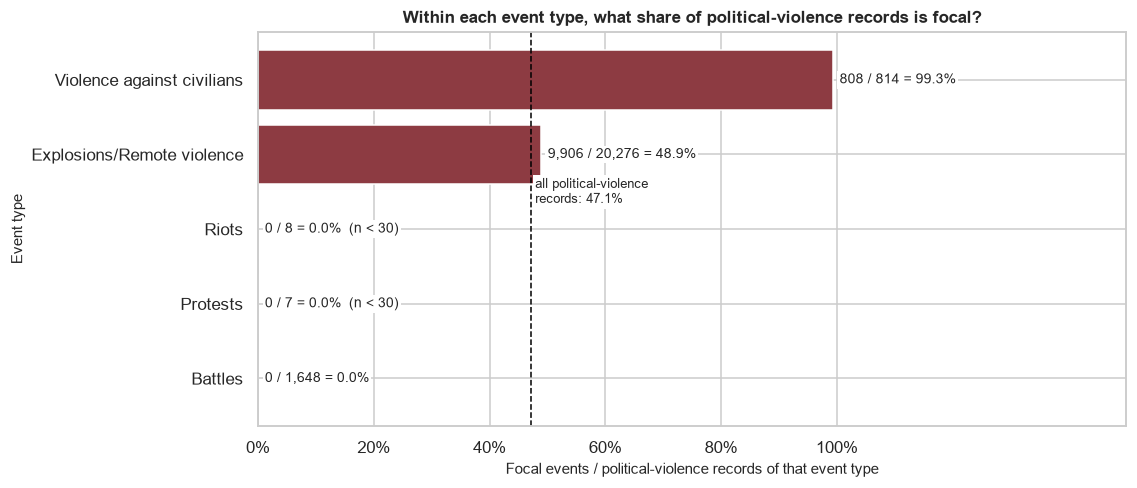

In [31]:
t2 = (political.groupby("event_type")
      .agg(n=("event_id_cnty", "size"), focal=("focal_event", "sum")))
t2["focal_share"] = t2.focal / t2.n
t2 = t2.sort_values("focal_share")
overall_share = political.focal_event.mean()
display(t2.round({"focal_share": 4}))

fig, ax = plt.subplots(figsize=(10.5, 4.6))
small = (t2.n < 30).to_numpy()
bars = ax.barh(t2.index, t2.focal_share, color=[C_GREY if s else C_FOCAL for s in small])
for b, s in zip(bars, small):
    if s:
        b.set_hatch("//")
for y, (_, r) in enumerate(t2.iterrows()):
    note = "  (n < 30)" if r.n < 30 else ""
    ax.text(r.focal_share + 0.012, y, f"{r.focal:,.0f} / {r.n:,.0f} = {r.focal_share:.1%}{note}", va="center", fontsize=9,
            bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
ax.axvline(overall_share, color="black", ls="--", lw=1)
ax.text(overall_share + 0.008, 2.5, f"all political-violence\nrecords: {overall_share:.1%}", fontsize=8.5, va="center",
        bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
ax.grid(axis="x")
ax.set_xlim(0, 1.5); ax.set_xticks(np.arange(0, 1.01, 0.2))
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Focal events / political-violence records of that event type")
ax.set_ylabel("Event type")
ax.set_title("Within each event type, what share of political-violence records is focal?")
plt.tight_layout()
plt.show()

**Interpretation.** Violence against civilians is almost entirely focal (808 of 814, 99.3%), Explosions/Remote violence is split (9,906 of 20,276, 48.9%), Battles have none (0 of 1,648), and Protests and Riots (7 and 8 records) have none (BQ2). The focal rule requires a civilian actor label, so part of this pattern is built into the coding; it describes how focal events are recorded, not which event types produce them, and the two small types cannot be judged.

### 3.3 Fatalities by focal status (BQ2)

**Question.** Do focal records report more fatalities than other political-violence records? Fatalities are heavily skewed with many zeros, so we compare full distributions (ECDF on a symmetric-log axis) and report median, IQR and percentiles instead of means alone. Fatalities are reported event totals, not civilian-death counts.

Political-violence records, by focal status


,n,share_zero,median,q1,q3,p90,mean,max
focal_event,,,,,,,,
False,12039,0.86,0.0,0.0,0.0,2.0,1.31,150
True,10714,0.31,2.0,0.0,5.0,12.0,4.87,471


Same comparison split by period


n  share_zero  median   q1   q3   p90  \
period             focal_event                                              
Before Oct 7, 2023 False          326        0.93     0.0  0.0  0.0   0.0   
                   True            63        0.78     0.0  0.0  0.0   2.0   
Oct 7, 2023 onward False        11713        0.86     0.0  0.0  0.0   3.0   
                   True         10651        0.31     2.0  0.0  5.0  12.0   

                                mean  max  
period             focal_event             
Before Oct 7, 2023 False        0.17    8  
                   True         0.59    7  
Oct 7, 2023 onward False        1.34  150  
                   True         4.90  471

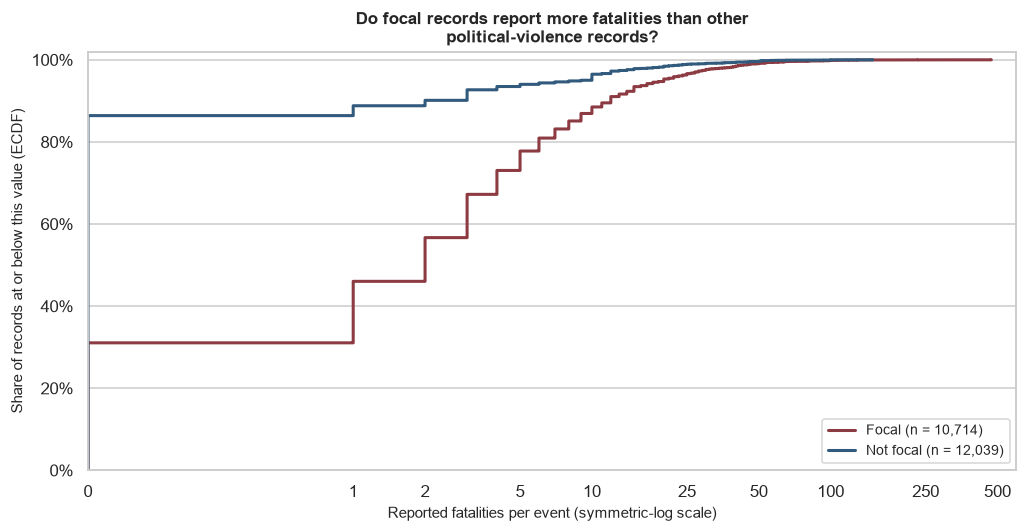

In [32]:
def fatality_summary(df, by):
    g = df.groupby(by, observed=True).fatalities
    return pd.DataFrame({"n": g.size(), "share_zero": g.apply(lambda s: (s == 0).mean()),
                         "median": g.median(), "q1": g.quantile(0.25), "q3": g.quantile(0.75),
                         "p90": g.quantile(0.90), "mean": g.mean(), "max": g.max()})

print("Political-violence records, by focal status")
display(fatality_summary(political, "focal_event").round(2))
print("Same comparison split by period")
display(fatality_summary(political, ["period", "focal_event"]).round(2))

fig, ax = plt.subplots(figsize=(9.5, 5))
for flag, label, col in [(True, "Focal", C_FOCAL), (False, "Not focal", C_OTHER)]:
    v = np.sort(political.loc[political.focal_event == flag, "fatalities"].to_numpy())
    ax.step(v, np.arange(1, len(v) + 1) / len(v), where="post", color=col, lw=2, label=f"{label} (n = {len(v):,})")
ax.set_xscale("symlog", linthresh=1)
ticks = [0, 1, 2, 5, 10, 25, 50, 100, 250, 500]
ax.set_xticks(ticks); ax.set_xticklabels([str(t) for t in ticks]); ax.minorticks_off()
ax.set_xlim(0, 600); ax.set_ylim(0, 1.02)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Reported fatalities per event (symmetric-log scale)")
ax.set_ylabel("Share of records at or below this value (ECDF)")
ax.set_title("Do focal records report more fatalities than other\npolitical-violence records?")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Interpretation.** Focal records report fatalities more often and in larger amounts: 31% report zero fatalities against 86% of other political-violence records, and the median is 2 against 0 (90th percentile 12 against 2). The gap is clear from Oct 7 onward (focal median 2, non-focal 0), while before Oct 7 both medians are 0 and only 63 records are focal (BQ2); fatalities are reported event totals, not confirmed civilian deaths, and a zero can mean that no fatality figure was recorded.

### 3.4 Fatalities by event type and focal status (BQ2)

**Question.** Because more than half of all records report zero fatalities, one number cannot describe severity. The left panel shows how often a group reports at least one fatality; the right panel shows how large the reported totals are among records that report at least one. Groups with fewer than 30 records are left out of the chart and kept in the table.

,n,share_with_fatality,events_with_fatality,median_if_any,q1_if_any,q3_if_any,max,shown_in_chart
group,,,,,,,,
Explosions · not focal,10370,0.084,874,3.0,2.0,9.0,100,True
Explosions · focal,9906,0.693,6869,3.0,2.0,8.0,471,True
Battles · not focal,1648,0.461,760,10.0,3.0,13.0,150,True
Violence vs. civilians · focal,808,0.642,519,2.0,1.0,6.0,118,True
Riots · not focal,8,0.125,1,2.0,2.0,2.0,2,False
Protests · not focal,7,0.000,0,NaN,NaN,NaN,0,False
Violence vs. civilians · not focal,6,0.500,3,1.0,1.0,3.5,6,False


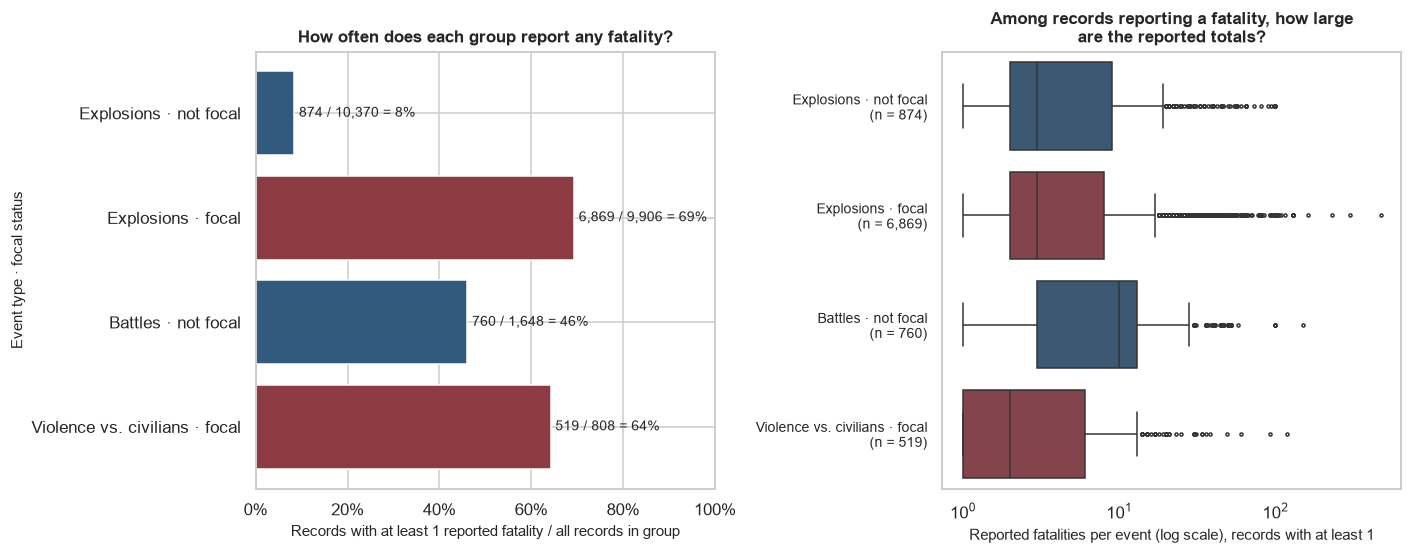

In [33]:
short = {"Explosions/Remote violence": "Explosions", "Violence against civilians": "Violence vs. civilians"}
political["group"] = (political.event_type.map(lambda t: short.get(t, t))
                      + np.where(political.focal_event, " · focal", " · not focal"))

g5 = political.groupby("group").fatalities
t5 = pd.DataFrame({"n": g5.size(), "share_with_fatality": g5.apply(lambda s: (s > 0).mean()),
                   "events_with_fatality": g5.apply(lambda s: (s > 0).sum()),
                   "median_if_any": g5.apply(lambda s: s[s > 0].median()),
                   "q1_if_any": g5.apply(lambda s: s[s > 0].quantile(0.25)),
                   "q3_if_any": g5.apply(lambda s: s[s > 0].quantile(0.75)),
                   "max": g5.max()}).sort_values("n", ascending=False)
t5["shown_in_chart"] = t5.n >= 30
display(t5.round(3))

order = [g for g in t5.index[t5.n >= 30]]
palette5 = {g: (C_FOCAL if g.endswith("· focal") else C_OTHER) for g in order}
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

ax = axes[0]
vals = t5.loc[order, "share_with_fatality"]
bars = ax.barh(order, vals, color=[palette5[g] for g in order])
for y, g in enumerate(order):
    r = t5.loc[g]
    ax.text(r.share_with_fatality + 0.01, y, f"{r.events_with_fatality:,.0f} / {r.n:,.0f} = {r.share_with_fatality:.0%}", va="center", fontsize=9)
ax.invert_yaxis(); ax.set_xlim(0, 1.0); ax.grid(axis="x")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Records with at least 1 reported fatality / all records in group")
ax.set_ylabel("Event type · focal status")
ax.set_title("How often does each group report any fatality?")

ax = axes[1]
sub = political[political.group.isin(order) & (political.fatalities > 0)]
sns.boxplot(data=sub, x="fatalities", y="group", hue="group", order=order, hue_order=order,
            palette=palette5, legend=False, orient="h", fliersize=2, linewidth=1, ax=ax)
ax.set_xscale("log")
ax.set_yticks(range(len(order)))
ax.set_yticklabels([f"{g}\n(n = {int((sub.group == g).sum()):,})" for g in order], fontsize=9)
ax.set_xlabel("Reported fatalities per event (log scale), records with at least 1")
ax.set_ylabel("")
ax.set_title("Among records reporting a fatality, how large\nare the reported totals?")
plt.tight_layout()
plt.show()

**Interpretation.** Within Explosions, 69% of focal records (6,869 of 9,906) report at least one fatality against 8% of non-focal ones (874 of 10,370), yet among records that do report a fatality the typical total is the same (median 3 in both); Battles have the largest typical totals (median 10, n = 760) and Violence against civilians the smallest (median 2, n = 519) (BQ2). So the focal group differs mainly in how often a fatality is reported rather than in how large it is, and every comparison depends on whether a fatality was recorded at all.

### 3.5 Location precision and focal share, stratified by period (BQ5)

**Question.** Does the focal share depend on how precisely ACLED coded the location? Precision (1 = most precise) is a quality category, not a distance. A precision difference can reflect documentation practices or coverage rather than a real difference in events, and the earlier period has very few records, so the comparison is made *within* each period. Bars with fewer than 30 records are hatched.

n  focal  focal_share
period             geo_precision                           
Before Oct 7, 2023 1                120     26        0.217
                   2                261     37        0.142
                   3                  8      0        0.000
Oct 7, 2023 onward 1              12704   7577        0.596
                   2               9583   3040        0.317
                   3                 77     34        0.442

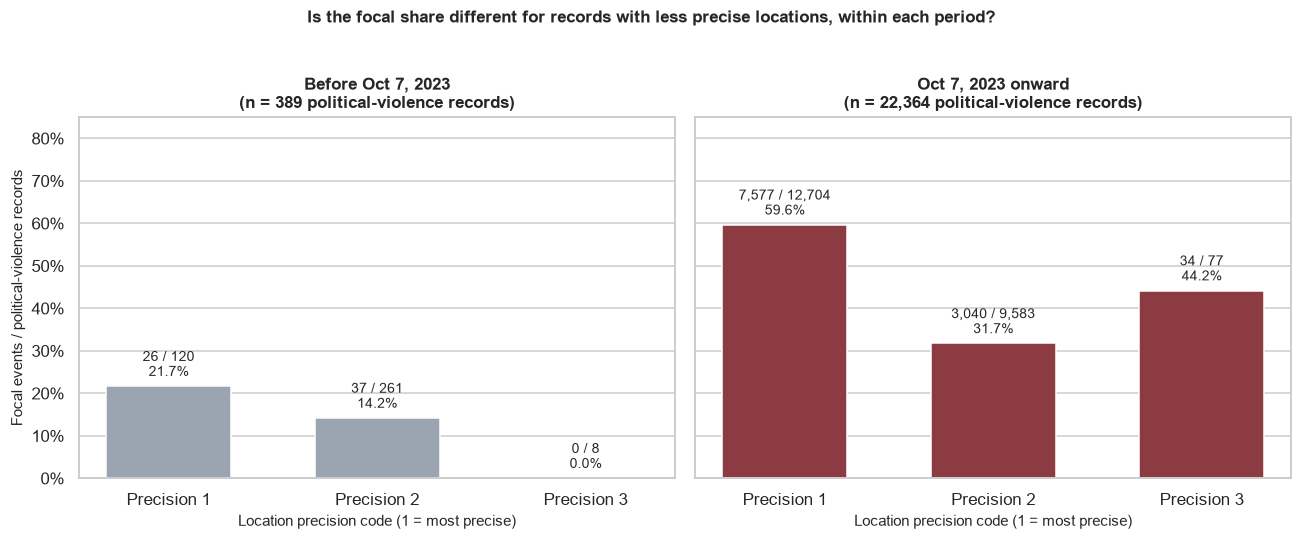

Oct 7 onward: focal share by district and precision (precision 3 omitted, n < 70 in every district)


,"n, precision 1","n, precision 2","focal share, precision 1","focal share, precision 2"
admin2,,,,
Deir El Balah,2537,1823,0.672,0.315
Gaza City,4095,2740,0.617,0.326
Khan Yunis,2867,2028,0.555,0.346
North Gaza,1845,1431,0.562,0.202
Rafah,1360,1560,0.529,0.373


Oct 7 onward, Explosions/Remote violence only


,n,focal,focal_share
geo_precision,,,
1,11523,7222,0.627
2,8414,2637,0.313
3,41,8,0.195


In [34]:
t6 = (political.groupby(["period", "geo_precision"], observed=True)
      .agg(n=("event_id_cnty", "size"), focal=("focal_event", "sum")))
t6["focal_share"] = t6.focal / t6.n
display(t6.round({"focal_share": 3}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, period, col in zip(axes, [BEFORE, AFTER], [C_GREY, C_FOCAL]):
    d = t6.loc[period].reindex([1, 2, 3])
    bars = ax.bar([f"Precision {k}" for k in d.index], d.focal_share, color=col, width=0.6)
    for b, (_, r) in zip(bars, d.iterrows()):
        if r.n < 30:
            b.set_hatch("//"); b.set_alpha(0.55)
        ax.text(b.get_x() + b.get_width() / 2, r.focal_share + 0.015,
                f"{r.focal:,.0f} / {r.n:,.0f}\n{r.focal_share:.1%}", ha="center", va="bottom", fontsize=9)
    ax.set_ylim(0, 0.85)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.set_xlabel("Location precision code (1 = most precise)")
    ax.set_title(f"{period}\n(n = {int(d.n.sum()):,} political-violence records)")
axes[0].set_ylabel("Focal events / political-violence records")
fig.suptitle("Is the focal share different for records with less precise locations, within each period?",
             fontsize=11, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# Robustness: does the precision 1 vs 2 gap survive inside each district and inside Explosions? (Oct 7 onward)
post_pol = political[political.period == AFTER]
by_district = post_pol[post_pol.geo_precision.isin([1, 2])].groupby(["admin2", "geo_precision"], observed=True).focal_event.agg(["size", "mean"]).unstack()
by_district.columns = [f"{'n' if a == 'size' else 'focal share'}, precision {b}" for a, b in by_district.columns]
print("Oct 7 onward: focal share by district and precision (precision 3 omitted, n < 70 in every district)")
display(by_district.round(3))
expl = post_pol[post_pol.event_type == "Explosions/Remote violence"]
print("Oct 7 onward, Explosions/Remote violence only")
display(expl.groupby("geo_precision", observed=True).focal_event.agg(n="size", focal="sum", focal_share="mean").round(3))

**Interpretation.** From Oct 7 onward the focal share is 59.6% for precision 1 (7,577 of 12,704) and 31.7% for precision 2 (3,040 of 9,583); before Oct 7 the same ordering appears at lower levels (21.7% vs. 14.2%), and precision 3 has too few records to read (8 and 77) (BQ5). The precision 1 vs. 2 gap holds inside all five districts (for example Deir El Balah 67.2% vs. 31.5%) and within Explosions (62.7% vs. 31.3%), so neither district nor event type explains it alone; these fields cannot tell us whether it reflects documentation practice, coverage or something else, which makes the precision-1 sensitivity run in Phase 4 important.

### 3.6 Recorded actor labels and sub-event types among focal events (BQ2)

**Question.** Which recorded `actor1` labels appear in focal events, and with which sub-event types? The focal rule requires "Civilians (Palestine)" in one actor field, so we first check where that label sits. Labels describe ACLED coding and are not verified roles. The five most frequent `actor1` labels are shown individually and the rest are grouped, with the number of grouped labels stated. Original labels are not merged.

Focal events: 10714
actor2 == 'Civilians (Palestine)': 10714 | actor2 blank: 0 | actor1 == 'Civilians (Palestine)': 0
Distinct actor1 labels among focal events: 14

Event type vs. sub-event type among focal events


event_type,Explosions/Remote violence,Violence against civilians
sub_event_type,,
Abduction/forced disappearance,0,15
Air/drone strike,8420,0
Attack,0,792
Remote explosive/landmine/IED,44,0
Sexual violence,0,1
Shelling/artillery/missile attack,1442,0


sub_event_type,Air/drone strike,Shelling/artillery/missile attack,Attack,Remote explosive/landmine/IED,Abduction/forced disappearance,Sexual violence
"Military Forces of Israel (2022-) (n = 10,493)",8392,1436,606,43,15,1
Sahm Unit (n = 90),0,0,90,0,0,0
Military Forces of Israel (2021-2022) (n = 36),26,2,8,0,0,0
Hamas Movement (n = 36),0,1,35,0,0,0
Unidentified Armed Group (Palestine) (n = 28),1,1,25,1,0,0
All other actor1 labels (9 labels) (n = 31),1,2,28,0,0,0


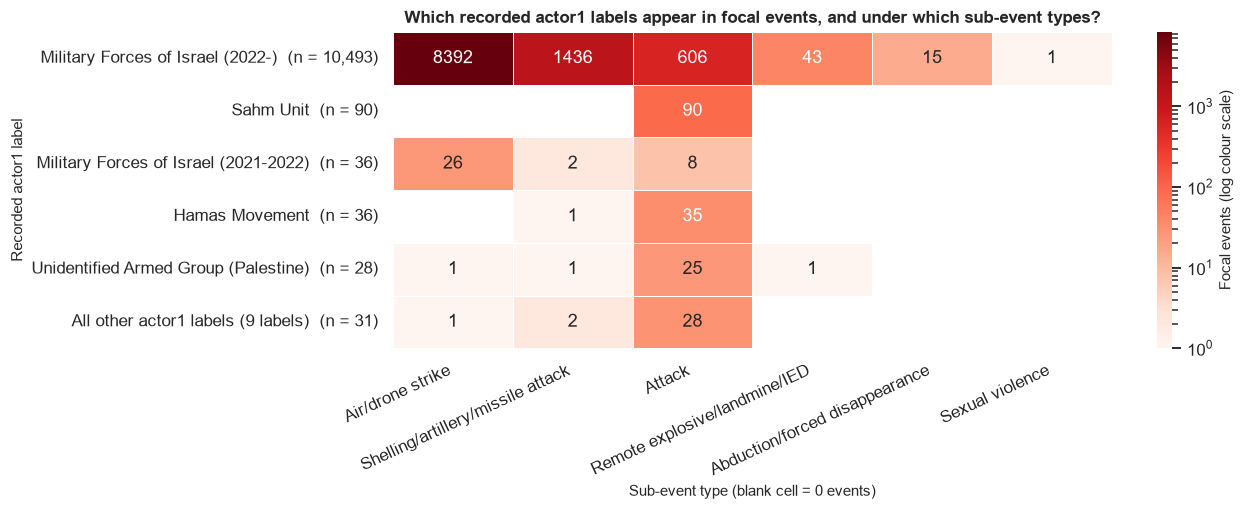

In [35]:
focal = master.loc[master.focal_event].copy()
print("Focal events:", len(focal))
print("actor2 == 'Civilians (Palestine)':", int((focal.actor2 == "Civilians (Palestine)").sum()),
      "| actor2 blank:", int(focal.actor2.isna().sum()),
      "| actor1 == 'Civilians (Palestine)':", int((focal.actor1 == "Civilians (Palestine)").sum()))
print("Distinct actor1 labels among focal events:", focal.actor1.nunique())
print("\nEvent type vs. sub-event type among focal events")
display(pd.crosstab(focal.sub_event_type, focal.event_type))

ct = pd.crosstab(focal.actor1, focal.sub_event_type)
totals = ct.sum(axis=1).sort_values(ascending=False)
TOP_N = 5
keep = totals.index[:TOP_N]
ct_show = ct.loc[keep].copy()
ct_show.loc[f"All other actor1 labels ({len(totals) - TOP_N} labels)"] = ct.loc[~ct.index.isin(keep)].sum()
ct_show = ct_show[ct_show.sum().sort_values(ascending=False).index]
ct_show.index = [f"{i}  (n = {n:,})" for i, n in ct_show.sum(axis=1).items()]
display(ct_show)

fig, ax = plt.subplots(figsize=(12, 4.8))
sns.heatmap(ct_show.where(ct_show > 0), annot=ct_show.astype(int).astype(str), fmt="",
            cmap="Reds", norm=LogNorm(vmin=1, vmax=ct_show.to_numpy().max()),
            linewidths=0.5, linecolor="white", cbar_kws={"label": "Focal events (log colour scale)"}, ax=ax)
ax.grid(False)
ax.set_xlabel("Sub-event type (blank cell = 0 events)")
ax.set_ylabel("Recorded actor1 label")
ax.set_title("Which recorded actor1 labels appear in focal events, and under which sub-event types?")
plt.setp(ax.get_xticklabels(), rotation=25, ha="right")
plt.tight_layout()
plt.show()

**Interpretation.** All 10,714 focal events carry "Civilians (Palestine)" in `actor2` and none in `actor1`, so the actor view rests on `actor1`, where "Military Forces of Israel (2022-)" appears in 10,493 events (97.9%), mostly under Air/drone strike (8,420) and Shelling/artillery/missile attack (1,442); the Attack sub-event type (792 events) is where the other labels appear, such as Sahm Unit (90) and Hamas Movement (35) (BQ2). These are ACLED's recorded labels, not verified roles, and one label dominates so heavily that the other rows are hard to compare, so any statement about who did what needs the event notes.

## 4. Multivariate, grouped and temporal analysis

The unit of analysis changes in this section. Chart 7 uses event records, Charts 8 and 10 use district-weeks, and Charts 9 and 11 use Gaza-wide weeks. The district-week table leaves out the 4 events with no district (3 of them focal), so its focal total (10,648) is 3 below the Gaza-wide total (10,651).

### 4.1 Event type, period and focal status together (BQ1, BQ2)

**Question.** Did the mix of recorded event types change between the periods, and did the focal share *within* a type change? The left panel shows composition (each bar sums to 100% of that period's political-violence records). The right panel shows the focal share for the only two event types that contain focal events. Counts for every type, including the very small ones, are in the table.

records  focal  focal_share
period             event_type                                             
Before Oct 7, 2023 Battles                          55      0        0.000
                   Explosions/Remote violence      298     39        0.131
                   Protests                          7      0        0.000
                   Riots                             5      0        0.000
                   Violence against civilians       24     24        1.000
Oct 7, 2023 onward Battles                        1593      0        0.000
                   Explosions/Remote violence    19978   9867        0.494
                   Riots                             3      0        0.000
                   Violence against civilians      790    784        0.992

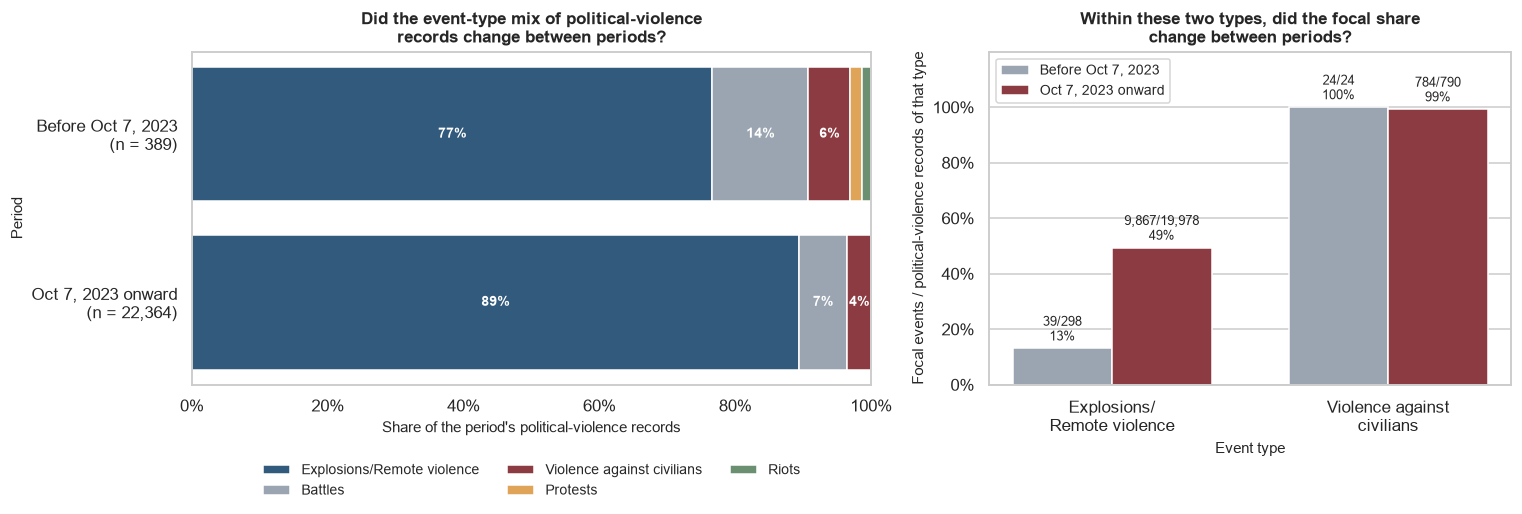

In [36]:
type_order = ["Explosions/Remote violence", "Battles", "Violence against civilians", "Protests", "Riots"]
t7 = (political.groupby(["period", "event_type"])
      .agg(records=("event_id_cnty", "size"), focal=("focal_event", "sum")))
t7["focal_share"] = t7.focal / t7.records
display(t7.round({"focal_share": 3}))

comp = (pd.crosstab(political.period, political.event_type)
        .reindex(index=[BEFORE, AFTER], columns=type_order, fill_value=0))
comp_share = comp.div(comp.sum(axis=1), axis=0)
type_colors = dict(zip(type_order, ["#315A7D", "#9AA5B1", "#8D3B42", "#E0A458", "#6B8F71"]))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
for i, period in enumerate([BEFORE, AFTER]):
    left = 0
    for t in type_order:
        wdt = comp_share.loc[period, t]
        ax.barh(i, wdt, left=left, color=type_colors[t], edgecolor="white", label=t if i == 0 else None)
        if wdt >= 0.03:
            ax.text(left + wdt / 2, i, f"{wdt:.0%}", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
        left += wdt
ax.set_yticks([0, 1])
ax.set_yticklabels([f"{p}\n(n = {int(comp.loc[p].sum()):,})" for p in [BEFORE, AFTER]])
ax.invert_yaxis(); ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Share of the period's political-violence records")
ax.set_ylabel("Period")
ax.set_title("Did the event-type mix of political-violence\nrecords change between periods?")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False)

ax = axes[1]
two = ["Explosions/Remote violence", "Violence against civilians"]
xs = np.arange(len(two)); w = 0.36
for j, (period, col) in enumerate([(BEFORE, C_GREY), (AFTER, C_FOCAL)]):
    vals = [t7.loc[(period, t), "focal_share"] for t in two]
    bars = ax.bar(xs + (j - 0.5) * w, vals, w, color=col, label=period)
    for b, t in zip(bars, two):
        r = t7.loc[(period, t)]
        ax.text(b.get_x() + b.get_width() / 2, r.focal_share + 0.015, f"{r.focal:,.0f}/{r.records:,.0f}\n{r.focal_share:.0%}",
                ha="center", va="bottom", fontsize=8.5)
ax.set_xticks(xs); ax.set_xticklabels(["Explosions/\nRemote violence", "Violence against\ncivilians"])
ax.set_ylim(0, 1.2); ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Event type")
ax.set_ylabel("Focal events / political-violence records of that type")
ax.set_title("Within these two types, did the focal share\nchange between periods?")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

**Interpretation.** Explosions/Remote violence grows from 77% (298 of 389) to 89% (19,978 of 22,364) of political-violence records while Battles fall from 14% to 7%; within types, the focal share of Explosions rises from 13.1% (39 of 298) to 49.4% (9,867 of 19,978), while Violence against civilians stays near 100% in both periods (24 of 24, then 784 of 790) (BQ1, BQ2). The rise in the overall focal share is therefore carried by Explosions/Remote violence, but its earlier base of 298 records is small and Protests and Riots are too rare (12 records before, 3 after) to show.

### 4.2 Actor, sub-event type and district at a glance: see Chart 6

The actor view is already covered by Chart 6, so we do not repeat it here.

### 4.3 District by week: where and when are focal counts high? (BQ4)

**Question.** Which districts have persistent or sudden high-count weeks? Every district has a row for every week; weeks with no recorded focal events stay in the grid with value 0. The final partial week is greyed out and left out of the colour scale. This chart shows counts, which reflect volume; Chart 10 shows shares.

,focal,political,median_weekly_focal,max_weekly_focal,weeks_without_political,focal_share
admin2,,,,,,
Gaza City,3451,6903,30.0,102,0,0.500
Khan Yunis,2292,4898,21.5,64,0,0.468
Deir El Balah,2278,4361,22.0,44,0,0.522
North Gaza,1325,3277,9.0,61,3,0.404
Rafah,1302,2921,10.0,31,0,0.446


Highest district-weeks by focal count


,admin2,week_start,focal_events,political_events,focal_share
108,Gaza City,2023-11-04,102,156,0.654
107,Gaza City,2023-10-28,92,131,0.702
205,Gaza City,2025-09-13,84,113,0.743
204,Gaza City,2025-09-06,79,97,0.814
206,Gaza City,2025-09-20,77,131,0.588
106,Gaza City,2023-10-21,75,100,0.750


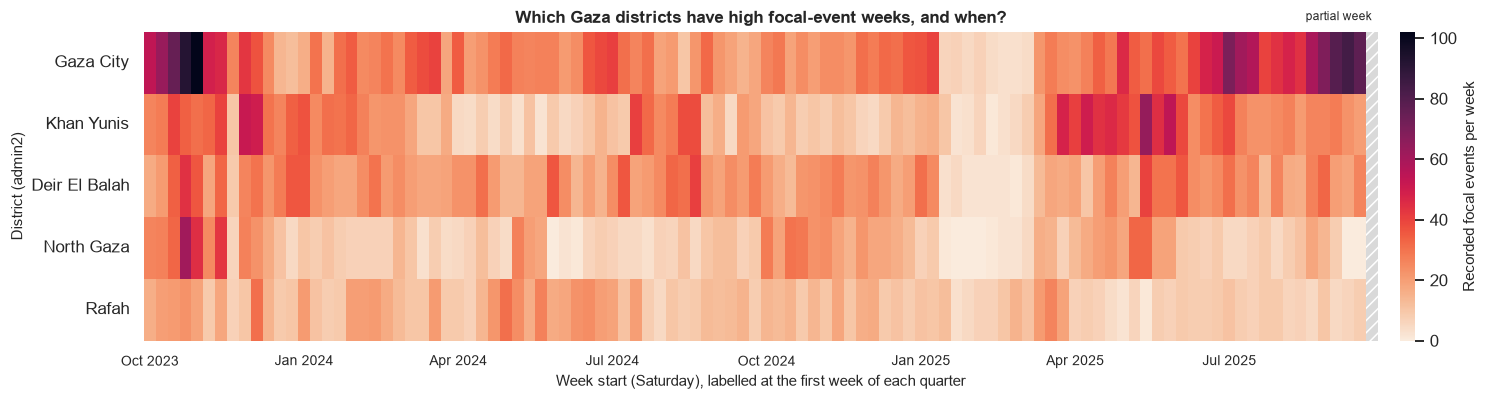

In [37]:
dw = district_week.copy()
dist_order = dw.groupby("admin2").focal_events.sum().sort_values(ascending=False).index
heat = dw.pivot(index="admin2", columns="week_start", values="focal_events").loc[dist_order].astype(float)
complete = dw.drop_duplicates("week_start").set_index("week_start").complete_week.reindex(heat.columns).to_numpy()
heat_plot = heat.copy()
heat_plot.loc[:, ~complete] = np.nan  # keep the partial week out of the colour scale

dist_summary = dw.groupby("admin2").agg(focal=("focal_events", "sum"), political=("political_events", "sum"),
                                         median_weekly_focal=("focal_events", "median"),
                                         max_weekly_focal=("focal_events", "max"),
                                         weeks_without_political=("political_events", lambda s: int((s == 0).sum()))).loc[dist_order]
dist_summary["focal_share"] = dist_summary.focal / dist_summary.political
display(dist_summary.round({"focal_share": 3}))
print("Highest district-weeks by focal count")
display(dw.nlargest(6, "focal_events")[["admin2", "week_start", "focal_events", "political_events", "focal_share"]].round({"focal_share": 3}))

fig, ax = plt.subplots(figsize=(15, 3.8))
sns.heatmap(heat_plot, cmap="rocket_r", xticklabels=False, cbar_kws={"label": "Recorded focal events per week", "pad": 0.015}, ax=ax)
for j in np.where(~complete)[0]:
    ax.add_patch(Rectangle((j, 0), 1, len(heat), facecolor="#D9D9D9", edgecolor="none", hatch="///"))
    ax.text(j + 0.5, -0.15, "partial week", ha="right", va="bottom", fontsize=8)
first_of_quarter = ~pd.Series(pd.PeriodIndex(heat.columns, freq="Q")).duplicated().to_numpy()
pos = np.where(first_of_quarter)[0]
ax.set_xticks(pos + 0.5)
ax.set_xticklabels(heat.columns[pos].strftime("%b %Y"), rotation=0, fontsize=9)
ax.grid(False)
ax.set_xlabel("Week start (Saturday), labelled at the first week of each quarter")
ax.set_ylabel("District (admin2)")
ax.set_title("Which Gaza districts have high focal-event weeks, and when?")
plt.tight_layout()
plt.show()

**Interpretation.** Gaza City holds the six highest district-weeks (102 focal events in the week of Nov 4, 2023, and 77 to 84 in each of three weeks in September 2025), and every district turns pale in the same stretch of early 2025 (BQ4). Counts reflect volume as well as focus (Gaza City records 6,903 political-violence records against 2,921 in Rafah), the final partial week is excluded, and a zero cell means zero recorded events, so Chart 10 is needed to read the share.

### 4.4 Gaza-wide weekly counts and share (BQ4)

**Question.** How do weekly focal counts and the focal share move over time, and are the two moving together? The top panel shows counts, the bottom panel shows the share, on the same week axis. The hollow marker is the incomplete final week. The shaded band marks the five weeks with the lowest focal counts; we describe them and do not explain them, because the files hold no source for the cause.

Five lowest focal-count weeks: ['2025-01-25', '2025-02-01', '2025-02-08', '2025-02-15', '2025-02-22']


,week_start,recorded_events,political_events,focal_events,focal_share
68,2025-01-25,31,27,17,0.630
69,2025-02-01,23,22,15,0.682
70,2025-02-08,42,33,23,0.697
71,2025-02-15,43,40,15,0.375
72,2025-02-22,42,38,20,0.526


Mean weekly focal events by quarter (complete weeks)


,focal_events,political_events
week_start,,
2023Q4,152.6,290.6
2024Q1,96.5,265.6
2024Q2,84.5,228.5
2024Q3,91.9,212.5
2024Q4,91.6,201.5
2025Q1,54.2,100.7
2025Q2,126.7,221.8
2025Q3,124.8,204.7


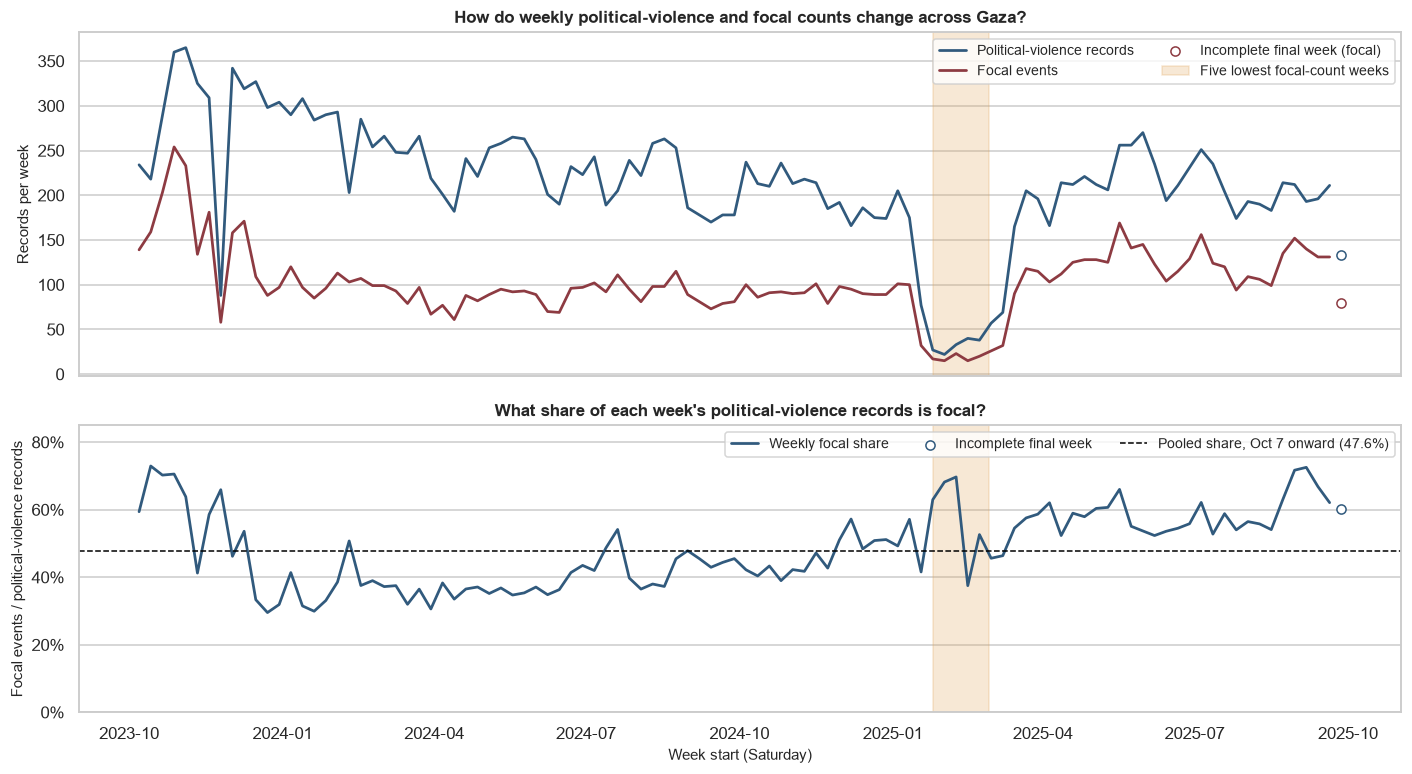

In [38]:
gw = gaza_week.sort_values("week_start").copy()
low5 = gw.nsmallest(5, "focal_events")
low_span = (low5.week_start.min(), low5.week_end.max())
partial = gw[~gw.complete_week]
full = gw[gw.complete_week]
post_share = master.loc[master.period == AFTER, "focal_event"].sum() / political.loc[political.period == AFTER].shape[0]
print("Five lowest focal-count weeks:", [d.date().isoformat() for d in sorted(low5.week_start)])
display(low5.sort_values("week_start")[["week_start", "recorded_events", "political_events", "focal_events", "focal_share"]].round({"focal_share": 3}))
print("Mean weekly focal events by quarter (complete weeks)")
display(full.groupby(full.week_start.dt.to_period("Q"))[["focal_events", "political_events"]].mean().round(1))

fig, axes = plt.subplots(2, 1, figsize=(13, 7.2), sharex=True, gridspec_kw={"height_ratios": [1.2, 1]})
ax = axes[0]
ax.plot(full.week_start, full.political_events, color=C_OTHER, lw=1.8, label="Political-violence records")
ax.plot(full.week_start, full.focal_events, color=C_FOCAL, lw=1.8, label="Focal events")
ax.scatter(partial.week_start, partial.focal_events, facecolor="white", edgecolor=C_FOCAL, zorder=5, label="Incomplete final week (focal)")
ax.scatter(partial.week_start, partial.political_events, facecolor="white", edgecolor=C_OTHER, zorder=5)
ax.axvspan(*low_span, color="#E0A458", alpha=0.25, label="Five lowest focal-count weeks")
ax.set_ylabel("Records per week")
ax.set_title("How do weekly political-violence and focal counts change across Gaza?")
ax.legend(loc="upper right", ncol=2)

ax = axes[1]
ax.plot(full.week_start, full.focal_share, color=C_OTHER, lw=1.8, label="Weekly focal share")
ax.scatter(partial.week_start, partial.focal_share, facecolor="white", edgecolor=C_OTHER, zorder=5, label="Incomplete final week")
ax.axhline(post_share, color="black", ls="--", lw=1, label=f"Pooled share, Oct 7 onward ({post_share:.1%})")
ax.axvspan(*low_span, color="#E0A458", alpha=0.25)
ax.set_ylim(0, 0.85)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylabel("Focal events / political-violence records")
ax.set_xlabel("Week start (Saturday)")
ax.set_title("What share of each week's political-violence records is focal?")
ax.legend(loc="upper right", ncol=3)
plt.tight_layout()
plt.show()

**Interpretation.** Weekly focal events peak at 254 in the week of Oct 28, 2023, run between 61 and 120 through 2024, fall to 15 to 23 in the five lowest weeks (week starts Jan 25 to Feb 22, 2025), and average about 125 per week in Q2 and Q3 2025; the focal share ranges from 30% to 73% and sits above the pooled 47.6% in 17% of 2024 weeks but 89% of 2025 weeks (BQ4). The share does not fall with the counts in the low weeks (38% to 70%), so counts and shares must be read separately, and with only 22 to 40 political-violence records in those weeks the share is volatile; the cause of the dip cannot be read from these files.

### 4.5 District focal share with denominators (BQ4)

**Question.** After accounting for how much political violence each district records, do districts differ in focal share, and is the share stable week to week? Each panel shows the weekly share (thin line, gaps where the denominator is zero), a 4-week pooled share (focal events over political-violence records in the same four weeks), and the district's overall share (dashed). The incomplete final week is left out. The panel titles and table carry the denominators.

,focal,political,undefined_weeks,overall_share
admin2,,,,
Gaza City,3411,6825,0,0.500
Khan Yunis,2278,4876,0,0.467
Deir El Balah,2257,4335,0,0.521
North Gaza,1325,3277,2,0.404
Rafah,1297,2914,0,0.445


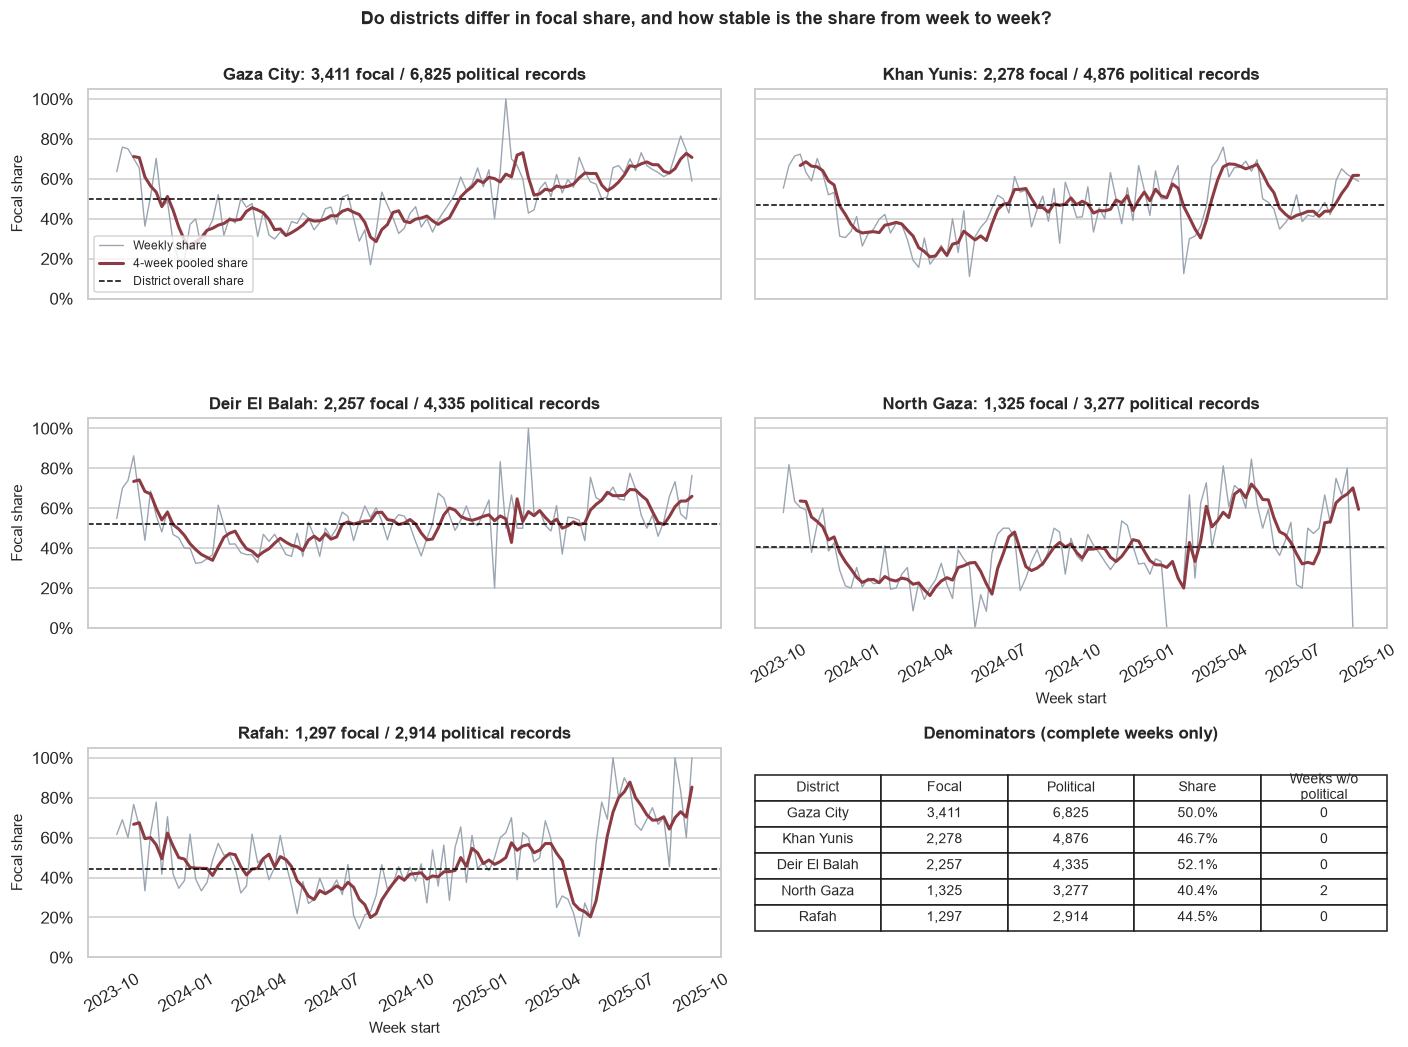

In [39]:
dwc = district_week[district_week.complete_week].sort_values(["admin2", "week_start"]).copy()
roll = lambda col: dwc.groupby("admin2")[col].transform(lambda s: s.rolling(4, min_periods=4).sum())
dwc["focal_4w"], dwc["political_4w"] = roll("focal_events"), roll("political_events")
dwc["share_4w"] = dwc.focal_4w / dwc.political_4w.where(dwc.political_4w > 0)

tbl = (dwc.groupby("admin2").agg(focal=("focal_events", "sum"), political=("political_events", "sum"),
                                  undefined_weeks=("focal_share", lambda s: int(s.isna().sum()))).loc[dist_order])
tbl["overall_share"] = tbl.focal / tbl.political
display(tbl.round({"overall_share": 3}))

fig, axes = plt.subplots(3, 2, figsize=(13, 9.5), sharex=True, sharey=True)
axes = axes.ravel()
for ax, dname in zip(axes, dist_order):
    d = dwc[dwc.admin2 == dname]
    ax.plot(d.week_start, d.focal_share, color=C_GREY, lw=0.9, label="Weekly share")
    ax.plot(d.week_start, d.share_4w, color=C_FOCAL, lw=2, label="4-week pooled share")
    ax.axhline(tbl.loc[dname, "overall_share"], color="black", ls="--", lw=1, label="District overall share")
    ax.set_title(f"{dname}: {tbl.loc[dname, 'focal']:,.0f} focal / {tbl.loc[dname, 'political']:,.0f} political records")
    ax.set_ylim(0, 1.05)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.tick_params(axis="x", labelrotation=30)
axes[0].legend(loc="lower left", fontsize=8)
axes[3].tick_params(axis="x", labelbottom=True, labelrotation=30)
for ax in axes[-3:-1]:
    ax.set_xlabel("Week start")
for ax in axes[::2][:3]:
    ax.set_ylabel("Focal share")
# Last panel: the denominators as a table
ax = axes[-1]; ax.axis("off")
cell = [[i, f"{r.focal:,.0f}", f"{r.political:,.0f}", f"{r.overall_share:.1%}", int(r.undefined_weeks)] for i, r in tbl.iterrows()]
t = ax.table(cellText=cell, colLabels=["District", "Focal", "Political", "Share", "Weeks w/o\npolitical"], loc="center", cellLoc="center")
t.auto_set_font_size(False); t.set_fontsize(9); t.scale(1, 1.6)
ax.set_title("Denominators (complete weeks only)")
fig.suptitle("Do districts differ in focal share, and how stable is the share from week to week?", fontsize=12, fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()

**Interpretation.** Overall focal share runs from 40.4% in North Gaza (1,325 of 3,277) to 52.2% in Deir El Balah (2,278 of 4,361), with Gaza City at 50.0% (3,451 of 6,903); the 4-week share starts high in every district, falls below the district average for most of 2024 (Gaza City is above it in only 8% of 2024 weeks), and from June 2025 Gaza City and Rafah stay above it in every week (BQ4). Rafah swings most (20.0% in the week of Aug 17, 2024 to 87.8% on Jul 5, 2025), and weekly district shares rest on small denominators (North Gaza has 2 weeks with no political-violence records), so single-week spikes in share should not be over-read.

### 4.6 Correlation and association (BQ4, BQ5)

**Question.** Which weekly measures move together, and which categorical fields are associated? Two different measures are needed because the variable types differ.

- **Left, Spearman rank correlation** between weekly Gaza-wide measures (complete weeks only). † marks pairs that are related by construction (a subset or a denominator relationship, or overlapping windows), so a high value there is expected and says little. ‡ marks a variable correlated with its own earlier values (serial dependence). The sample size is lower for the lag columns because early weeks have no eligible history.
- **Right, Cramér's V** between categorical fields of political-violence records (0 = no association, 1 = perfect). Sub-event type is nested inside event type, so that pair is 1.0 by definition. V can be inflated when many cells are sparse, so the share of sparse cells is shown below the chart.

Neither measure shows cause.

Weekly Spearman: 103 complete weeks; pairwise n ranges from 99 to 103


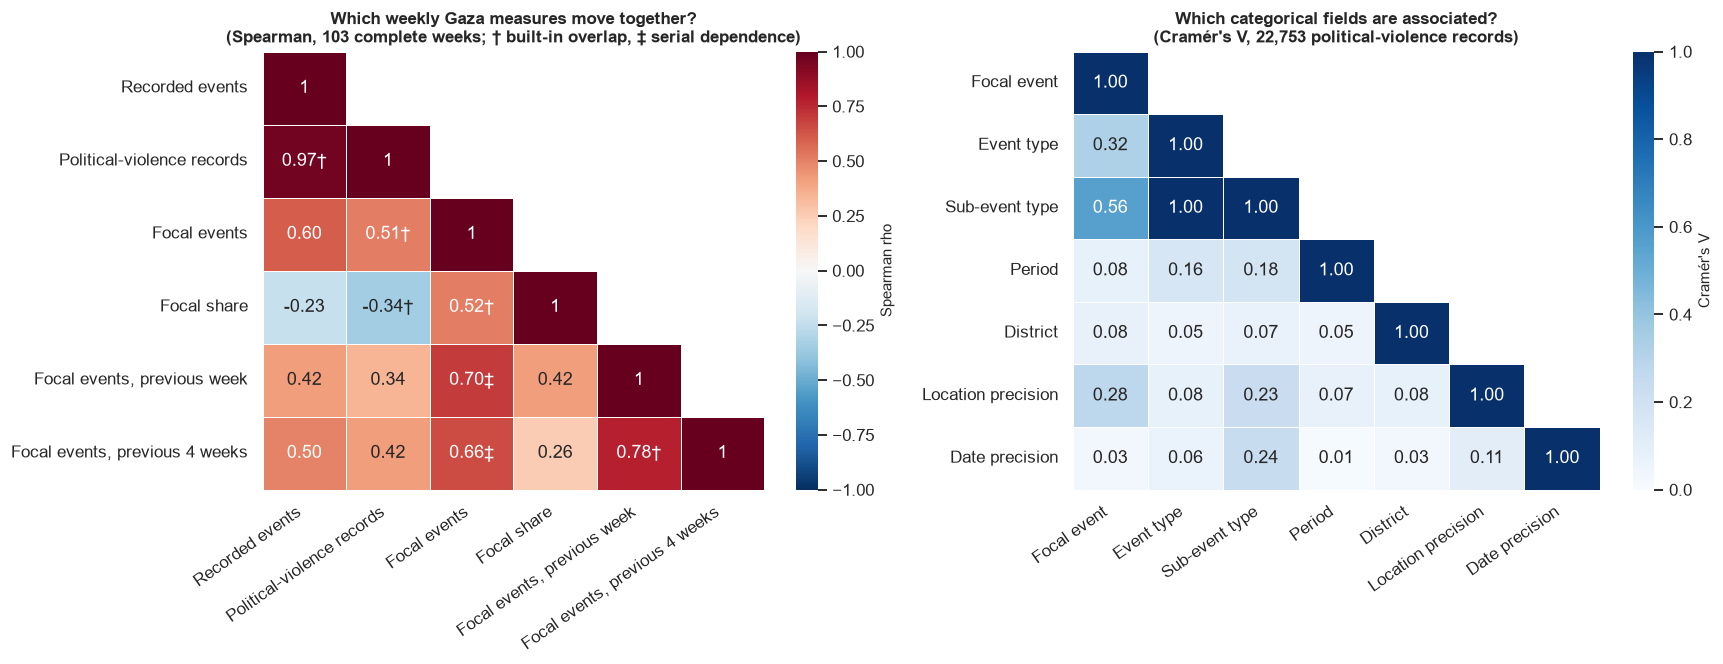

Share of contingency-table cells with expected count < 5 (sparse cells inflate V)


C:\Users\USER\AppData\Local\Temp\ipykernel_32364\90010495.py:55: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  display((sparse * 100).round(0).fillna("").astype(str).replace({"nan": ""}))


,Focal event,Event type,Sub-event type,Period,District,Location precision,Date precision
Focal event,,,,,,,
Event type,40.0,,,,,,
Sub-event type,45.0,67.0,,,,,
Period,0.0,20.0,41.0,,,,
District,0.0,40.0,55.0,0.0,,,
Location precision,0.0,47.0,55.0,17.0,0.0,,
Date precision,17.0,40.0,61.0,33.0,33.0,33.0,


In [40]:
# ---- Left: Spearman on weekly Gaza-wide numbers (complete weeks only) ----
wk_cols = ["recorded_events", "political_events", "focal_events", "focal_share", "previous_week_focal", "previous_four_weeks_focal"]
wk_lab = {"recorded_events": "Recorded events", "political_events": "Political-violence records", "focal_events": "Focal events",
          "focal_share": "Focal share", "previous_week_focal": "Focal events, previous week", "previous_four_weeks_focal": "Focal events, previous 4 weeks"}
wk = gaza_week.loc[gaza_week.complete_week, wk_cols]
rho = wk.corr(method="spearman")
n_pair = wk.notna().astype(int).T.dot(wk.notna().astype(int))
mechanical = [{"recorded_events", "political_events"}, {"political_events", "focal_events"},
              {"focal_events", "focal_share"}, {"political_events", "focal_share"},
              {"previous_week_focal", "previous_four_weeks_focal"}]
serial = [{"focal_events", "previous_week_focal"}, {"focal_events", "previous_four_weeks_focal"}]
def mark(a, b):
    s = {a, b}
    return "†" if s in mechanical else ("‡" if s in serial else "")
annot_r = pd.DataFrame([[f"{rho.loc[a, b]:.2f}{mark(a, b)}" if a != b else "1" for b in wk_cols] for a in wk_cols], index=wk_cols, columns=wk_cols)
print(f"Weekly Spearman: {len(wk)} complete weeks; pairwise n ranges from {int(n_pair.to_numpy().min())} to {int(n_pair.to_numpy().max())}")

# ---- Right: Cramér's V (plain, uncorrected) on political-violence records ----
def cramers_v(a, b):
    ok = a.notna() & b.notna()
    ct = pd.crosstab(a[ok].astype(str), b[ok].astype(str))
    if min(ct.shape) < 2:
        return np.nan, np.nan
    chi2, _, _, expected = chi2_contingency(ct, correction=False)
    return np.sqrt(chi2 / (ct.to_numpy().sum() * (min(ct.shape) - 1))), (expected < 5).mean()

cat_vars = {"Focal event": political.focal_event, "Event type": political.event_type, "Sub-event type": political.sub_event_type,
            "Period": political.period, "District": political.admin2, "Location precision": political.geo_precision,
            "Date precision": political.time_precision}
names = list(cat_vars)
V = pd.DataFrame(np.nan, index=names, columns=names); sparse = V.copy()
for i, a in enumerate(names):
    for b in names[: i + 1]:
        if a == b:
            V.loc[a, b] = 1.0
        else:
            V.loc[a, b], sparse.loc[a, b] = cramers_v(cat_vars[a], cat_vars[b])

fig, axes = plt.subplots(1, 2, figsize=(16, 6.2), gridspec_kw={"width_ratios": [1, 1.05]})
sns.heatmap(rho, mask=np.triu(np.ones_like(rho, dtype=bool), k=1), annot=annot_r, fmt="", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            linewidths=0.5, linecolor="white", cbar_kws={"label": "Spearman rho"}, ax=axes[0])
for a_ in axes:
    a_.grid(False)
axes[0].set_xticklabels([wk_lab[c] for c in wk_cols], rotation=35, ha="right")
axes[0].set_yticklabels([wk_lab[c] for c in wk_cols], rotation=0)
axes[0].set_title(f"Which weekly Gaza measures move together?\n(Spearman, {len(wk)} complete weeks; † built-in overlap, ‡ serial dependence)")
sns.heatmap(V, mask=np.triu(np.ones_like(V, dtype=bool), k=1), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            linewidths=0.5, linecolor="white", cbar_kws={"label": "Cramér's V"}, ax=axes[1])
axes[1].set_xticklabels(names, rotation=35, ha="right"); axes[1].set_yticklabels(names, rotation=0)
axes[1].set_title(f"Which categorical fields are associated?\n(Cramér's V, {len(political):,} political-violence records)")
plt.tight_layout()
plt.show()

print("Share of contingency-table cells with expected count < 5 (sparse cells inflate V)")
display((sparse * 100).round(0).fillna("").astype(str).replace({"nan": ""}))

**Interpretation.** Weekly focal events move with recorded events (rho = 0.60) and with their own previous week (0.70) and previous four weeks (0.66), which supports using prior-week history as a feature in Phase 4 (BQ4); among categorical fields, focal status is moderately associated with sub-event type (V = 0.56), event type (0.32) and location precision (0.28) but weakly with period and district (0.08 each). Pairs marked † are related by construction (for example 0.97 between recorded events and political-violence records) and say little, the period value is held down by the very unequal group sizes (389 vs. 22,364 records), V is inflated where cells are sparse (see the table), and none of this shows cause.

## 5. Bivariate synthesis and carry-forward notes

This section preserves the written bivariate findings and cautions. The formal contingency tables, expected-count checks, and test conclusions appear in the Hypothesis Testing section.

**Bivariate synthesis and carry-forward notes.**

- **Hypothesis A inputs.** Political-violence records by period: before Oct 7, 2023 = 389 (63 focal, 16.2%); Oct 7 onward = 22,364 (10,651 focal, 47.6%). The smallest expected count is 183.2, so the sparse-cell concern does not arise for this table. The periods are 644 and 725 days long, and the Cramér's V for period × focal in the matrix is 0.08.
- **Hypothesis B inputs.** Focal share by event type: Violence against civilians 808 of 814 (99.3%), Explosions/Remote violence 9,906 of 20,276 (48.9%), Battles 0 of 1,648, Protests 0 of 7, Riots 0 of 8. The smallest expected count is 3.30 and 4 of 10 cells are below 5 (the Protests and Riots rows), so an asymptotic p-value should be replaced by a Monte Carlo or exact procedure, as Phase 2 did. Cramér's V for event type × focal is 0.32. Because the focal rule requires a civilian actor label, this association is partly built into the coding and should be described that way.
- **For the insights writer.** (1) The focal share rise is carried by Explosions/Remote violence (13.1% to 49.4%). (2) Focal records report a fatality far more often than other Explosions records (69% vs. 8%) but not larger totals when they do. (3) The precision 1 vs. 2 gap (59.6% vs. 31.7% after Oct 7) holds inside every district and within Explosions, so the precision-1 sensitivity run is warranted. (4) Weekly focal counts show strong week-to-week persistence (rho 0.70 with the previous week) and a visible low stretch in Jan to Feb 2025 that all five districts share; both matter for the anomaly-detection baseline. (5) Gaza City holds the six highest district-weeks, but district shares are noisy on small weekly denominators.
- **Carry-forward cautions.** `actor2` is constant among focal events, and one `actor1` label covers 97.9% of them. The district-week table is 3 focal events short of the Gaza-wide total by design. The final week (starting Sep 27, 2025) is incomplete and is excluded from Charts 8 to 11 colour scales, lines and correlations; it is marked in Chart 9.

### 4.1 Hypotheses and Test Plan

| Item | Hypothesis A | Hypothesis B |
| :--- | :--- | :--- |
| **Business question** | BQ1 | BQ2 |
| **Question** | Is the focal share of political-violence records different before and after Oct 7, 2023? | Does the focal share of political-violence records differ across recorded event types? |
| **Variables** (unit: one political-violence record) | Period (2 groups) by focal status (focal or not) | Event type (5 groups) by focal status (focal or not) |
| **H0** | The focal share is the same in both periods. | The focal share is the same in every event type. |
| **H1** | The focal share differs between the two periods. | The focal share differs for at least one event type. |
| **Test** | Pearson’s chi-square test of independence (categorical association; 2 × 2) | Chi-square test of independence with a Monte Carlo p-value (categorical association; 5 × 2) |
| **Why this test** | Both variables are categories, so we compare proportions. The Phase 3 preflight gave a smallest expected count of 183.17, so the ordinary large-sample test is valid. | The Phase 3 preflight gave a smallest expected count of 3.30 and 4 of 10 cells below 5 (the Protests and Riots rows), so the large-sample p-value is not reliable. We simulate the p-value as in Phase 2 and keep all five event types. |
| **Effect size** | Difference in shares, risk ratio, odds ratio and phi, with 95% intervals | Cramér's V and Pearson residuals |
| **Robustness checks** | Fisher exact test and continuity correction; the same comparison inside Explosions/Remote violence and inside Violence against civilians | Protests and Riots pooled so every expected count is at least 5; Violence against civilians compared directly with Explosions/Remote violence |

**Why a categorical association test.** Both questions compare categorical variables: period or event type against focal status. A chi-square test checks whether the observed category counts differ from the counts expected if the variables were independent. “Pearson” in Pearson’s chi-square names this test statistic; it does not mean Pearson’s *r*, which measures linear association between numeric variables. The weekly Spearman analysis in Phase 3 (Chart 11) addresses a different question—week-to-week persistence for Phase 4 models—and is not one of these tests.

**Decision rule.** We use alpha = 0.05 for each test. Because we run two primary tests we also report a Bonferroni-adjusted level of 0.025 (0.05 / 2); both conclusions are the same under either level. The robustness checks show how stable each result is. They are not extra hypotheses and we do not use them to claim new findings.

**Interpretation boundaries.**
- We describe **recorded ACLED events** and the project's own focal rule. The rule is a reproducible coding convention, not proof of intent, responsibility or legal classification.
- A zero means zero **recorded** events. It is not evidence that no harm occurred.
- With 22,753 records almost any difference gives a very small p-value, so we read the effect size and its interval first and the p-value second.
- Events are related across time and place, so records are not fully independent and the p-values are probably smaller than an independent sample would give. The tests are exploratory, as in Phase 3, and neither one shows cause.

The helper functions below keep the two tests consistent. `focal_table` builds each contingency table, `preflight` prints the smallest expected count (the check that decides which p-value procedure is valid), `wilson_ci` gives 95% intervals for the charts, and `fmt_p` prints very small p-values readably.

In [41]:
def focal_table(frame, by, order):
    """Focal / not-focal counts for each group in `order`. reindex keeps empty groups, and it reads
    [True, False] as column labels (a [True, False] list passed to .loc would be read as a boolean mask)."""
    tab = pd.crosstab(frame[by], frame.focal_event).reindex(index=order, columns=[True, False], fill_value=0)
    tab.columns = ["Focal", "Not focal"]
    return tab

def expected_counts(table):
    """Expected counts under independence: row total x column total / grand total."""
    t = np.asarray(table, dtype=float)
    return np.outer(t.sum(axis=1), t.sum(axis=0)) / t.sum()

def preflight(label, table):
    """Print the sparse-cell diagnostic that decides which p-value procedure is valid."""
    e = expected_counts(table)
    print(f"{label}: smallest expected count = {e.min():.2f}; cells below 5 = {(e < 5).sum()} of {e.size}")
    return e

def wilson_ci(k, n):
    """95% Wilson interval for a share; it stays inside 0 to 1 and works when k = 0 or k = n."""
    ci = binomtest(int(k), int(n)).proportion_ci(confidence_level=0.95, method="wilson")
    return ci.low, ci.high

def fmt_p(p, monte_carlo=False):
    """Readable p-value. Floating point underflows to 0.0 for very small chi-square p-values, and a
    Monte Carlo p-value cannot go below 1 / (N_RESAMPLES + 1)."""
    if monte_carlo:
        floor = 1 / (N_RESAMPLES + 1)
        return f"p < {floor:.5f}" if np.isclose(p, floor) else f"p = {p:.5f}"
    return "p < 1e-300" if p == 0 else f"p = {p:.2e}"

### 4.2 Hypothesis A: focal share before vs. after October 7, 2023 (BQ1)

**Question.** Is the focal share of political-violence records different before and after October 7, 2023?

**H0:** the focal share is the same in both periods. <br> 
**H1:** it differs. <br>
**Test:** Pearson’s chi-square test of independence (a categorical association test) on the 2 × 2 table of period by focal status, without continuity correction because every expected count is large. The periods are 644 and 725 days long, but a share is a ratio inside each period, so period length does not enter the test; it matters only for the per-week rates reported in Phase 3. We also report Fisher's exact test and the continuity-corrected test to show that the p-value does not depend on that choice.

In [42]:
period_table = focal_table(political, "period", [BEFORE, AFTER])
display(period_table.assign(Total=period_table.sum(axis=1),
                            Focal_share=(period_table.Focal / period_table.sum(axis=1)).round(3)))
preflight("A: period x focal", period_table)

tab_A = period_table.to_numpy()
chi2_A, p_A, dof_A, _ = chi2_contingency(tab_A, correction=False)   # Pearson chi-square, no continuity correction
p_A_yates = chi2_contingency(tab_A, correction=True)[1]             # sensitivity: with continuity correction
p_A_fisher = fisher_exact(tab_A)[1]                                 # sensitivity: exact test
n_A = tab_A.sum()
phi_A = np.sqrt(chi2_A / n_A)

# Effect sizes with 95% intervals (normal approximation; the ratios use the log scale)
(f_b, nf_b), (f_a, nf_a) = tab_A
n_b, n_a = f_b + nf_b, f_a + nf_a
share_b, share_a = f_b / n_b, f_a / n_a
diff = share_a - share_b
se_diff = np.sqrt(share_b * (1 - share_b) / n_b + share_a * (1 - share_a) / n_a)
rr = share_a / share_b
se_rr = np.sqrt((1 - share_a) / f_a + (1 - share_b) / f_b)
odds = (f_a * nf_b) / (f_b * nf_a)
se_or = np.sqrt(1 / f_a + 1 / nf_a + 1 / f_b + 1 / nf_b)

print(f"Pearson chi-square({dof_A}) = {chi2_A:,.2f}, {fmt_p(p_A)} (n = {n_A:,}, phi = {phi_A:.3f})")
print(f"Sensitivity: with continuity correction {fmt_p(p_A_yates)}; Fisher exact {fmt_p(p_A_fisher)}")
print(f"Focal share: {share_b:.1%} ({f_b:,} / {n_b:,}) before vs. {share_a:.1%} ({f_a:,} / {n_a:,}) from Oct 7 onward")
print(f"Difference = {diff * 100:+.1f} points (95% CI {(diff - Z * se_diff) * 100:+.1f} to {(diff + Z * se_diff) * 100:+.1f}); "
      f"risk ratio = {rr:.2f} ({rr * np.exp(-Z * se_rr):.2f} to {rr * np.exp(Z * se_rr):.2f}); "
      f"odds ratio = {odds:.2f} ({odds * np.exp(-Z * se_or):.2f} to {odds * np.exp(Z * se_or):.2f})")
decision_A = "Reject H0" if p_A < ALPHA / 2 else "Fail to reject H0"
print(f"Decision: {decision_A} (alpha = {ALPHA}, Bonferroni-adjusted to {ALPHA / 2} for the two primary tests)")

,Focal,Not focal,Total,Focal_share
period,,,,
"Before Oct 7, 2023",63,326,389,0.162
"Oct 7, 2023 onward",10651,11713,22364,0.476


A: period x focal: smallest expected count = 183.17; cells below 5 = 0 of 4
Pearson chi-square(1) = 151.60, p = 7.76e-35 (n = 22,753, phi = 0.082)
Sensitivity: with continuity correction p = 1.46e-34; Fisher exact p = 3.75e-38
Focal share: 16.2% (63 / 389) before vs. 47.6% (10,651 / 22,364) from Oct 7 onward
Difference = +31.4 points (95% CI +27.7 to +35.1); risk ratio = 2.94 (2.34 to 3.69); odds ratio = 4.71 (3.59 to 6.17)
Decision: Reject H0 (alpha = 0.05, Bonferroni-adjusted to 0.025 for the two primary tests)


**Interpretation.** We reject H0 (chi-square(1) = 151.60, p = 7.8e-35; Fisher exact p = 3.8e-38). The focal share is 16.2% (63 of 389 records) before Oct 7, 2023 and 47.6% (10,651 of 22,364) from Oct 7 onward, a rise of 31.4 percentage points (95% CI 27.7 to 35.1). A record from Oct 7 onward is about 2.9 times as likely to be focal (risk ratio 2.94, 95% CI 2.34 to 3.69; odds ratio 4.71, 95% CI 3.59 to 6.17) (BQ1). In plain terms, a gap this large would almost never appear by chance if the focal share were the same in both periods. Phi is only 0.08 because the two groups are very unequal in size (389 vs. 22,364 records, as noted in Phase 3), so the share difference and the odds ratio describe the size of the change better. The earlier share rests on 63 focal events, so its interval is wide (12.9% to 20.2%), and the test cannot separate a real change in events from a change in coding or reporting coverage.

#### 4.2.1 Does the rise hold inside event types? (BQ1, BQ2)

**Question.** The overall rise could come from a change in the event-type mix instead of a change inside event types. In Phase 3 (Chart 7) Explosions/Remote violence grows from 77% to 89% of records, and Battles never contain focal events. We therefore repeat the comparison inside the two event types that contain focal events. This is a robustness check, not a third hypothesis. We use the chi-square test when every expected count is at least 5 and Fisher's exact test otherwise, and groups with fewer than 30 records are marked in the chart.

,Before: focal / records,Before share,After: focal / records,After share,Smallest expected,Test,p-value
Event type,,,,,,,
Explosions/Remote violence,39 / 298,0.131,"9,867 / 19,978",0.494,145.59,Chi-square,p = 1.50e-35
Violence against civilians,24 / 24,1.000,784 / 790,0.992,0.18,Fisher exact,p = 1.00e+00


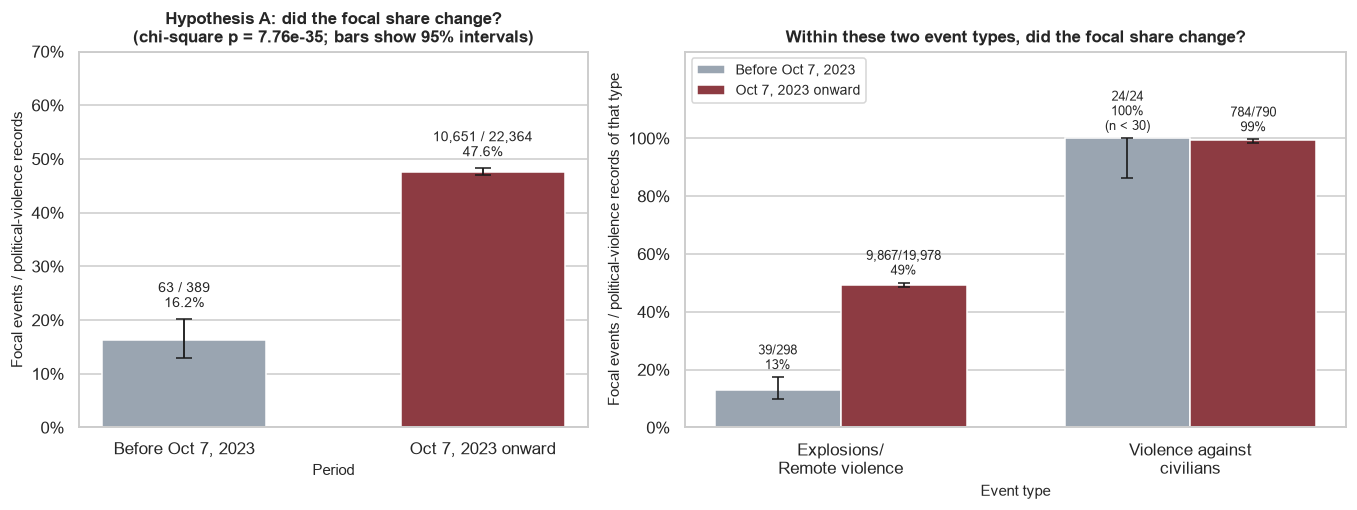

In [43]:
# Within each event type that contains focal events: is the period difference still there?
within_tabs, within_rows = {}, []
for etype in EVENT_TYPES[:2]:
    t = focal_table(political.loc[political.event_type == etype], "period", [BEFORE, AFTER]).to_numpy()
    within_tabs[etype] = t
    e_min = expected_counts(t).min()
    if e_min >= 5:   # the large-sample test is valid only when every expected count is at least 5
        test_name, p_val = "Chi-square", chi2_contingency(t, correction=False)[1]
    else:
        test_name, p_val = "Fisher exact", fisher_exact(t)[1]
    within_rows.append({"Event type": etype,
                        "Before: focal / records": f"{t[0, 0]:,} / {t[0].sum():,}", "Before share": t[0, 0] / t[0].sum(),
                        "After: focal / records": f"{t[1, 0]:,} / {t[1].sum():,}", "After share": t[1, 0] / t[1].sum(),
                        "Smallest expected": e_min, "Test": test_name, "p-value": fmt_p(p_val)})
display(pd.DataFrame(within_rows).set_index("Event type").round({"Before share": 3, "After share": 3, "Smallest expected": 2}))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), gridspec_kw={"width_ratios": [1, 1.3]})

# Left: the tested comparison, with 95% Wilson intervals
ax = axes[0]
shares = np.array([share_b, share_a])
cis = np.array([wilson_ci(f_b, n_b), wilson_ci(f_a, n_a)])
bars = ax.bar([BEFORE, AFTER], shares, color=[C_GREY, C_FOCAL], width=0.55,
              yerr=[shares - cis[:, 0], cis[:, 1] - shares], capsize=5, error_kw={"lw": 1.2})
for b, k, n, s, hi in zip(bars, (f_b, f_a), (n_b, n_a), shares, cis[:, 1]):
    ax.text(b.get_x() + b.get_width() / 2, hi + 0.015, f"{k:,} / {n:,}\n{s:.1%}", ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, 0.7)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Period")
ax.set_ylabel("Focal events / political-violence records")
ax.set_title(f"Hypothesis A: did the focal share change?\n(chi-square {fmt_p(p_A)}; bars show 95% intervals)")

# Right: the same comparison inside the two event types that contain focal events
ax = axes[1]
xs, w = np.arange(2), 0.36
for j, (period, col) in enumerate([(BEFORE, C_GREY), (AFTER, C_FOCAL)]):
    vals, lows, highs, notes = [], [], [], []
    for etype in EVENT_TYPES[:2]:
        k, n = within_tabs[etype][j, 0], within_tabs[etype][j].sum()
        lo, hi = wilson_ci(k, n)
        vals.append(k / n); lows.append(k / n - lo); highs.append(hi - k / n)
        notes.append(f"{k:,}/{n:,}\n{k / n:.0%}" + ("\n(n < 30)" if n < 30 else ""))
    bars = ax.bar(xs + (j - 0.5) * w, vals, w, color=col, label=period, yerr=[lows, highs], capsize=4, error_kw={"lw": 1.1})
    for b, v, hi, note in zip(bars, vals, highs, notes):
        ax.text(b.get_x() + b.get_width() / 2, v + hi + 0.015, note, ha="center", va="bottom", fontsize=8.5)
ax.set_xticks(xs)
ax.set_xticklabels(["Explosions/\nRemote violence", "Violence against\ncivilians"])
ax.set_ylim(0, 1.3); ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Event type")
ax.set_ylabel("Focal events / political-violence records of that type")
ax.set_title("Within these two event types, did the focal share change?")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

**Interpretation.** The rise holds inside Explosions/Remote violence: 13.1% (39 of 298 records) before vs. 49.4% (9,867 of 19,978) from Oct 7 onward (chi-square p = 1.5e-35). Inside Violence against civilians the share is already near 100% in both periods (24 of 24, then 784 of 790; Fisher exact p = 1.00, and the earlier group has fewer than 30 records), so there is no room for it to change (BQ1, BQ2). The overall rise is therefore not an effect of the changing event-type mix: it is carried by Explosions/Remote violence. The earlier Explosions share still rests on only 39 focal events.

### 4.3 Hypothesis B: focal share across event types (BQ2)

**Question.** Does the focal share of political-violence records differ across the five recorded event types?

**H0:** the focal share is the same in every event type. <br>
**H1:** it differs for at least one event type. <br>
**Test:** chi-square test of independence on the 5 × 2 table of event type by focal status. The Phase 3 preflight found a smallest expected count of 3.30 and 4 of 10 cells below 5, because Protests (7 records) and Riots (8) are rare. The ordinary chi-square p-value is not reliable in that situation, so we estimate it by Monte Carlo resampling: 99,999 simulated tables with the same row and column totals and a fixed seed of 42, as in the Phase 2 missing-value test (Mugot, 2026). We keep all five event types in the table. Pearson residuals show which cells drive the statistic, and two sensitivity checks follow: pooling the two rare types so every expected count is at least 5, and comparing the two event types that contain focal events directly.

In [44]:
type_table = focal_table(political, "event_type", EVENT_TYPES)
display(type_table.assign(Total=type_table.sum(axis=1),
                          Focal_share=(type_table.Focal / type_table.sum(axis=1)).round(3)))
exp_B = preflight("B: event type x focal", type_table)

# The preflight fails (see above), so the p-value comes from Monte Carlo resampling, as in Phase 2.
# All five event types stay in the table.
tab_B = type_table.to_numpy()
resampling = MonteCarloMethod(n_resamples=N_RESAMPLES, rng=np.random.default_rng(SEED))
res_B = chi2_contingency(tab_B, correction=False, method=resampling)
chi2_B, p_B = res_B.statistic, res_B.pvalue
dof_B = (tab_B.shape[0] - 1) * (tab_B.shape[1] - 1)   # the Monte Carlo result does not report degrees of freedom
n_B = tab_B.sum()
V_B = np.sqrt(chi2_B / (n_B * (min(tab_B.shape) - 1)))

print(f"Pearson chi-square({dof_B}) = {chi2_B:,.2f}, Monte Carlo {fmt_p(p_B, monte_carlo=True)} "
      f"({N_RESAMPLES:,} simulated tables with the same row and column totals)")
print(f"Cramér's V = {V_B:.3f} (n = {n_B:,})")
decision_B = "Reject H0" if p_B < ALPHA / 2 else "Fail to reject H0"
print(f"Decision: {decision_B} (alpha = {ALPHA}, Bonferroni-adjusted to {ALPHA / 2} for the two primary tests)")

# Which cells drive the statistic? Pearson residuals: (observed - expected) / sqrt(expected)
resid_B = pd.DataFrame((tab_B - exp_B) / np.sqrt(exp_B), index=EVENT_TYPES, columns=["Focal", "Not focal"])
print("\nPearson residuals (values beyond about +/-2 stand out; very large values mean far from independence)")
display(resid_B.round(1))

# Sensitivity 1: pool the two rare types so every expected count is at least 5, then use the ordinary test
pooled = type_table.copy()
pooled.loc["Protests and Riots (pooled)"] = pooled.loc[["Protests", "Riots"]].sum()
pooled = pooled.drop(["Protests", "Riots"])
preflight("B with Protests and Riots pooled (15 records)", pooled)
chi2_pool, p_pool, dof_pool, _ = chi2_contingency(pooled.to_numpy(), correction=False)
print(f"Pooled table: chi-square({dof_pool}) = {chi2_pool:,.2f}, {fmt_p(p_pool)}")

# Sensitivity 2: the only two event types that contain focal events, compared directly
pair = type_table.loc[EVENT_TYPES[:2]].to_numpy()
chi2_pair, p_pair, _, e_pair = chi2_contingency(pair, correction=False)
print(f"Violence against civilians vs. Explosions/Remote violence: chi-square(1) = {chi2_pair:,.2f}, {fmt_p(p_pair)} "
      f"(smallest expected count = {e_pair.min():.2f})")

,Focal,Not focal,Total,Focal_share
event_type,,,,
Explosions/Remote violence,9906,10370,20276,0.489
Violence against civilians,808,6,814,0.993
Battles,0,1648,1648,0.000
Protests,0,7,7,0.000
Riots,0,8,8,0.000


B: event type x focal: smallest expected count = 3.30; cells below 5 = 4 of 10
Pearson chi-square(4) = 2,394.76, Monte Carlo p < 0.00001 (99,999 simulated tables with the same row and column totals)
Cramér's V = 0.324 (n = 22,753)
Decision: Reject H0 (alpha = 0.05, Bonferroni-adjusted to 0.025 for the two primary tests)

Pearson residuals (values beyond about +/-2 stand out; very large values mean far from independence)


,Focal,Not focal
Explosions/Remote violence,3.7,-3.5
Violence against civilians,21.7,-20.5
Battles,-27.9,26.3
Protests,-1.8,1.7
Riots,-1.9,1.8


B with Protests and Riots pooled (15 records): smallest expected count = 7.06; cells below 5 = 0 of 8
Pooled table: chi-square(3) = 2,394.76, p < 1e-300
Violence against civilians vs. Explosions/Remote violence: chi-square(1) = 795.58, p = 4.93e-175 (smallest expected count = 400.48)


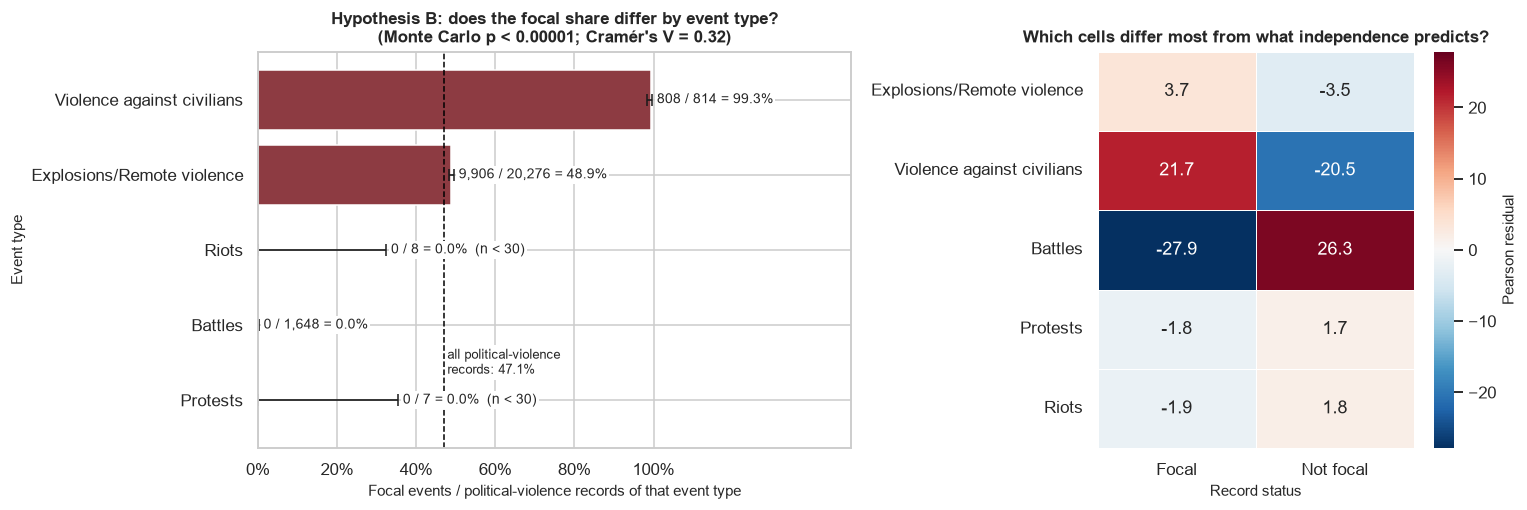

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})

# Left: focal share within each event type, with 95% Wilson intervals; groups with fewer than 30 records are hatched
ax = axes[0]
tb = type_table.assign(n=type_table.sum(axis=1))
tb["share"] = tb.Focal / tb.n
tb = tb.sort_values("share")
small = (tb.n < 30).to_numpy()
cis_B = np.array([wilson_ci(k, n) for k, n in zip(tb.Focal, tb.n)])
bars = ax.barh(tb.index, tb.share, color=[C_GREY if s else C_FOCAL for s in small],
               xerr=[tb.share - cis_B[:, 0], cis_B[:, 1] - tb.share], capsize=4, error_kw={"lw": 1.1})
for b, s in zip(bars, small):
    if s:
        b.set_hatch("//")
for y, (_, r) in enumerate(tb.iterrows()):
    note = "  (n < 30)" if r.n < 30 else ""
    ax.text(cis_B[y, 1] + 0.012, y, f"{r.Focal:,.0f} / {r.n:,.0f} = {r.share:.1%}{note}", va="center", fontsize=9,
            bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
overall = tab_B[:, 0].sum() / n_B
ax.axvline(overall, color="black", ls="--", lw=1)
ax.text(overall + 0.008, 0.5, f"all political-violence\nrecords: {overall:.1%}", fontsize=8.5, va="center",
        bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
ax.grid(axis="x")
ax.set_xlim(0, 1.5); ax.set_xticks(np.arange(0, 1.01, 0.2))
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Focal events / political-violence records of that event type")
ax.set_ylabel("Event type")
ax.set_title(f"Hypothesis B: does the focal share differ by event type?\n(Monte Carlo {fmt_p(p_B, monte_carlo=True)}; Cramér's V = {V_B:.2f})")

# Right: which cells push the table away from independence
ax = axes[1]
lim = float(np.abs(resid_B.to_numpy()).max())
sns.heatmap(resid_B, annot=True, fmt=".1f", cmap="RdBu_r", vmin=-lim, vmax=lim, center=0,
            linewidths=0.5, linecolor="white", cbar_kws={"label": "Pearson residual"}, ax=ax)
ax.grid(False)
ax.set_xlabel("Record status")
ax.set_ylabel("")
ax.set_title("Which cells differ most from what independence predicts?")
plt.tight_layout()
plt.show()

**Interpretation.** We reject H0 (chi-square(4) = 2,394.76, Monte Carlo p < 0.00001, Cramér's V = 0.32). None of the 99,999 simulated tables reached the observed statistic, so 0.00001 is the smallest p-value this run can report, not an exact value (BQ2). In plain terms, the focal share clearly depends on event type: Violence against civilians is almost entirely focal (808 of 814, 99.3%), Explosions/Remote violence is split (9,906 of 20,276, 48.9%) and Battles have none (0 of 1,648). The residuals put the largest departures from independence in Battles (focal cell -27.9), Violence against civilians (+21.7) and Explosions/Remote violence (+3.7), while Protests and Riots stay within about 2 of zero because 7 and 8 records cannot show a clear difference. The result does not depend on the sparse cells: with Protests and Riots pooled (15 records) every expected count is at least 5, the statistic is unchanged at 2,394.76 (both rare types have a focal share of 0) and the conclusion is the same, and Violence against civilians vs. Explosions/Remote violence alone gives chi-square(1) = 795.58 (p = 4.9e-175). The focal rule requires a civilian actor label, so part of this association is built into the coding: it describes how focal events are recorded across types, not which event types produce them.

### 4.4 Summary of Results

The table below collects the two tests. It reads the values computed above, so it updates if the data are re-exported.

In [46]:
summary = pd.DataFrame([
    {"Hypothesis": "A: focal share, before vs. after Oct 7, 2023", "BQ": "BQ1",
     "Test": "Pearson chi-square, 2 × 2", "Statistic": f"chi-square({dof_A}) = {chi2_A:,.2f}", "p-value": fmt_p(p_A),
     "Effect size": f"{diff * 100:+.1f} points; odds ratio {odds:.2f}; phi = {phi_A:.2f}", "Decision": decision_A},
    {"Hypothesis": "B: focal share across event types", "BQ": "BQ2",
     "Test": f"Chi-square, Monte Carlo p ({N_RESAMPLES:,} tables)", "Statistic": f"chi-square({dof_B}) = {chi2_B:,.2f}",
     "p-value": fmt_p(p_B, monte_carlo=True), "Effect size": f"Cramér's V = {V_B:.2f}", "Decision": decision_B},
]).set_index("Hypothesis")
print(f"Decision rule: reject H0 when p < {ALPHA / 2} (alpha = {ALPHA}, Bonferroni-adjusted for two primary tests)")
display(summary)

Decision rule: reject H0 when p < 0.025 (alpha = 0.05, Bonferroni-adjusted for two primary tests)


,BQ,Test,Statistic,p-value,Effect size,Decision
Hypothesis,,,,,,
"A: focal share, before vs. after Oct 7, 2023",BQ1,"Pearson chi-square, 2 × 2",chi-square(1) = 151.60,p = 7.76e-35,+31.4 points; odds ratio 4.71; phi = 0.08,Reject H0
B: focal share across event types,BQ2,"Chi-square, Monte Carlo p (99,999 tables)","chi-square(4) = 2,394.76",p < 0.00001,Cramér's V = 0.32,Reject H0


**Conclusions in plain language.**

- **Hypothesis A (BQ1): rejected H0.** If the focal share were the same before and after Oct 7, 2023, a gap as large as 16.2% vs. 47.6% would almost never occur by chance. From Oct 7 onward, a recorded political-violence event is about 2.9 times as likely to meet the focal rule, and the rise holds inside Explosions/Remote violence, so it is not only a change in the mix of event types.
- **Hypothesis B (BQ2): rejected H0.** The focal share depends strongly on event type: nearly all Violence against civilians records are focal, about half of Explosions/Remote violence records are, and none of the Battles records are. Protests and Riots are too rare to judge. Because the focal rule needs a civilian actor label, this pattern is partly a result of how the rule is built.

**What the tests do not show.**
- They do not show why the focal share changed. A change in events, in ACLED coding or in source coverage after Oct 7, 2023 would all produce the same table, and the earlier period holds only 389 political-violence records (63 focal).
- The p-values treat records as independent, but events cluster in time and place, so they are best read as strong exploratory evidence, not exact probabilities.
- Neither test shows intent, responsibility or a legal classification.

**For the insights writer and Phase 4 modelling.** (1) The rise in focal share is carried by Explosions/Remote violence (13.1% to 49.4%). (2) The event-type association is partly built into the focal rule and should be described that way. (3) The earlier period is sparse and its share is imprecise, which supports using it for description only and comparing weeks within the post-October 7 period in the models, as planned in Phase 2.

# Phase 3 — Pattern Spotting
## Patterns of Recorded Civilian Targeting in Gaza

**DS312 · Group 7 · Phase 3 EDA, Task 5: segments, trends, seasonality, suspicious values and class imbalance**

> **Where this section sits.** Tasks 1 to 3 (univariate, bivariate/multivariate, visualisation) and Task 4 (hypothesis tests) are already written by teammates. This notebook does **not** repeat their charts or tests. It uses the same four Phase 2 tables, the same filters and the same definitions, and then looks for what *stands out*: unusual values, shifts over time, repeating (or non-repeating) cycles, groups of districts, weeks and places, and lopsided classes. Every number that overlaps with an earlier task is checked against it in Section 2.

## 1. Purpose, scope and reading guide

### What "pattern spotting" covers here
The task tracker asks for an **outliers, trends, clustering and imbalance report**. We split it into five questions, each tied to a Phase 1 business question (BQ) and to a Phase 2 table.

| Pattern type | Question | Table (unit of analysis) | Section | Charts |
|---|---|---|---|---|
| **Class imbalance** | Where is focal vs. not-focal so lopsided that a comparison or model would struggle? | `acled_events_clean.csv` (one event), `acled_district_week.csv` | 3 | 1 |
| **Suspicious values** | Which fatality totals and which weeks stand far from typical, and is the data itself consistent? | `acled_events_clean.csv`, `acled_gaza_week.csv`, `acled_district_week.csv` | 4 | 2, 3, 4 |
| **Trends** | Do focal counts and focal share move in one direction over the two years? | `acled_gaza_week.csv` (one Gaza week) | 5 | 5 |
| **Seasonality and persistence** | Do the same months or weekdays repeat, and does a week resemble the previous ones? | `acled_gaza_week.csv`, `acled_events_clean.csv` | 6 | 6, 7 |
| **Segments and clustering** | Which districts, kinds of weeks and places group together? | `acled_district_week.csv`, `acled_gaza_week.csv`, `acled_focal_incidents.csv` | 7 | 8, 9, 10, 11, 12 |

### Interpretation boundary
Everything here describes **records coded by ACLED** and the project's focal-event rule. An outlier, a cluster, a trend or a flagged week is **not** proof of intent, responsibility, causation or legal classification, and a quiet week is not proof that no harm happened. Where a chart shows a dip or a spike we describe it and say what the files cannot tell us; we do not explain its cause.

### Rules carried over from the earlier tasks
- Focal shares always use **political-violence records** as the denominator.
- All Gaza events stay in event-level and Gaza-wide numbers; the **4 events with no district** are left out only of district tables, and **coast-coded events** only of the land spatial table.
- The final week (week of Sep 27, 2025) is **incomplete**, so it is shown but not scored.
- High-fatality flags are for review and **never delete a record**. Precision codes are categories, not distances.
- A week or district with zero recorded events means zero *recorded* events.

### What is reused from the other tasks (numbers only, no tests)
Task 1: fatality percentiles and the focal / not-focal counts. Task 2: focal share before and after Oct 7 (16.2% and 47.6%), by event type and by precision. Task 3: the district-week heatmap and weekly count/share charts. **Task 4 (hypothesis tests) is cited, not repeated:** where imbalance matters for a test, we point to Sections 4.3 and 4.4 of that notebook.

## 2. Phase 2 snapshot consistency checks

This section reuses the four Phase 2 tables loaded and checked in Section 3.4 above; it does not read duplicate copies. Dates and precision categories are already restored. `scikit-learn` is used for the clustering previews and is listed in the project requirements.


The next cell defines the periods and the political-violence denominator and compares what was loaded with the figures the teammates' notebooks quote. If any row says `False`, stop and check the file versions before using any result below.

In [47]:
# Period definitions follow Phase 2: Oct 7, 2023 is the cut-off; the two periods differ in length.
BEFORE, AFTER = "Before Oct 7, 2023", "Oct 7, 2023 onward"
CUTOFF = pd.Timestamp("2023-10-07")

# Political-violence records are the denominator for every focal share (same as Tasks 2 and 4)
political = master.loc[master.political_violence].copy()

# Integrity check: compare what we loaded with the figures the teammates' notebooks quote.
checks = pd.DataFrame([
    ("Event master shape", (26664, 43), master.shape),
    ("Gaza-week table shape", (104, 13), gaza_week.shape),
    ("District-week table shape", (520, 14), district_week.shape),
    ("Focal-incident table shape", (10583, 45), incidents.shape),
    ("Focal events, all", 10714, int(master.focal_event.sum())),
    ("Focal events before Oct 7", 63, int(master.loc[master.period == BEFORE, "focal_event"].sum())),
    ("Focal events Oct 7 onward", 10651, int(master.loc[master.period == AFTER, "focal_event"].sum())),
    ("Political-violence records before Oct 7", 389, int((political.period == BEFORE).sum())),
    ("Political-violence records Oct 7 onward", 22364, int((political.period == AFTER).sum())),
    ("Events with no district", 4, int(master.admin2.isna().sum())),
    ("Gaza-week focal total", 10651, int(gaza_week.focal_events.sum())),
    ("District-week focal total (3 focal events lack a district)", 10648, int(district_week.focal_events.sum())),
    ("Incomplete weeks in Gaza-week table", 1, int((~gaza_week.complete_week).sum())),
    ("Land focal incidents", 10583, len(incidents)),
    ("Precision-1 land focal incidents", 7576, int(incidents.geo_precision_1.sum())),
], columns=["Check", "Expected", "Observed"])
checks["Match"] = [e == o for e, o in zip(checks["Expected"], checks["Observed"])]
display(checks)
print("All checks match the earlier tasks." if checks.Match.all()
      else "Some checks differ: review the table above before using the results.")

,Check,Expected,Observed,Match
0,Event master shape,"(26664, 43)","(26664, 43)",True
1,Gaza-week table shape,"(104, 13)","(104, 13)",True
2,District-week table shape,"(520, 14)","(520, 14)",True
3,Focal-incident table shape,"(10583, 45)","(10583, 45)",True
4,"Focal events, all",10714,10714,True
5,Focal events before Oct 7,63,63,True
6,Focal events Oct 7 onward,10651,10651,True
7,Political-violence records before Oct 7,389,389,True
8,Political-violence records Oct 7 onward,22364,22364,True
9,Events with no district,4,4,True


All checks match the earlier tasks.


Two small helpers are used in Section 4 onward. `robust_z` is the *modified z-score*, which uses the median and the median absolute deviation (MAD) instead of the mean and standard deviation, so the very peaks we are looking for do not hide themselves. `trailing_robust_z` scores each week only against the **previous 8 weeks**, which is the baseline idea Phase 4 plans to use (trailing median/MAD). A score beyond ±3.5 is the usual rule of thumb for "unusual"; it is a screening rule, not a test.

In [48]:
Z_CUT = 3.5   # conventional cut-off for the modified (robust) z-score

def robust_z(s):
    """Modified z-score: 0.6745 * (x - median) / MAD. Robust to the very peaks we are trying to find."""
    med = s.median()
    mad = (s - med).abs().median()
    return 0.6745 * (s - med) / mad

def trailing_robust_z(s, window=8, mad_floor=1.0):
    """Score each week against the previous `window` weeks only (median/MAD of its own recent history).
    The first `window` weeks have no score. mad_floor stops a flat history from dividing by zero."""
    vals = s.to_numpy(float)
    out = np.full(len(vals), np.nan)
    for i in range(window, len(vals)):
        hist = vals[i - window:i]
        med = np.median(hist)
        mad = max(np.median(np.abs(hist - med)), mad_floor)
        out[i] = 0.6745 * (vals[i] - med) / mad
    return pd.Series(out, index=s.index)

## 3. Class imbalance

**Question.** Overall, focal events are 47.1% of political-violence records, which looks balanced. But Phase 4 will compare periods, event types and precision levels, and some of those slices are far from balanced. Where, and how thin is the smaller class? The table gives the focal share, the size of the smaller class and the majority-to-minority ratio for each slice. The weekly view at the bottom checks how often a week or a district-week is "empty".

*Source table: `master` (political-violence records) and the weekly tables. Unit: one record, one week, one district-week.*

In [49]:
def imbalance_row(label, df):
    n = len(df); k = int(df.focal_event.sum()); minority = min(k, n - k)
    return {"Slice": label, "Records": n, "Focal": k, "Not focal": n - k,
            "Focal share": k / n, "Minority class": "focal" if k < n - k else "not focal",
            "Minority count": minority, "Majority : minority": (max(k, n - k) / minority) if minority else np.nan}

post = political[political.period == AFTER]
slices = [
    ("All political-violence records", political),
    ("Before Oct 7, 2023", political[political.period == BEFORE]),
    ("Oct 7, 2023 onward", post),
    ("Oct 7+ · precision 1", post[post.geo_precision == 1]),
    ("Oct 7+ · precision 2", post[post.geo_precision == 2]),
    ("Oct 7+ · Explosions/Remote violence", post[post.event_type == "Explosions/Remote violence"]),
    ("Oct 7+ · Violence against civilians", post[post.event_type == "Violence against civilians"]),
    ("Oct 7+ · Battles", post[post.event_type == "Battles"]),
]
imb = pd.DataFrame([imbalance_row(l, d) for l, d in slices]).set_index("Slice")
display(imb.round({"Focal share": 3, "Majority : minority": 2}))

# Weekly view of the same question: how often is a week "quiet" for focal events?
print("Weeks in the Gaza-week table:", len(gaza_week),
      "| weeks with zero political-violence records:", int((gaza_week.political_events == 0).sum()),
      "| weeks with zero focal events:", int((gaza_week.focal_events == 0).sum()))
dw_zero = district_week.assign(zero_focal=district_week.focal_events == 0,
                               zero_political=district_week.political_events == 0)
display(dw_zero.groupby("admin2")[["zero_focal", "zero_political"]].sum().rename(
    columns={"zero_focal": "district-weeks with 0 focal events", "zero_political": "district-weeks with 0 political-violence records"}))

,Records,Focal,Not focal,Focal share,Minority class,Minority count,Majority : minority
Slice,,,,,,,
All political-violence records,22753,10714,12039,0.471,focal,10714,1.12
"Before Oct 7, 2023",389,63,326,0.162,focal,63,5.17
"Oct 7, 2023 onward",22364,10651,11713,0.476,focal,10651,1.10
Oct 7+ · precision 1,12704,7577,5127,0.596,not focal,5127,1.48
Oct 7+ · precision 2,9583,3040,6543,0.317,focal,3040,2.15
Oct 7+ · Explosions/Remote violence,19978,9867,10111,0.494,focal,9867,1.02
Oct 7+ · Violence against civilians,790,784,6,0.992,not focal,6,130.67
Oct 7+ · Battles,1593,0,1593,0.000,focal,0,NaN


Weeks in the Gaza-week table: 104 | weeks with zero political-violence records: 0 | weeks with zero focal events: 0


,district-weeks with 0 focal events,district-weeks with 0 political-violence records
admin2,,
Deir El Balah,0,0
Gaza City,0,0
Khan Yunis,0,0
North Gaza,7,3
Rafah,0,0


### Chart 1 — How lopsided is each slice, and how big is the smaller class?

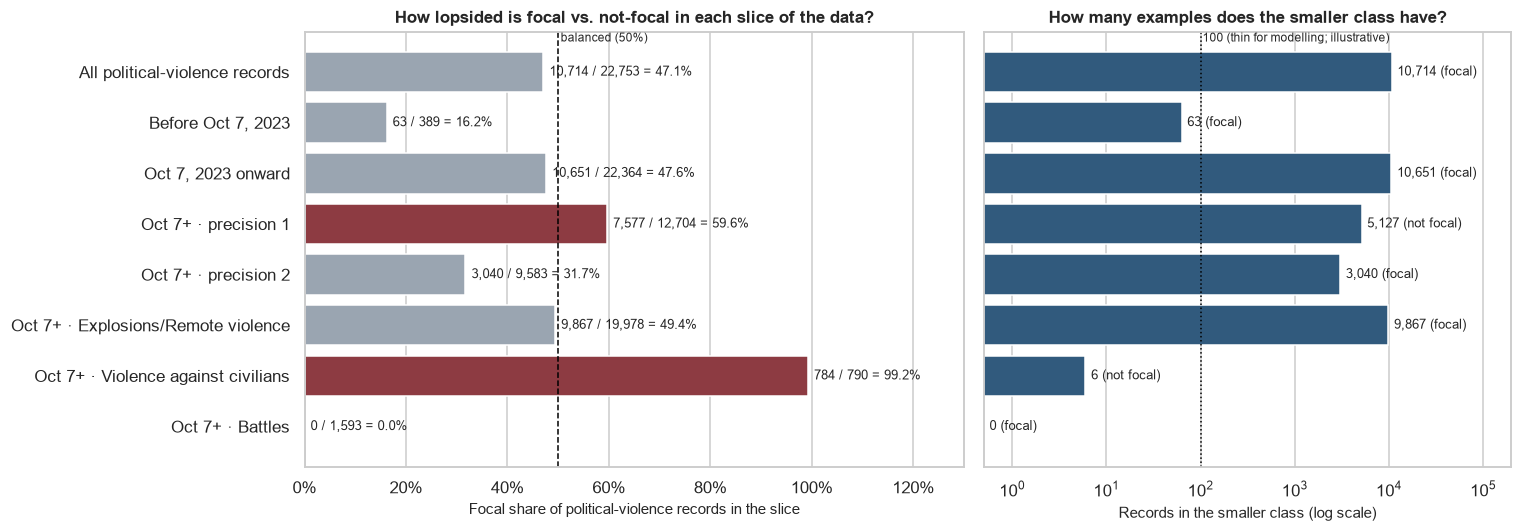

In [50]:
plot_df = imb.iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.25, 1]})

ax = axes[0]
colors = [C_FOCAL if s >= 0.5 else C_GREY for s in plot_df["Focal share"]]
ax.barh(plot_df.index, plot_df["Focal share"], color=colors)
for y, (_, r) in enumerate(plot_df.iterrows()):
    ax.text(r["Focal share"] + 0.012, y, f"{r.Focal:,.0f} / {r.Records:,.0f} = {r['Focal share']:.1%}", va="center", fontsize=8.5)
ax.axvline(0.5, color="black", lw=1, ls="--")
ax.text(0.505, len(plot_df) - 0.45, "balanced (50%)", fontsize=8, va="bottom")
ax.set_xlim(0, 1.3)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Focal share of political-violence records in the slice")
ax.set_ylabel("")
ax.set_title("How lopsided is focal vs. not-focal in each slice of the data?")
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)

ax = axes[1]
ax.barh(plot_df.index, plot_df["Minority count"].clip(lower=0.5), color=C_OTHER)
for y, (_, r) in enumerate(plot_df.iterrows()):
    ax.text(max(r["Minority count"], 0.5) * 1.15, y, f"{r['Minority count']:,.0f} ({r['Minority class']})", va="center", fontsize=8.5)
ax.set_xscale("log"); ax.set_xlim(0.5, 2e5)
ax.axvline(100, color="black", lw=1, ls=":")
ax.text(105, len(plot_df) - 0.45, "100 (thin for modelling; illustrative)", fontsize=8, va="bottom")
ax.set_yticklabels([]); ax.set_ylabel("")
ax.set_xlabel("Records in the smaller class (log scale)")
ax.set_title("How many examples does the smaller class have?")
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
plt.tight_layout(); plt.show()

**Interpretation.** The overall split is nearly even (10,714 focal of 22,753), and so is the period from Oct 7 onward (10,651 of 22,364, ratio 1.10 to 1), but the earlier period is lopsided: 63 focal of 389 records (16.2%, about 5 to 1) with only 63 examples in the smaller class (BQ1, BQ5). Inside the later period the extremes are structural: Violence against civilians is 784 of 790 focal and Battles are 0 of 1,593, so the ratio reaches 131 to 1 and one class is empty. Precision also moves the balance (59.6% focal at precision 1 against 31.7% at precision 2). The event-type extremes are partly built into the focal rule, which needs a civilian actor label, so they describe the coding as much as the events; Task 4 already tests the period and event-type differences, so this chart only shows where the smaller class is too small to model on its own.

**Weekly view.** No Gaza week has zero political-violence records or zero focal events. Only North Gaza has empty district-weeks: 7 with no focal events (6 of them in complete weeks) and 3 with no political-violence records, so shares there are undefined in those weeks. A zero is a zero *recorded* count.

## 4. Suspicious values and outliers

Three kinds of "suspicious": (a) very large fatality totals, (b) weeks whose counts are far from the usual, and (c) data-quality red flags in the files themselves. None of these is deleted; they are flagged for review.

### 4.1 Fatality outliers

**Question.** Fatalities are heavy-tailed with many zeros (Task 1 covers the distribution). Here we ask how far the tail reaches, how much of the reported total sits in it, and when and where it occurs. The review flag in the data marks records with **24 or more** reported fatalities (the lowest flagged value is 24 and the highest unflagged value is 23). Fatalities are reported event totals, not confirmed civilian deaths.

*Source table: `master`. Unit: one event record.*

In [51]:
f = master.fatalities
thr = int(master.loc[master.high_fatalities_review, "fatalities"].min())
thr_below = int(master.loc[~master.high_fatalities_review, "fatalities"].max())
flag = master[master.high_fatalities_review]
top1 = master.nlargest(int(len(master) * 0.01), "fatalities")

fat_summary = pd.DataFrame({"Value": {
    "Records": len(master),
    "Records with 0 fatalities": f"{(f == 0).sum():,} ({(f == 0).mean():.1%})",
    "Median / 75th / 90th percentile": f"{f.median():.0f} / {f.quantile(.75):.0f} / {f.quantile(.90):.0f}",
    "95th / 99th percentile": f"{f.quantile(.95):.0f} / {f.quantile(.99):.0f}",
    "Maximum": int(f.max()),
    "Mean (pulled up by the tail)": round(f.mean(), 2),
    "IQR upper fence (Q3 + 1.5 x IQR)": round(f.quantile(.75) + 1.5 * (f.quantile(.75) - f.quantile(.25)), 1),
    "Review flag: lowest flagged / highest unflagged": f"{thr} / {thr_below}",
    "Records flagged for review": f"{len(flag):,} ({len(flag) / len(master):.1%} of records)",
    "Share of all reported fatalities in flagged records": f"{flag.fatalities.sum() / f.sum():.1%}",
    "Share of all reported fatalities in the top 1% of records": f"{top1.fatalities.sum() / f.sum():.1%}",
    "Flagged records that are focal": f"{int(flag.focal_event.sum())} of {len(flag)}",
}})
display(fat_summary)

print("Flagged records by event type and focal status")
display(flag.groupby(["event_type", "focal_event"]).size().rename("flagged records").to_frame())
print("Flagged records by location precision:", flag.geo_precision.value_counts().sort_index().to_dict())

,Value
Records,26664
Records with 0 fatalities,"17,634 (66.1%)"
Median / 75th / 90th percentile,0 / 2 / 7
95th / 99th percentile,12 / 39
Maximum,471
Mean (pulled up by the tail),2.55
IQR upper fence (Q3 + 1.5 x IQR),5.0
Review flag: lowest flagged / highest unflagged,24 / 23
Records flagged for review,576 (2.2% of records)
Share of all reported fatalities in flagged records,37.6%


Flagged records by event type and focal status


flagged records
event_type                 focal_event                 
Battles                    False                     97
Explosions/Remote violence False                     57
                           True                     409
Violence against civilians True                      13

Flagged records by location precision: {1: 448, 2: 128, 3: 0}


### Chart 2 — How long is the fatality tail, and which records sit at the end of it?

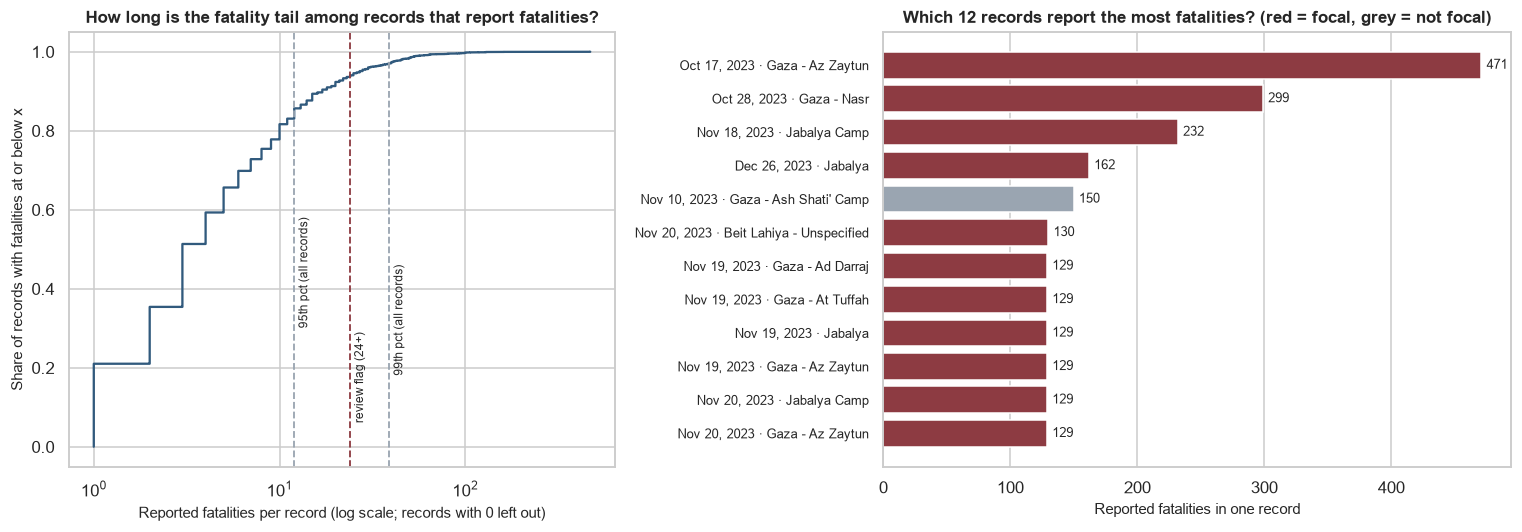

In [52]:
pos = np.sort(f[f > 0].to_numpy())
ecdf = np.arange(1, len(pos) + 1) / len(pos)
top = master.nlargest(12, "fatalities").iloc[::-1]
labels = [f"{d:%b %d, %Y} · {loc}" for d, loc in zip(top.event_date, top.location)]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.15]})
ax = axes[0]
ax.step(pos, ecdf, where="post", color=C_OTHER)
ax.set_xscale("log")
for xv, lab in [(f.quantile(.95), "95th pct (all records)"), (f.quantile(.99), "99th pct (all records)"), (thr, f"review flag ({thr}+)")]:
    ax.axvline(xv, color=C_FOCAL if "flag" in lab else C_GREY, ls="--", lw=1.2)
    ax.text(xv * 1.05, 0.06 if "flag" in lab else (0.18 if "99" in lab else 0.30), lab, rotation=90, fontsize=8, va="bottom")
ax.set_xlabel("Reported fatalities per record (log scale; records with 0 left out)")
ax.set_ylabel("Share of records with fatalities at or below x")
ax.set_title("How long is the fatality tail among records that report fatalities?")
ax.grid(axis="x", visible=True)

ax = axes[1]
ax.barh(range(len(top)), top.fatalities, color=[C_FOCAL if v else C_GREY for v in top.focal_event])
ax.set_yticks(range(len(top))); ax.set_yticklabels(labels, fontsize=8.5)
for y, v in enumerate(top.fatalities):
    ax.text(v + 4, y, f"{v}", va="center", fontsize=8.5)
ax.set_xlabel("Reported fatalities in one record")
ax.set_title("Which 12 records report the most fatalities? (red = focal, grey = not focal)")
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
plt.tight_layout(); plt.show()

**Interpretation.** Two thirds of records report zero fatalities (66.1%), the 95th percentile is 12 and the 99th is 39, yet the maximum is 471 (Gaza - Az Zaytun, Oct 17, 2023); the 576 flagged records are only 2.2% of records but hold 37.6% of all reported fatalities (BQ4). The three largest records all fall in Oct to Nov 2023, and 422 of the 576 flagged records are focal, with another 97 being Battles. These records dominate any sum or mean of fatalities, so medians and shares are safer summaries (as Task 2 already does); a very large total may be one event or an aggregated report, which only the event notes can settle.

### Chart 3 — When are the high-fatality records concentrated?

,Focal,Not focal,Share of that quarter's records flagged
quarter,,,
2023Q4,235,46,0.077
2024Q1,81,14,0.026
2024Q2,26,21,0.015
2024Q3,6,31,0.012
2024Q4,21,30,0.017
2025Q1,3,2,0.004
2025Q2,23,8,0.009
2025Q3,27,2,0.009


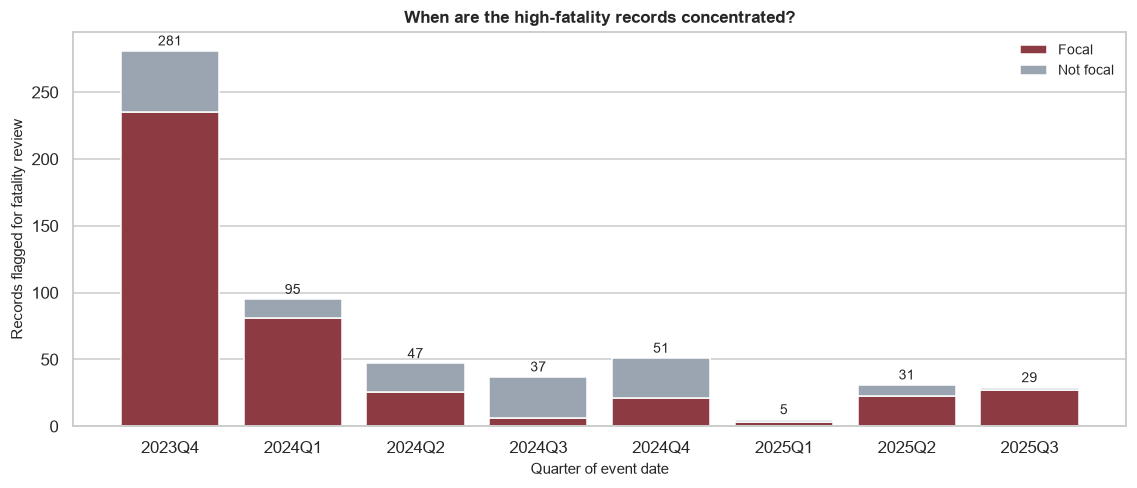

In [53]:
q = flag.assign(quarter=flag.event_date.dt.to_period("Q").astype(str))
qt = pd.crosstab(q.quarter, q.focal_event).reindex(columns=[True, False], fill_value=0)
qt.columns = ["Focal", "Not focal"]
all_q = master.assign(quarter=master.event_date.dt.to_period("Q").astype(str))
qt = qt.reindex(sorted(all_q.quarter.unique()), fill_value=0)
qt = qt.loc[qt.index >= "2023Q4"]
qt["Share of that quarter's records flagged"] = qt.sum(axis=1) / all_q.groupby("quarter").size().reindex(qt.index)
display(qt.round({"Share of that quarter's records flagged": 3}))

fig, ax = plt.subplots(figsize=(10.5, 4.6))
ax.bar(qt.index, qt["Focal"], color=C_FOCAL, label="Focal")
ax.bar(qt.index, qt["Not focal"], bottom=qt["Focal"], color=C_GREY, label="Not focal")
for x, (_, r) in enumerate(qt.iterrows()):
    ax.text(x, r["Focal"] + r["Not focal"] + 4, f"{int(r['Focal'] + r['Not focal'])}", ha="center", fontsize=9)
ax.set_xlabel("Quarter of event date"); ax.set_ylabel("Records flagged for fatality review")
ax.set_title("When are the high-fatality records concentrated?")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

**Interpretation.** Q4 2023 holds 281 of the 576 flagged records (235 focal, 46 not focal) and 7.7% of that quarter's records are flagged, against 2.6% in Q1 2024 and 1.7% or less in every later quarter (BQ4). The extreme-total problem is therefore mostly a feature of the first three months, so including or dropping flagged records changes early-period results far more than later ones. This is a count threshold, not a verification, and a quiet quarter does not mean low harm; reporting coverage can differ across periods.

### 4.2 Unusual weeks

**Question.** Which Gaza-wide weeks have counts far from the typical week? Two rules are compared on the 103 complete weeks: a **whole-period** robust z-score (median 98 and MAD 17 for focal events) and the **trailing 8-week** rule planned for Phase 4. The first 8 weeks have no trailing score, and the incomplete final week is shown but not scored.

*Source table: `acled_gaza_week.csv`. Unit: one Gaza week.*

In [54]:
gwc = gaza_week[gaza_week.complete_week].sort_values("week_start").set_index("week_start").copy()
partial = gaza_week[~gaza_week.complete_week]
for c in ["focal_events", "political_events", "focal_share"]:
    gwc[f"rz_{c}"] = robust_z(gwc[c])                    # against the whole period
    gwc[f"tz_{c}"] = trailing_robust_z(gwc[c], window=8)  # against the previous 8 weeks only

med = {c: gwc[c].median() for c in ["focal_events", "political_events", "focal_share"]}
mad = {c: (gwc[c] - med[c]).abs().median() for c in med}
print("Median / MAD of weekly values (complete weeks):",
      {c: (round(med[c], 3), round(mad[c], 3)) for c in med})
print(f"|modified z| > {Z_CUT}:  focal_events {int((gwc.rz_focal_events.abs() > Z_CUT).sum())} weeks | "
      f"political_events {int((gwc.rz_political_events.abs() > Z_CUT).sum())} | focal_share {int((gwc.rz_focal_share.abs() > Z_CUT).sum())}")
print(f"Trailing 8-week rule: focal_events {int((gwc.tz_focal_events.abs() > Z_CUT).sum())} weeks | "
      f"political_events {int((gwc.tz_political_events.abs() > Z_CUT).sum())} | focal_share {int((gwc.tz_focal_share.abs() > Z_CUT).sum())}")

flagged = gwc[(gwc[["rz_focal_events", "rz_political_events", "tz_focal_events", "tz_political_events"]].abs() > Z_CUT).any(axis=1)]
display(flagged[["focal_events", "political_events", "focal_share", "rz_focal_events", "rz_political_events",
                 "tz_focal_events", "tz_political_events"]].round(2))

Median / MAD of weekly values (complete weeks): {'focal_events': (np.float64(98.0), np.float64(17.0)), 'political_events': (np.float64(214.0), np.float64(33.0)), 'focal_share': (np.float64(0.472), np.float64(0.097))}
|modified z| > 3.5:  focal_events 3 weeks | political_events 5 | focal_share 0
Trailing 8-week rule: focal_events 13 weeks | political_events 17 | focal_share 0


,focal_events,political_events,focal_share,rz_focal_events,rz_political_events,tz_focal_events,tz_political_events
week_start,,,,,,,
2023-10-21,203,289,0.70,4.17,1.53,NaN,NaN
2023-10-28,254,360,0.71,6.19,2.98,NaN,NaN
2023-11-04,233,365,0.64,5.36,3.09,NaN,NaN
2024-02-10,103,203,0.51,0.20,-0.22,0.39,-8.91
2024-02-24,99,254,0.39,0.04,0.82,-0.12,-4.41
2024-03-30,67,219,0.31,-1.23,0.10,-4.32,-2.21
2024-06-08,70,201,0.35,-1.11,-0.27,-3.66,-2.30
2024-06-15,69,190,0.36,-1.15,-0.49,-3.85,-2.85
2024-10-05,100,237,0.42,0.08,0.47,1.12,4.64


### Chart 4 — Which weeks are unusual for focal events and for political-violence records?

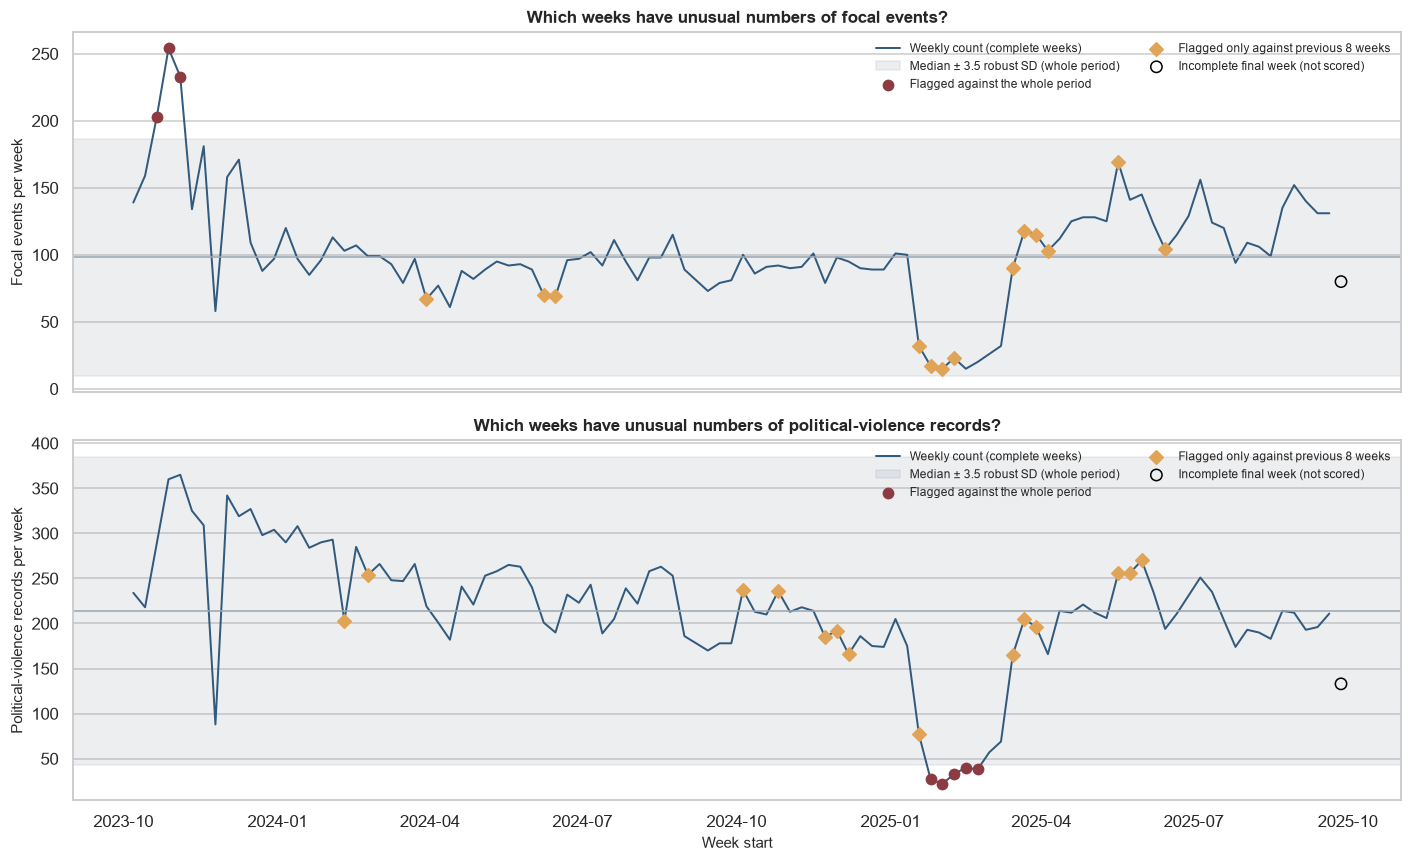

In [55]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for ax, col, title, ylab in [
    (axes[0], "focal_events", "Which weeks have unusual numbers of focal events?", "Focal events per week"),
    (axes[1], "political_events", "Which weeks have unusual numbers of political-violence records?", "Political-violence records per week")]:
    s = gwc[col]
    ax.plot(s.index, s, color=C_OTHER, lw=1.3, label="Weekly count (complete weeks)")
    band = 1.4826 * mad[col] * Z_CUT
    ax.axhspan(med[col] - band, med[col] + band, color=C_GREY, alpha=0.18, label=f"Median ± {Z_CUT} robust SD (whole period)")
    ax.axhline(med[col], color=C_GREY, lw=1)
    g_flag = gwc[gwc[f"rz_{col}"].abs() > Z_CUT]
    t_flag = gwc[(gwc[f"tz_{col}"].abs() > Z_CUT) & ~(gwc[f"rz_{col}"].abs() > Z_CUT)]
    ax.scatter(g_flag.index, g_flag[col], color=C_FOCAL, s=45, zorder=3, label="Flagged against the whole period")
    ax.scatter(t_flag.index, t_flag[col], color=C_WARN, marker="D", s=40, zorder=3, label="Flagged only against previous 8 weeks")
    ax.scatter(partial.week_start, partial[col], facecolors="none", edgecolors="black", s=55, zorder=4, label="Incomplete final week (not scored)")
    ax.set_title(title); ax.set_ylabel(ylab)
    ax.legend(frameon=False, ncol=2, fontsize=8, loc="upper right")
axes[1].set_xlabel("Week start")
plt.tight_layout(); plt.show()

**Interpretation.** Against the whole period only three focal-event weeks stand out, all at the very start (Oct 21, Oct 28 with the peak of 254, and Nov 4, 2023), and only five political-violence weeks stand out, all low (Jan 25 to Feb 22, 2025, with 22 to 40 records); no week has an unusual focal *share* (30% to 73%) (BQ4). The trailing rule flags 13 focal-event weeks, but most of the highs (Mar 15 to Apr 5, 2025 and May 17, 2025) are the recovery after the Jan to Feb 2025 collapse, with 90 to 169 events against a long-run median of 98, so a short baseline scores a return to normal as a spike. The files contain no source for the Jan to Feb 2025 fall, so we describe it and do not explain it; the dip in the week of Nov 25, 2023 (58 focal events) is not flagged by either rule, and the first 8 weeks have no trailing score at all.

### District-week check with the same trailing rule

In [56]:
# Same trailing 8-week rule, applied inside each district (complete weeks only).
dwc = district_week[district_week.complete_week].sort_values(["admin2", "week_start"]).copy()
dwc["tz_focal"] = dwc.groupby("admin2").focal_events.transform(lambda s: trailing_robust_z(s, window=8))
elig = dwc.tz_focal.notna()
dist_flags = (dwc[elig].assign(high=lambda d: d.tz_focal > Z_CUT, low=lambda d: d.tz_focal < -Z_CUT)
              .groupby("admin2").agg(scored_weeks=("tz_focal", "size"), high_weeks=("high", "sum"), low_weeks=("low", "sum")))
dist_flags["flagged share"] = (dist_flags.high_weeks + dist_flags.low_weeks) / dist_flags.scored_weeks
display(dist_flags.round({"flagged share": 3}))
print("All districts together:", int((dist_flags.high_weeks + dist_flags.low_weeks).sum()), "flagged of",
      int(dist_flags.scored_weeks.sum()), "scored district-weeks =",
      f"{(dist_flags.high_weeks + dist_flags.low_weeks).sum() / dist_flags.scored_weeks.sum():.1%}")
print("Highest-scoring district-weeks (upward):")
display(dwc.nlargest(6, "tz_focal")[["admin2", "week_start", "focal_events", "political_events", "tz_focal"]].round({"tz_focal": 2}))

,scored_weeks,high_weeks,low_weeks,flagged share
admin2,,,,
Deir El Balah,95,6,2,0.084
Gaza City,95,9,4,0.137
Khan Yunis,95,7,0,0.074
North Gaza,95,11,3,0.147
Rafah,95,5,3,0.084


All districts together: 50 flagged of 475 scored district-weeks = 10.5%
Highest-scoring district-weeks (upward):


,admin2,week_start,focal_events,political_events,tz_focal
285,Khan Yunis,2025-03-29,48,69,11.47
76,Deir El Balah,2025-03-22,18,35,10.79
249,Khan Yunis,2024-07-20,41,67,10.79
180,Gaza City,2025-03-22,28,48,10.57
77,Deir El Balah,2025-03-29,17,35,10.12
387,North Gaza,2025-03-15,16,22,10.12


**Interpretation.** In 475 scored district-weeks, 50 (10.5%) are flagged, and the share is highest in North Gaza (14.7%) and Gaza City (13.7%) and lowest in Khan Yunis (7.4%) (BQ4). The six highest upward scores come from March 2025 and one week of July 2024 (Khan Yunis, Jul 20, 41 focal events), which repeats the recovery effect seen above. Flagged weeks are about one in ten, so a weekly anomaly detector faces an imbalanced target of its own, and small districts such as North Gaza have low weekly counts and give noisy scores.

### 4.3 Is the data itself consistent?

In [57]:
lat_ok = master.latitude.between(31.2, 31.6) & master.longitude.between(34.2, 34.6)
dq = pd.DataFrame([
    ("Duplicate event IDs in the master", int(master.duplicated("event_id_cnty").sum()), "None: no event is counted twice."),
    ("Missing coordinates in the master", int(master[["latitude", "longitude"]].isna().any(axis=1).sum()), "None missing."),
    ("Coordinates outside a rough Gaza box (lat 31.2-31.6, lon 34.2-34.6)", int((~lat_ok).sum()), "All inside: no impossible locations."),
    ("Events with no district (kept in Gaza-wide totals)", int(master.admin2.isna().sum()), "Left out of district tables only."),
    ("Coast-coded events (kept in Gaza-wide totals)", int(master.coastal_location.sum()), "Left out of the land spatial table only."),
    ("Zero-event weeks in the Gaza-week table", int((gaza_week.recorded_events == 0).sum()), "None: weekly activity never stops in the record."),
    ("Incomplete final week", f"{partial.week_start.dt.date.iloc[0]} to {partial.week_end.dt.date.iloc[0]}", "Marked and left out of scoring; the export ends Sep 30, 2025."),
    ("Records with 0 reported fatalities", f"{(master.fatalities == 0).mean():.1%}", "A zero may mean no figure was recorded, not that nobody was hurt."),
    ("Records with time precision other than 1", f"{(master.time_precision != 1).mean():.1%}", "Date is not exact for these; weekly counts can shift by a week."),
    ("Land focal incidents", len(incidents), ""),
    ("Distinct coordinate pairs among them", len(incidents[["latitude", "longitude"]].drop_duplicates()), "Many incidents share one coordinate: they stand for named places, not exact points."),
], columns=["Check", "Result", "Reading"])
display(dq)

,Check,Result,Reading
0,Duplicate event IDs in the master,0,None: no event is counted twice.
1,Missing coordinates in the master,0,None missing.
2,Coordinates outside a rough Gaza box (lat 31.2...,0,All inside: no impossible locations.
3,Events with no district (kept in Gaza-wide tot...,4,Left out of district tables only.
4,Coast-coded events (kept in Gaza-wide totals),701,Left out of the land spatial table only.
5,Zero-event weeks in the Gaza-week table,0,None: weekly activity never stops in the record.
6,Incomplete final week,2025-09-27 to 2025-10-03,Marked and left out of scoring; the export end...
7,Records with 0 reported fatalities,66.1%,"A zero may mean no figure was recorded, not th..."
8,Records with time precision other than 1,0.8%,Date is not exact for these; weekly counts can...
9,Land focal incidents,10583,


**Interpretation.** The checks find no duplicate IDs, no missing coordinates and no coordinates outside the Gaza area, and every Gaza week has recorded activity (BQ5). The cautions are about meaning: 66.1% of records report zero fatalities, 701 events are coast-coded and left out of the land map only, and the 10,583 land focal incidents sit on just **101 distinct coordinates**, so a coordinate stands for a named place and not an exact point. Only 0.8% of records have a time precision other than 1, so weekly counts are stable against date uncertainty.

## 5. Trends

**Question.** Over the two years from Oct 7, 2023, is there a lasting direction in weekly focal events, in political-violence records or in the focal share? Weekly values are summed to months (a week belongs to the month it starts in; complete weeks only) so the long-run shape is easier to see than in the weekly charts of Task 3. A Spearman rank correlation with week number gives a rough direction; the p-values are only a guide because neighbouring weeks are not independent.

*Source table: `acled_gaza_week.csv`. Unit: one Gaza week, summed to months.*

In [58]:
wk = gwc.reset_index()
wk["month"] = wk.week_start.dt.to_period("M")
mo = wk.groupby("month").agg(focal=("focal_events", "sum"), political=("political_events", "sum"), weeks=("focal_events", "size"))
mo["share"] = mo.focal / mo.political
mo.index = mo.index.astype(str)
display(mo.T.round(3))

wk["quarter"] = wk.week_start.dt.to_period("Q").astype(str)
qtr = wk.groupby("quarter").agg(weeks=("focal_events", "size"), mean_focal_per_week=("focal_events", "mean"),
                                mean_political_per_week=("political_events", "mean"), pooled_share=("focal_events", "sum"))
qtr["pooled_share"] = qtr.pooled_share / wk.groupby("quarter").political_events.sum()
display(qtr.round({"mean_focal_per_week": 1, "mean_political_per_week": 1, "pooled_share": 3}))

# Rank trend against time (exploratory: weeks are serially dependent, so the p-values are only a rough guide)
t = np.arange(len(gwc))
trend = []
for c in ["focal_events", "political_events", "focal_share"]:
    rho, p = spearmanr(t, gwc[c])
    half = len(gwc) // 2
    trend.append({"Weekly measure": c, "Spearman rho vs week number": rho, "p (rough)": p,
                  "Median, first half": gwc[c].iloc[:half].median(), "Median, second half": gwc[c].iloc[half:].median()})
display(pd.DataFrame(trend).set_index("Weekly measure").round(3))

month,2023-10,2023-11,2023-12,2024-01,2024-02,2024-03,2024-04,2024-05,2024-06,2024-07,...,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09
focal,755.000,606.000,623.000,398.00,422.000,435.000,308.000,369.000,421.000,400.000,...,363.000,250.000,73.000,381.000,468.000,708.00,471.000,494.000,601.000,402.00
political,1101.000,1087.000,1590.000,1172.00,1035.000,1246.000,845.000,1039.000,1086.000,876.000,...,701.000,484.000,133.000,692.000,813.000,1200.00,871.000,864.000,992.000,600.00
weeks,4.000,4.000,5.000,4.00,4.000,5.000,4.000,4.000,5.000,4.000,...,4.000,4.000,4.000,5.000,4.000,5.00,4.000,4.000,5.000,3.00
share,0.686,0.557,0.392,0.34,0.408,0.349,0.364,0.355,0.388,0.457,...,0.518,0.517,0.549,0.551,0.576,0.59,0.541,0.572,0.606,0.67


,weeks,mean_focal_per_week,mean_political_per_week,pooled_share
quarter,,,,
2023Q4,13,152.6,290.6,0.525
2024Q1,13,96.5,265.6,0.363
2024Q2,13,84.5,228.5,0.370
2024Q3,13,91.9,212.5,0.433
2024Q4,13,91.6,201.5,0.455
2025Q1,13,54.2,100.7,0.538
2025Q2,13,126.7,221.8,0.571
2025Q3,12,124.8,204.7,0.610


,Spearman rho vs week number,p (rough),"Median, first half","Median, second half"
Weekly measure,,,,
focal_events,0.104,0.295,96.000,101.000
political_events,-0.550,0.000,253.000,200.000
focal_share,0.514,0.000,0.383,0.543


### Chart 5 — Is there a lasting trend in monthly focal events and in their share?

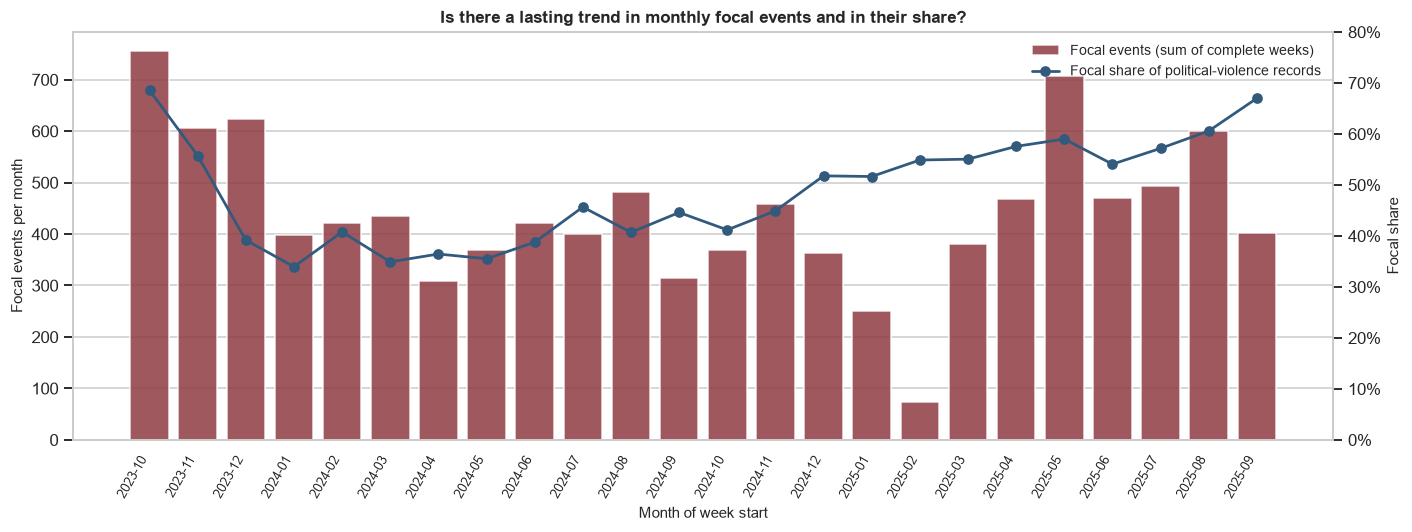

In [59]:
fig, ax = plt.subplots(figsize=(13, 5))
x = np.arange(len(mo))
ax.bar(x, mo.focal, color=C_FOCAL, alpha=0.85, label="Focal events (sum of complete weeks)")
ax.set_xticks(x); ax.set_xticklabels(mo.index, rotation=60, ha="right", fontsize=8.5)
ax.set_ylabel("Focal events per month"); ax.set_xlabel("Month of week start")
ax.set_title("Is there a lasting trend in monthly focal events and in their share?")
ax2 = ax.twinx()
ax2.plot(x, mo["share"], color=C_OTHER, marker="o", lw=1.8, label="Focal share of political-violence records")
ax2.set_ylabel("Focal share"); ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax2.set_ylim(0, 0.8)
ax2.grid(False)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, frameon=False, loc="upper right")
plt.tight_layout(); plt.show()

**Interpretation.** Focal events show no lasting direction (Spearman 0.10, median 96 per week in the first half and 101 in the second), but political-violence records fall (rho -0.55, median 253 to 200) and the focal share rises (rho 0.51, median 38.3% to 54.3%), from a trough of 34.0% in Jan 2024 to 67.0% in Sep 2025 (BQ1, BQ4). In other words the share rises mainly because the non-focal part of political violence falls while focal counts hold, and the monthly counts swing from 755 (Oct 2023) down to 73 (Feb 2025) and back to 708 (May 2025), so the series is a set of level shifts and not a straight line. The first and last months cover only 4 and 3 weeks, and the rank-correlation p-values ignore serial dependence.

## 6. Seasonality and persistence

**Question.** Do the same calendar months or weekdays repeat, and does a week resemble the weeks before it? The data cover about two years, so each calendar month appears at most twice (Oct to Dec in 2023 and 2024, Jan to Sep in 2024 and 2025) and a 52-week cycle cannot be tested at all. We therefore compare the two years month by month, look at weekdays, and use the autocorrelation function (ACF) to check persistence.

*Source tables: `acled_gaza_week.csv` (months, ACF) and `acled_events_clean.csv` (weekdays, focal events from Oct 7).*

### Chart 6 — Do the same calendar months and weekdays repeat?

year,2023,2024,2025
mon,,,
1,NaN,99.5,62.5
2,NaN,105.5,18.2
3,NaN,87.0,76.2
4,NaN,77.0,117.0
5,NaN,92.2,141.6
6,NaN,84.2,117.8
7,NaN,100.0,123.5
8,NaN,96.2,120.2
9,NaN,78.5,134.0


Months present in both 2024 and 2025: 9 (Jan-Sep). Spearman rho between the two years' monthly means = -0.30
Focal events by weekday: {'Mon': 1474, 'Tue': 1597, 'Wed': 1571, 'Thu': 1521, 'Fri': 1485, 'Sat': 1559, 'Sun': 1444} | highest / lowest = 1.11


C:\Users\USER\AppData\Local\Temp\ipykernel_32364\3837699547.py:9: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  dow = post_focal.event_date.dt.dayofweek.value_counts().sort_index()


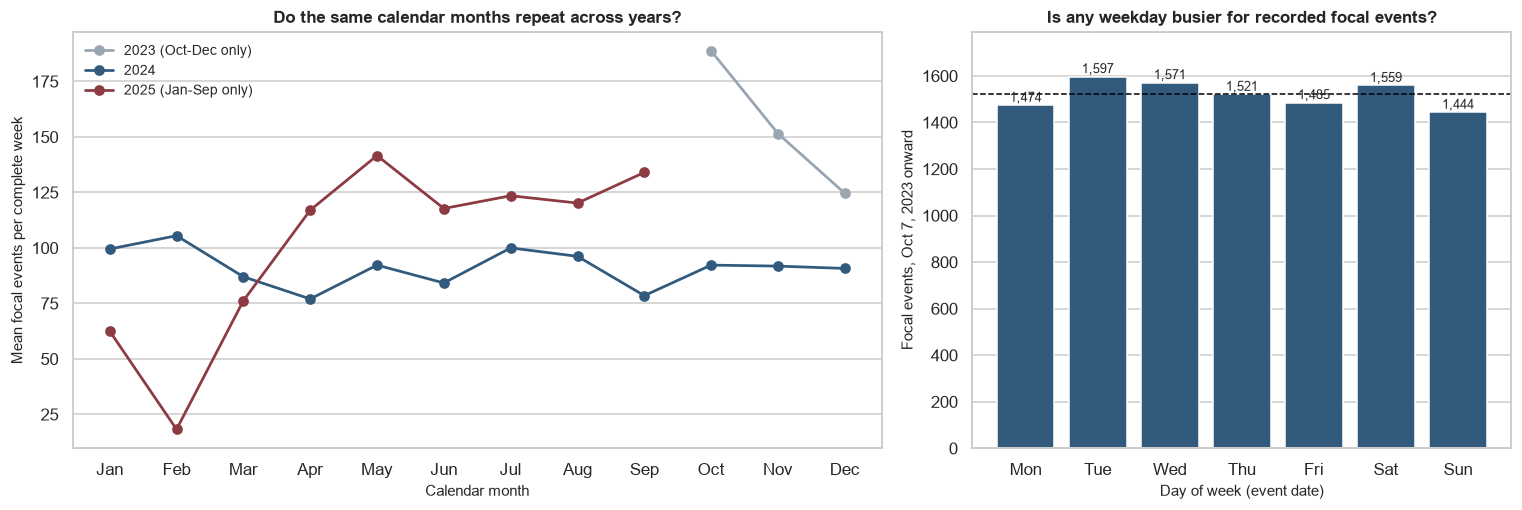

In [60]:
wk["year"], wk["mon"] = wk.week_start.dt.year, wk.week_start.dt.month
moy = wk.groupby(["year", "mon"]).focal_events.mean().unstack(0)
display(moy.round(1))
both = moy[[2024, 2025]].dropna()
rho_yy, _ = spearmanr(both[2024], both[2025])
print(f"Months present in both 2024 and 2025: {len(both)} (Jan-Sep). Spearman rho between the two years' monthly means = {rho_yy:.2f}")

post_focal = master[(master.focal_event) & (master.period == AFTER)]
dow = post_focal.event_date.dt.dayofweek.value_counts().sort_index()
dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
print("Focal events by weekday:", dow.to_dict(), f"| highest / lowest = {dow.max() / dow.min():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
for yr, col in zip([2023, 2024, 2025], [C_GREY, C_OTHER, C_FOCAL]):
    s = moy[yr].dropna()
    ax.plot(s.index, s.values, marker="o", color=col, lw=1.8, label=str(yr) + (" (Oct-Dec only)" if yr == 2023 else " (Jan-Sep only)" if yr == 2025 else ""))
ax.set_xticks(range(1, 13)); ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_xlabel("Calendar month"); ax.set_ylabel("Mean focal events per complete week")
ax.set_title("Do the same calendar months repeat across years?")
ax.legend(frameon=False)
ax = axes[1]
ax.bar(dow.index, dow.values, color=C_OTHER)
ax.axhline(dow.mean(), color="black", ls="--", lw=1)
for i, v in enumerate(dow.values):
    ax.text(i, v + 15, f"{v:,}", ha="center", fontsize=8.5)
ax.set_ylim(0, dow.max() * 1.12)
ax.set_xlabel("Day of week (event date)"); ax.set_ylabel("Focal events, Oct 7, 2023 onward")
ax.set_title("Is any weekday busier for recorded focal events?")
plt.tight_layout(); plt.show()

*(The cell above also prints the monthly means and weekday counts behind the chart.)*

**Interpretation.** The two years do not share a calendar shape: for the nine months present in both (Jan to Sep), the correlation between 2024 and 2025 monthly means is -0.30, February is 105.5 per week in 2024 and 18.2 in 2025, and Oct to Dec 2023 (188.8, 151.5 and 124.6) is far above the same months of 2024 (about 91) (BQ4). Weekday counts range only from 1,444 (Sunday) to 1,597 (Tuesday), a ratio of 1.11, so no day stands out. There is no evidence of seasonality here, but two years cannot rule out a longer cycle, and weekday counts also reflect when events are reported.

### Chart 7 — Does a week resemble the weeks before it?

ACF of weekly focal events, lags 1-12: [ 0.76  0.63  0.49  0.39  0.34  0.26  0.18  0.12  0.08  0.03  0.   -0.04]
ACF of week-to-week changes, lags 1-12: [-0.26  0.02 -0.13 -0.08  0.11 -0.03  0.02 -0.09  0.02 -0.04  0.04 -0.11]
Approximate 95% band: ±0.19  (n = 103 weeks).
A 52-week cycle cannot be checked: the table spans only 104 weeks (about two years).


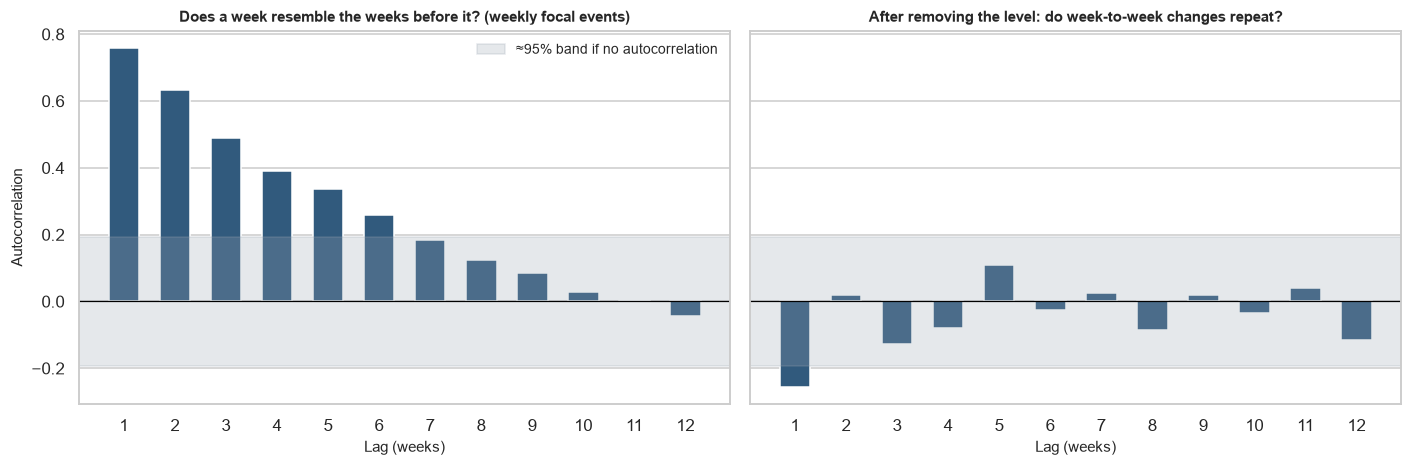

In [61]:
def acf(x, nlags):
    x = np.asarray(x, float); x = x - x.mean()
    return np.array([(x[:-k] * x[k:]).sum() / (x * x).sum() for k in range(1, nlags + 1)])

series = gwc.focal_events.to_numpy(float)
lags = np.arange(1, 13)
acf_level, acf_diff = acf(series, 12), acf(np.diff(series), 12)
band = 1.96 / np.sqrt(len(series))
print("ACF of weekly focal events, lags 1-12:", np.round(acf_level, 2))
print("ACF of week-to-week changes, lags 1-12:", np.round(acf_diff, 2))
print(f"Approximate 95% band: ±{band:.2f}  (n = {len(series)} weeks).")
print("A 52-week cycle cannot be checked: the table spans only", len(gaza_week), "weeks (about two years).")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for ax, vals, title in [(axes[0], acf_level, "Does a week resemble the weeks before it? (weekly focal events)"),
                        (axes[1], acf_diff, "After removing the level: do week-to-week changes repeat?")]:
    ax.bar(lags, vals, color=C_OTHER, width=0.6)
    ax.axhline(0, color="black", lw=0.8)
    ax.axhspan(-band, band, color=C_GREY, alpha=0.25, label="≈95% band if no autocorrelation")
    ax.set_xlabel("Lag (weeks)"); ax.set_title(title, fontsize=10)
    ax.set_xticks(lags)
axes[0].set_ylabel("Autocorrelation"); axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

**Interpretation.** Weekly focal events are strongly persistent: the autocorrelation is 0.76 at lag 1 and decays slowly (0.63, 0.49, 0.39, 0.34, 0.26) until it falls inside the ±0.19 band at lag 7, while the week-to-week *changes* are essentially uncorrelated (only lag 1, -0.26, sits just outside the band) (BQ4). A slow decay with no peak at lag 4 or 8 points to level shifts (the regimes in Section 7) and not to a repeating cycle, which supports using the previous week and the previous four weeks as history features in Phase 4. Level shifts inflate the autocorrelation of any non-stationary series, so these values describe persistence, not predictability.

## 7. Segments and clustering

Three groupings: districts (by volume and burstiness), weeks (by what kind of week they were) and places (by where incidents are recorded). The last one also previews the DBSCAN settings Phase 4 will use. These are **descriptive groupings**, not validated models, and a cluster is a recorded concentration, not an exact attack point.

### 7.1 District segments

**Question.** Which districts carry most focal events, is that split stable, and which districts are bursty? Only the 5 known districts are used (the 4 events with no district are excluded, 3 of them focal), and the incomplete final week is dropped. Burstiness is the standard deviation divided by the mean of weekly counts.

*Source table: `acled_district_week.csv`. Unit: one district-week.*

### Chart 8 — Which districts carry the focal events, and how steady are they?

,total,median,mean,sd,peak,cv,share_of_known_district_focal,weeks_with_zero
admin2,,,,,,,,
Gaza City,3411,30.0,33.1,19.0,102,0.57,0.323,0
Khan Yunis,2278,22.0,22.1,14.4,64,0.65,0.216,0
Deir El Balah,2257,22.0,21.9,8.9,44,0.40,0.214,0
North Gaza,1325,9.0,12.9,10.7,61,0.83,0.125,6
Rafah,1297,10.0,12.6,6.4,31,0.50,0.123,0


Range of each district's 4-week share of known-district focal events:


,min,max
admin2,,
Gaza City,0.151,0.558
Khan Yunis,0.065,0.402
Deir El Balah,0.084,0.332
North Gaza,0.012,0.291
Rafah,0.024,0.470


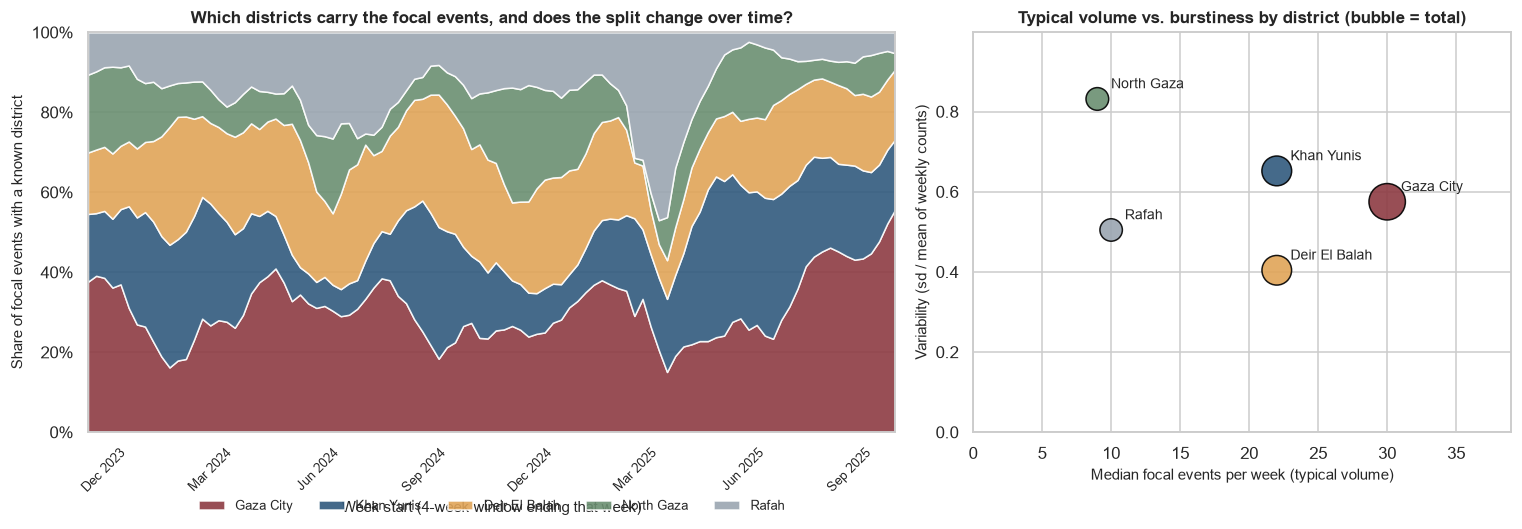

In [62]:
pivot = dwc.pivot(index="week_start", columns="admin2", values="focal_events")
roll = pivot.rolling(4).sum()
share4 = roll.div(roll.sum(axis=1), axis=0).dropna()
order = pivot.sum().sort_values(ascending=False).index.tolist()

prof = dwc.groupby("admin2").focal_events.agg(total="sum", median="median", mean="mean", sd="std", peak="max")
prof["cv"] = prof.sd / prof["mean"]
prof["share_of_known_district_focal"] = prof.total / prof.total.sum()
prof["weeks_with_zero"] = dwc.groupby("admin2").focal_events.apply(lambda s: int((s == 0).sum()))
prof = prof.loc[order]
display(prof.round({"mean": 1, "sd": 1, "cv": 2, "share_of_known_district_focal": 3}))
print("Range of each district's 4-week share of known-district focal events:")
display(pd.DataFrame({"min": share4.min(), "max": share4.max()}).loc[order].round(3))

dist_colors = dict(zip(order, ["#8D3B42", "#315A7D", "#E0A458", "#6B8F71", "#9AA5B1"]))
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
ax.stackplot(share4.index, [share4[d] for d in order], labels=order, colors=[dist_colors[d] for d in order], alpha=0.9)
ax.set_ylim(0, 1); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.set_xlim(share4.index.min(), share4.index.max())
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", fontsize=8.5)
ax.set_xlabel("Week start (4-week window ending that week)"); ax.set_ylabel("Share of focal events with a known district")
ax.set_title("Which districts carry the focal events, and does the split change over time?")
ax.legend(frameon=False, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.14), fontsize=8.5)
ax = axes[1]
ax.scatter(prof["median"], prof["cv"], s=prof.total / 6, color=[dist_colors[d] for d in prof.index], alpha=0.9, edgecolor="black")
for d, r in prof.iterrows():
    ax.annotate(d, (r["median"], r["cv"]), textcoords="offset points", xytext=(9, 7), fontsize=9)
ax.set_xlim(0, prof["median"].max() * 1.3); ax.set_ylim(0, prof.cv.max() * 1.2)
ax.set_xlabel("Median focal events per week (typical volume)"); ax.set_ylabel("Variability (sd / mean of weekly counts)")
ax.set_title("Typical volume vs. burstiness by district (bubble = total)")
ax.grid(axis="x", visible=True)
plt.tight_layout(); plt.show()

**Interpretation.** Gaza City carries the most focal events (3,451, 32.4% of those with a known district; median 30 per week and a peak of 102), followed by Khan Yunis (21.6%) and Deir El Balah (21.4%), while North Gaza (12.5%) and Rafah (12.3%) are each about 40% of Gaza City's total (BQ4). North Gaza is the most bursty (variability 0.83, with 6 complete weeks of zero focal events) and Deir El Balah the steadiest (0.40), and a district's 4-week share swings widely, for example Gaza City from 15.1% to 55.8% and Rafah from 2.4% to 47.0%. Districts therefore need their own baselines and not one Gaza-wide threshold; these shares are of events with a known district, and a district count can rise because a place is better documented.

### 7.2 Segments of weeks

**Question.** Do weeks fall into a few kinds? We cluster the 103 complete weeks with k-means on three standardised measures (log of focal events, log of political-violence records, focal share). The silhouette score helps choose *k* and is only a rough guide with 103 points.

In [63]:
feat = gwc[["focal_events", "political_events", "focal_share"]].copy()
feat["focal_events"], feat["political_events"] = np.log1p(feat.focal_events), np.log1p(feat.political_events)
Xs = StandardScaler().fit_transform(feat)

sil = []
for k in range(2, 6):
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Xs)
    sil.append({"k": k, "silhouette": silhouette_score(Xs, km.labels_), "smallest cluster (weeks)": int(np.bincount(km.labels_).min())})
display(pd.DataFrame(sil).set_index("k").round(3))

,silhouette,smallest cluster (weeks)
k,,
2,0.671,9
3,0.508,8
4,0.432,8
5,0.430,3


`k = 2` has the best silhouette (0.67) but only separates 9 low weeks from everything else. We use **k = 3**, which keeps those low weeks as their own group and also splits the rest by focal share (silhouette 0.51, a moderate structure); the choice is for description, not a claim that three is the true number.

### Chart 9 — What kinds of weeks occur, and when?

,weeks,first,last,median_focal,median_political,median_share
regime,,,,,,
Group A,8,2025-01-18,2025-03-08,21.5,39.0,0.495
Group B,51,2023-11-11,2024-12-14,92.0,240.0,0.383
Group C,44,2023-10-07,2025-09-20,123.5,208.5,0.574


Week starts per group:
  Group A: 2025-01-18, 2025-01-25, 2025-02-01, 2025-02-08, 2025-02-15, 2025-02-22, 2025-03-01, 2025-03-08
  Group B: 51 weeks; first 2023-11-11, last 2024-12-14
  Group C: 44 weeks; first 2023-10-07, last 2025-09-20


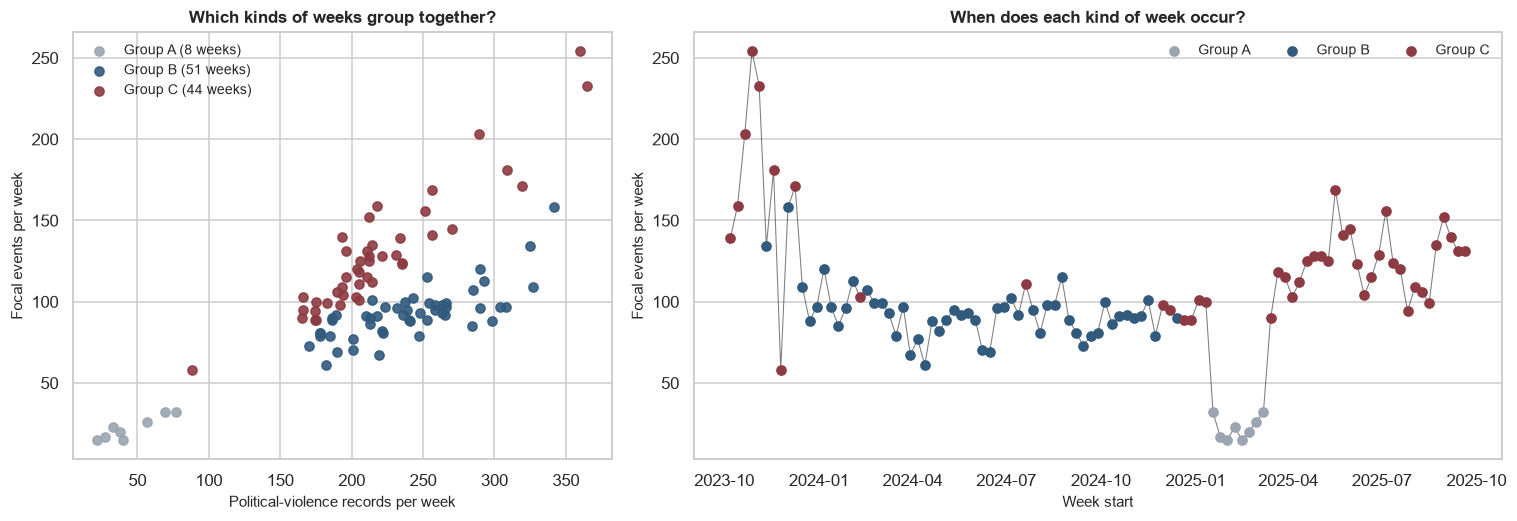

In [64]:
K = 3
km = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(Xs)
gwc["cluster"] = km.labels_
# Name clusters by their median focal count so the labels are stable between runs
rank = gwc.groupby("cluster").focal_events.median().sort_values().index.tolist()
names = {c: f"Group {chr(65 + i)}" for i, c in enumerate(rank)}
gwc["regime"] = gwc.cluster.map(names)
cl_prof = gwc.reset_index().groupby("regime").agg(weeks=("focal_events", "size"), first=("week_start", "min"), last=("week_start", "max"),
                                                  median_focal=("focal_events", "median"), median_political=("political_events", "median"),
                                                  median_share=("focal_share", "median"))
display(cl_prof.round({"median_focal": 1, "median_political": 1, "median_share": 3}))
print("Week starts per group:")
for g, d in gwc.groupby("regime"):
    print(f"  {g}:", ", ".join(f"{x:%Y-%m-%d}" for x in d.index) if len(d) <= 12 else f"{len(d)} weeks; first {d.index.min():%Y-%m-%d}, last {d.index.max():%Y-%m-%d}")

pal = dict(zip(sorted(names.values()), [C_GREY, C_OTHER, C_FOCAL]))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.9), gridspec_kw={"width_ratios": [1, 1.5]})
ax = axes[0]
for g, d in gwc.groupby("regime"):
    ax.scatter(d.political_events, d.focal_events, color=pal[g], s=36, alpha=0.9, label=f"{g} ({len(d)} weeks)")
ax.set_xlabel("Political-violence records per week"); ax.set_ylabel("Focal events per week")
ax.set_title("Which kinds of weeks group together?"); ax.legend(frameon=False); ax.grid(axis="x", visible=True)
ax = axes[1]
ax.plot(gwc.index, gwc.focal_events, color="black", lw=0.7, alpha=0.5)
for g, d in gwc.groupby("regime"):
    ax.scatter(d.index, d.focal_events, color=pal[g], s=36, label=g, zorder=3)
ax.set_xlabel("Week start"); ax.set_ylabel("Focal events per week")
ax.set_title("When does each kind of week occur?"); ax.legend(frameon=False, ncol=3)
plt.tight_layout(); plt.show()

**Interpretation.** Group A is 8 weeks (Jan 18 to Mar 8, 2025) with a median of 21.5 focal events and 39 political-violence records, Group B is 51 weeks (Nov 2023 to Dec 2024) with a median of 92 focal events and a 38.3% share, and Group C is 44 weeks with a median of 123.5 focal events and a 57.4% share, made up of the first weeks after Oct 7, 2023, 6 later weeks of 2024, 2 weeks of early January 2025 and 28 weeks from Mar 15, 2025 on (BQ4). The groups follow time more than chance: an early high phase, a long 2024 plateau, the Jan to Mar 2025 gap, and a high-share 2025 phase. The B and C boundary is blurry (14 weeks of C fall before 2025), the groups are descriptive labels, and with 103 weeks a different seed or feature set could move some weeks across.

### 7.3 Where are incidents recorded?

**Question.** Where are post-Oct 7 land focal incidents concentrated, and does the picture survive when only precision-1 records are kept (BQ3, BQ5)? Many incidents share the same coordinate, so we first aggregate to distinct coordinate pairs ("sites") and then measure how unevenly incidents spread over them (Gini: 0 is even, 1 is all in one place).

*Source table: `acled_focal_incidents.csv` (land only; coast-coded events excluded). Unit: one incident, then one coordinate pair.*

In [65]:
def site_table(df):
    return (df.groupby(["latitude", "longitude"])
              .agg(events=("event_id_cnty", "size"), district=("admin2", lambda s: s.mode().iat[0]),
                   location=("location", lambda s: s.mode().iat[0]), precision1_share=("geo_precision_1", "mean"))
              .reset_index().sort_values("events", ascending=False))

sites_full = site_table(incidents)
inc_p1 = incidents[incidents.geo_precision_1]
sites_p1 = site_table(inc_p1)

def gini(v):
    v = np.sort(np.asarray(v, float)); n = len(v)
    return (2 * np.arange(1, n + 1) - n - 1).dot(v) / (n * v.sum())

conc = pd.DataFrame({
    "Incidents": [len(incidents), len(inc_p1)],
    "Distinct coordinate pairs": [len(sites_full), len(sites_p1)],
    "Median incidents per coordinate": [sites_full.events.median(), sites_p1.events.median()],
    "Top 10 coordinates, share of incidents": [sites_full.events.head(10).sum() / len(incidents), sites_p1.events.head(10).sum() / len(inc_p1)],
    "Top 20 coordinates, share of incidents": [sites_full.events.head(20).sum() / len(incidents), sites_p1.events.head(20).sum() / len(inc_p1)],
    "Gini of incidents across coordinates": [gini(sites_full.events), gini(sites_p1.events)],
}, index=["All land focal incidents", "Precision 1 only"]).T
display(conc.round(3))
print("Share of incidents by district:")
display(incidents.admin2.value_counts(normalize=True).round(3).rename("share").to_frame())
print("Ten largest coordinates (all land focal incidents):")
display(sites_full.head(10).round({"precision1_share": 3}))

,All land focal incidents,Precision 1 only
Incidents,10583.000,7576.000
Distinct coordinate pairs,101.000,95.000
Median incidents per coordinate,54.000,33.000
"Top 10 coordinates, share of incidents",0.338,0.381
"Top 20 coordinates, share of incidents",0.565,0.625
Gini of incidents across coordinates,0.572,0.605


Share of incidents by district:


,share
admin2,
Gaza City,0.325
Khan Yunis,0.215
Deir El Balah,0.214
North Gaza,0.125
Rafah,0.122


Ten largest coordinates (all land focal incidents):


,latitude,longitude,events,district,location,precision1_share
66,31.4964,34.4522,491,Gaza City,Gaza - Az Zaytun,0.833
55,31.4486,34.3925,440,Deir El Balah,An Nusayrat - Unspecified,0.895
80,31.5272,34.4835,435,North Gaza,Jabalya,0.821
54,31.4394,34.4031,388,Deir El Balah,Al Burayj,0.778
83,31.5349,34.4667,330,Gaza City,Gaza - Sheikh Radwan,0.682
68,31.4988,34.4699,326,Gaza City,Gaza - Shujaiyya,0.709
82,31.5349,34.4466,321,Gaza City,Gaza - Ash Shati' Camp,0.536
48,31.4178,34.3503,320,Deir El Balah,Deir al Balah,0.938
71,31.5045,34.4743,265,Gaza City,Gaza - Unspecified,0.800
31,31.3424,34.3250,260,Khan Yunis,Bani Suheila,0.585


### Chart 10 — Where are land focal incidents recorded, full vs. precision-1?

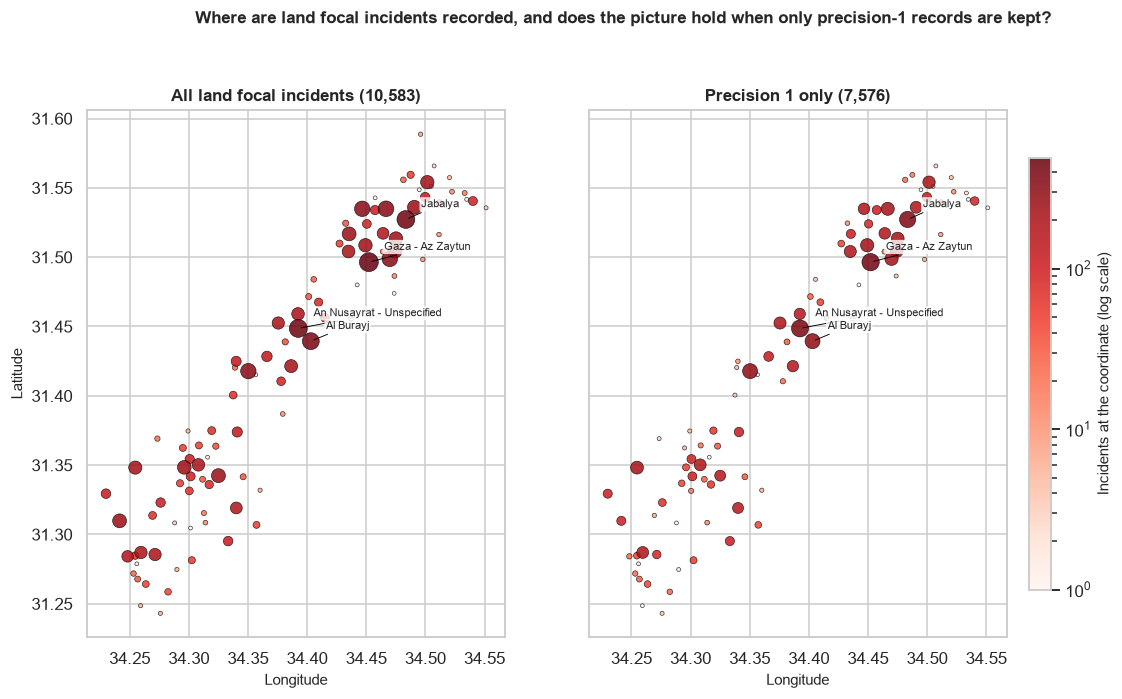

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6.8), sharex=True, sharey=True)
vmax = sites_full.events.max()
for ax, sites, title in [(axes[0], sites_full, f"All land focal incidents ({len(incidents):,})"),
                         (axes[1], sites_p1, f"Precision 1 only ({len(inc_p1):,})")]:
    s = sites.sort_values("events")
    sc = ax.scatter(s.longitude, s.latitude, s=6 + s.events * 0.3, c=s.events, cmap="Reds", norm=LogNorm(vmin=1, vmax=vmax),
                    edgecolor="black", linewidth=0.4, alpha=0.85)
    ax.set_title(title); ax.set_xlabel("Longitude")
    ax.set_aspect(1 / np.cos(np.radians(31.45))); ax.grid(True)
    for _, r in sites.head(4).iterrows():
        ax.annotate(r.location, (r.longitude, r.latitude), textcoords="offset points", xytext=(10, 8), fontsize=7.5,
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8),
                    arrowprops=dict(arrowstyle="-", lw=0.6, color="black"))
axes[0].set_ylabel("Latitude")
fig.suptitle("Where are land focal incidents recorded, and does the picture hold when only precision-1 records are kept?", fontsize=11, fontweight="bold")
cb = fig.colorbar(sc, ax=axes, shrink=0.75, pad=0.02); cb.set_label("Incidents at the coordinate (log scale)")
plt.show()

**Interpretation.** The 10,583 incidents sit on only 101 coordinate pairs along a narrow north-east to south-west strip, with the largest bubbles in Gaza City (Az Zaytun, Sheikh Radwan, Shujaiyya), Jabalya, and the central towns of An Nusayrat, Al Burayj and Deir al Balah (BQ3). The precision-1 map (7,576 incidents, 95 coordinates) keeps the same overall shape but loses 6 small coordinates (41 incidents) and visibly thins the southern part of the strip (BQ5). There is no basemap and coordinates repeat for named places, so this shows recorded concentrations and not exact attack points or borders.

### Chart 11 — Which coordinates hold the most incidents, and how unevenly are incidents spread?

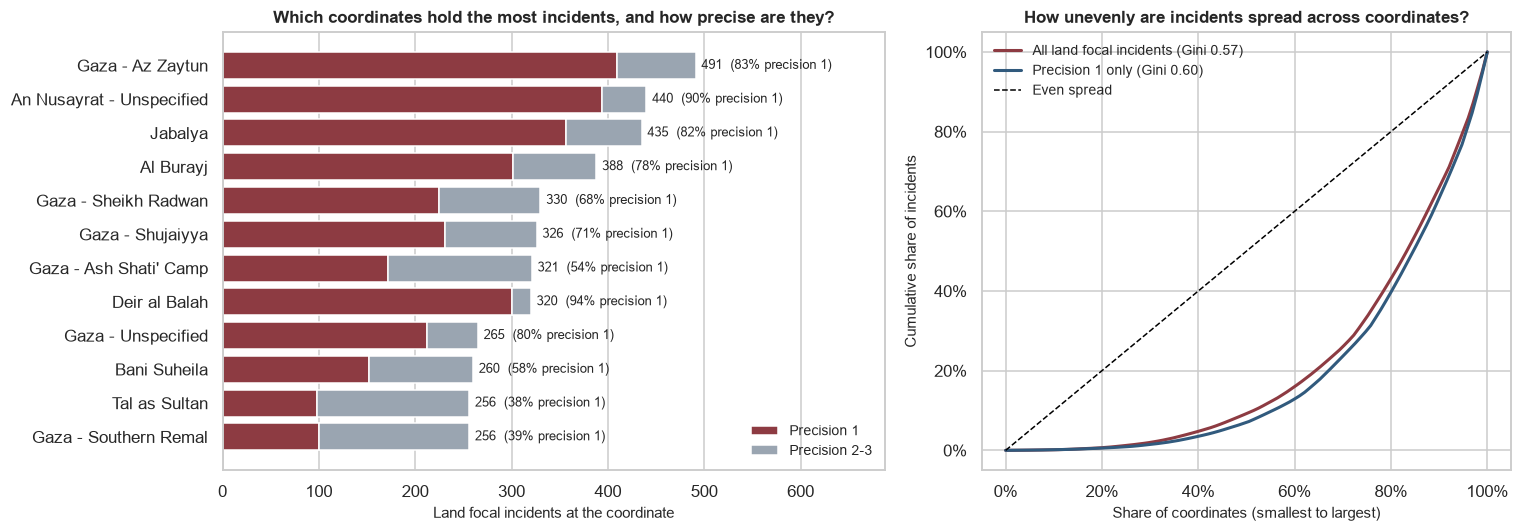

In [67]:
top12 = sites_full.head(12).iloc[::-1].copy()
top12["p1_events"] = (top12.events * top12.precision1_share).round()
top12["other_events"] = top12.events - top12.p1_events

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
ax.barh(top12.location, top12.p1_events, color=C_FOCAL, label="Precision 1")
ax.barh(top12.location, top12.other_events, left=top12.p1_events, color=C_GREY, label="Precision 2-3")
for y, (_, r) in enumerate(top12.iterrows()):
    ax.text(r.events + 6, y, f"{int(r.events)}  ({r.precision1_share:.0%} precision 1)", va="center", fontsize=8.5)
ax.set_xlim(0, top12.events.max() * 1.4)
ax.set_xlabel("Land focal incidents at the coordinate"); ax.set_title("Which coordinates hold the most incidents, and how precise are they?")
ax.legend(frameon=False, loc="lower right"); ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)

ax = axes[1]
for sites, lab, col in [(sites_full, "All land focal incidents", C_FOCAL), (sites_p1, "Precision 1 only", C_OTHER)]:
    v = np.sort(sites.events.to_numpy())
    ax.plot(np.r_[0, np.arange(1, len(v) + 1) / len(v)], np.r_[0, v.cumsum() / v.sum()], color=col, lw=2, label=f"{lab} (Gini {gini(v):.2f})")
ax.plot([0, 1], [0, 1], color="black", ls="--", lw=1, label="Even spread")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Share of coordinates (smallest to largest)"); ax.set_ylabel("Cumulative share of incidents")
ax.set_title("How unevenly are incidents spread across coordinates?"); ax.legend(frameon=False, loc="upper left"); ax.grid(True)
plt.tight_layout(); plt.show()

**Interpretation.** The 10 busiest coordinates hold 33.8% of all incidents and the top 20 hold 56.5% (Gini 0.57); with precision 1 only, these rise to 38.1% and 62.5% (Gini 0.61), so the restriction sharpens concentration (BQ3, BQ5). Among the 12 largest coordinates the precision-1 share runs from 38% to 94% (Tal as Sultan and Southern Remal are lowest, Deir al Balah highest), and 30 of the 101 coordinates are below 50% precision 1, so the precision filter removes places unevenly. A busy coordinate may simply be a well-documented place name, so concentration here is a statement about the records.

### 7.4 Preview of DBSCAN settings (for Phase 4)

**Question.** Phase 4 plans DBSCAN on land focal coordinates. Before it starts, how sensitive is the result to the radius and to `min_samples`, and does the precision-1 subset behave differently? Following the project rule, coordinates are converted to **radians** and the **haversine** distance is used (latitude and longitude are *not* standardised separately). This is a sensitivity preview, not a tuned model: there are no labels to validate against, and repeated coordinates matter because `min_samples` counts repeated incidents, not distinct places.

In [68]:
R_EARTH_KM = 6371.0088
def run_dbscan(df, eps_km, min_samples):
    X = np.radians(df[["latitude", "longitude"]].to_numpy())          # geographic coordinates in radians
    db = DBSCAN(eps=eps_km / R_EARTH_KM, min_samples=min_samples, metric="haversine", algorithm="ball_tree").fit(X)
    return db.labels_

rows = []
for subset, d in [("All land focal incidents", incidents), ("Precision 1 only", inc_p1)]:
    for ms in (10, 50):
        for eps in (0.25, 0.5, 1.0, 1.5, 2.0, 3.0):
            lab = run_dbscan(d, eps, ms)
            n_cl = len(set(lab)) - (1 if -1 in lab else 0)
            counts = pd.Series(lab[lab >= 0]).value_counts()
            rows.append({"subset": subset, "min_samples": ms, "eps_km": eps, "clusters": n_cl,
                         "noise_share": (lab == -1).mean(), "largest_cluster_share": counts.max() / len(d) if len(counts) else 0.0})
db_grid = pd.DataFrame(rows)
display(db_grid.round({"noise_share": 3, "largest_cluster_share": 3}))

,subset,min_samples,eps_km,clusters,noise_share,largest_cluster_share
0,All land focal incidents,10,0.25,81,0.007,0.046
1,All land focal incidents,10,0.50,81,0.006,0.046
2,All land focal incidents,10,1.00,58,0.005,0.081
3,All land focal incidents,10,1.50,30,0.003,0.220
4,All land focal incidents,10,2.00,19,0.001,0.424
5,All land focal incidents,10,3.00,1,0.000,1.000
6,All land focal incidents,50,0.25,55,0.070,0.046
7,All land focal incidents,50,0.50,55,0.070,0.046
8,All land focal incidents,50,1.00,43,0.042,0.081
9,All land focal incidents,50,1.50,20,0.028,0.220


### Chart 12 — How do the number of clusters, noise and the largest cluster change with the radius?

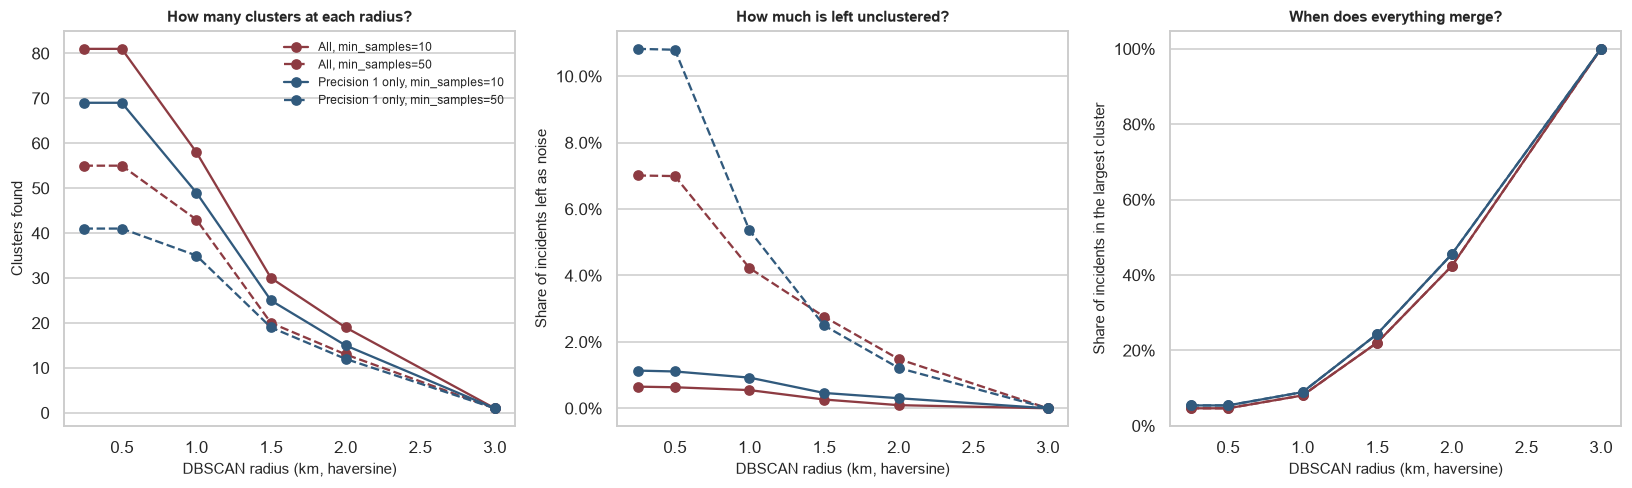

In [69]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
styles = {("All land focal incidents", 10): (C_FOCAL, "-"), ("All land focal incidents", 50): (C_FOCAL, "--"),
          ("Precision 1 only", 10): (C_OTHER, "-"), ("Precision 1 only", 50): (C_OTHER, "--")}
for ax, col, ylab, title in [(axes[0], "clusters", "Clusters found", "How many clusters at each radius?"),
                             (axes[1], "noise_share", "Share of incidents left as noise", "How much is left unclustered?"),
                             (axes[2], "largest_cluster_share", "Share of incidents in the largest cluster", "When does everything merge?")]:
    for (subset, ms), (c, ls) in styles.items():
        d = db_grid[(db_grid.subset == subset) & (db_grid.min_samples == ms)]
        ax.plot(d.eps_km, d[col], color=c, ls=ls, marker="o", label=f"{subset.replace(' land focal incidents', '')}, min_samples={ms}")
    if col != "clusters":
        ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.set_xlabel("DBSCAN radius (km, haversine)"); ax.set_ylabel(ylab); ax.set_title(title, fontsize=10)
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

**Interpretation.** Radii of 0.25 and 0.5 km give identical results (81 clusters with `min_samples` 10) because the recorded coordinates are discrete places spaced further apart; the count then drops to 58 at 1 km, 30 at 1.5 km and 19 at 2 km, where the largest cluster already holds 42.4% of incidents, and at 3 km everything merges into a single cluster (BQ3). Raising `min_samples` to 50 leaves more incidents as noise (7.0% of all incidents, 10.8% at precision 1, at 0.5 km), and the precision-1 subset gives fewer clusters at every radius below 3 km (for example 69 against 81 at 0.5 km). A usable radius for Phase 4 therefore lies roughly between 1 and 2 km, and because 81 of the 101 coordinates already hold 10 or more incidents, DBSCAN here mostly groups named places, so Phase 4 should compare it with the district counts and consider weighting by incidents per coordinate.

## 8. Pattern register and handoff

The register collects what Sections 3 to 7 found, with the business question and what each pattern means for the next tasks. All numbers are repeated from the sections above.

In [70]:
register = pd.DataFrame([
    ("Imbalance", "Focal share is 16.2% before Oct 7 (63 of 389) and 47.6% after (10,651 of 22,364); Battles are 0 of 1,593 and Violence against civilians 784 of 790 after Oct 7", "BQ1, BQ5", "The earlier period and the extreme event types have too few minority cases to model on their own"),
    ("Suspicious values", "576 records report 24+ fatalities (2.2% of records) and hold 37.6% of all reported fatalities; 281 of them fall in Q4 2023", "BQ4", "Never delete them; run results with and without them"),
    ("Suspicious values", "13 complete weeks are flagged for focal events by a trailing 8-week median/MAD rule: lows in Mar and Jun 2024, Jan to Feb 2025 and Jun 2025, and highs (Mar 15 to Apr 5 and May 17, 2025) that mostly follow the early-2025 collapse", "BQ4", "A short trailing window scores a recovery as a spike; test a longer window"),
    ("Suspicious values", "50 of 475 scored district-weeks (10.5%) are flagged, most often in North Gaza (14.7%) and Gaza City (13.7%)", "BQ4", "The anomaly target is imbalanced; small districts are noisy"),
    ("Trend", "Weekly focal events show no lasting direction (rho 0.10), political-violence records fall (rho -0.55) and the focal share rises (rho 0.51; 34.0% in Jan 2024 to 67.0% in Sep 2025)", "BQ1, BQ4", "Use counts and shares as separate signals"),
    ("Seasonality", "No repeating calendar pattern: the monthly means of 2024 and 2025 are not aligned (rho -0.30) and no weekday stands out (ratio 1.11)", "BQ4", "Do not add seasonal terms; two years cannot test a yearly cycle"),
    ("Persistence", "Weekly focal events are autocorrelated (0.76 at lag 1, above the 95% band through lag 6) while week-to-week changes are not", "BQ4", "Supports previous-week and previous-four-week features"),
    ("Segments", "Gaza City holds 32.3% of known-district focal events; North Gaza is low in volume but the most bursty (0.83)", "BQ4", "Use per-district baselines, not one Gaza-wide threshold"),
    ("Clustering of weeks", "Three groups of weeks: 8 low weeks (Jan 18 to Mar 8, 2025), 51 weeks of a 2024 plateau and 44 higher-share weeks (the first weeks after Oct 7, 2023 and Mar to Sep 2025)", "BQ4", "Consider a regime indicator and treat the early weeks and the early-2025 gap with care"),
    ("Spatial concentration", "10,583 incidents sit on 101 distinct coordinates; the top 10 hold 33.8% and the top 20 hold 56.5%", "BQ3", "DBSCAN mostly groups named places; consider weighting by incidents per coordinate"),
    ("Precision", "Precision-1 keeps 95 of the 101 coordinates, but among the 12 largest coordinates its share runs from 38% to 94%; concentration rises (Gini 0.57 to 0.61)", "BQ3, BQ5", "Run DBSCAN on both the full and precision-1 subsets"),
    ("DBSCAN preview", "Clusters fall from 81 at 0.5 km to 19 at 2 km and merge into one at 3 km (min_samples 10)", "BQ3", "Try radii of about 1 to 2 km"),
], columns=["Pattern type", "What we saw", "Business question", "Phase 4 implication"])
with pd.option_context("display.max_colwidth", None):
    display(register)

,Pattern type,What we saw,Business question,Phase 4 implication
0,Imbalance,"Focal share is 16.2% before Oct 7 (63 of 389) and 47.6% after (10,651 of 22,364); Battles are 0 of 1,593 and Violence against civilians 784 of 790 after Oct 7","BQ1, BQ5",The earlier period and the extreme event types have too few minority cases to model on their own
1,Suspicious values,576 records report 24+ fatalities (2.2% of records) and hold 37.6% of all reported fatalities; 281 of them fall in Q4 2023,BQ4,Never delete them; run results with and without them
2,Suspicious values,"13 complete weeks are flagged for focal events by a trailing 8-week median/MAD rule: lows in Mar and Jun 2024, Jan to Feb 2025 and Jun 2025, and highs (Mar 15 to Apr 5 and May 17, 2025) that mostly follow the early-2025 collapse",BQ4,A short trailing window scores a recovery as a spike; test a longer window
3,Suspicious values,"50 of 475 scored district-weeks (10.5%) are flagged, most often in North Gaza (14.7%) and Gaza City (13.7%)",BQ4,The anomaly target is imbalanced; small districts are noisy
4,Trend,"Weekly focal events show no lasting direction (rho 0.10), political-violence records fall (rho -0.55) and the focal share rises (rho 0.51; 34.0% in Jan 2024 to 67.0% in Sep 2025)","BQ1, BQ4",Use counts and shares as separate signals
5,Seasonality,No repeating calendar pattern: the monthly means of 2024 and 2025 are not aligned (rho -0.30) and no weekday stands out (ratio 1.11),BQ4,Do not add seasonal terms; two years cannot test a yearly cycle
6,Persistence,"Weekly focal events are autocorrelated (0.76 at lag 1, above the 95% band through lag 6) while week-to-week changes are not",BQ4,Supports previous-week and previous-four-week features
7,Segments,Gaza City holds 32.3% of known-district focal events; North Gaza is low in volume but the most bursty (0.83),BQ4,"Use per-district baselines, not one Gaza-wide threshold"
8,Clustering of weeks,"Three groups of weeks: 8 low weeks (Jan 18 to Mar 8, 2025), 51 weeks of a 2024 plateau and 44 higher-share weeks (the first weeks after Oct 7, 2023 and Mar to Sep 2025)",BQ4,Consider a regime indicator and treat the early weeks and the early-2025 gap with care
9,Spatial concentration,"10,583 incidents sit on 101 distinct coordinates; the top 10 hold 33.8% and the top 20 hold 56.5%",BQ3,DBSCAN mostly groups named places; consider weighting by incidents per coordinate


### Handoff notes

**For Task 6 (business questions, Mark).**
- **BQ1:** the focal share rises from 16.2% to 47.6% (Task 2 and Task 4), but the earlier period has only 63 focal events, and the weekly share rises mainly because non-focal political violence falls (Section 5).
- **BQ3:** incidents concentrate on 101 coordinates, the top 20 hold 56.5%, and the picture is stable under the precision-1 restriction (Section 7.3).
- **BQ4:** persistence is strong, there is no seasonality, and Gaza City carries the most focal events while North Gaza is the most bursty (Sections 6 and 7.1).
- **BQ5:** results that change under the precision-1 restriction are the focal share (59.6% against 31.7%) and the level of concentration (Gini 0.57 to 0.61).

**For Task 7 (modelling, Kyle).**
- **Weekly anomaly detection:** use district-specific trailing baselines; an 8-week window scores the March 2025 recovery as spikes, so test a longer window or a recovery rule. About 10.5% of district-weeks are flagged, which is an imbalanced target for evaluation.
- **DBSCAN:** use haversine on radians, try radii of about 1 to 2 km, run on the full and precision-1 subsets, and decide how to treat repeated coordinates (101 distinct pairs for 10,583 incidents).
- **Features:** previous-week and previous-four-week focal counts are justified by the autocorrelation; seasonal terms are not.
- **Imbalance:** the earlier period and the extreme event types have very small minority classes (Section 3), and flagged high-fatality records (576) should be tested with and without.

### Limitations
- ACLED is a recorded-event dataset; reporting coverage can change over time and place, so a trend, a gap or a cluster can reflect documentation as well as events.
- Fatalities are reported event totals and do not identify civilian deaths; a zero can mean no figure was recorded.
- Two years of weekly data cannot support a test of yearly seasonality, and the rank-correlation and autocorrelation values ignore the fact that neighbouring weeks are related.
- Robust z-scores, k-means groups and the DBSCAN preview are screening and description tools without ground truth; their settings were chosen to describe the data, not to optimise anything.
- Coordinates repeat for named places and have varying precision, so spatial results describe recorded concentrations, not exact points.
- Findings describe a historical snapshot (Jan 2022 to Sep 2025), not current conditions.

### Reproducibility checklist
- [ ] The consistency table in Section 2 shows `True` in every row.
- [ ] `random_state=42` is used for k-means, and DBSCAN is deterministic, so reruns give the same numbers.
- [ ] Packages: numpy, pandas, matplotlib, seaborn, scipy (from the Phase 2 requirements) plus scikit-learn.
- [ ] The incomplete week (Sep 27, 2025) is shown but not scored.

### References
1. Group 7. *Phase 1: Dataset Selection and Business Problem* (BQ1 to BQ5).
2. Group 7. *Phase 2: Data Preprocessing* (focal-event rule, periods, `data/processed/` outputs).
3. Group 7. *Phase 3 notebooks:* univariate template, bivariate and multivariate (Charts 1 to 11), hypothesis testing (Hypotheses A and B).
4. Iglewicz, B. and Hoaglin, D. (1993). *How to Detect and Handle Outliers* (modified z-score and the 3.5 cut-off).
5. Ester, M., Kriegel, H.-P., Sander, J., Xu, X. (1996). A density-based algorithm for discovering clusters (DBSCAN).
6. scikit-learn documentation: `DBSCAN`, `KMeans`, `silhouette_score`.
7. ACLED. Codebook, definitions and interpretation limitations.
8. DS312. *Final Project Guide* and *Phase 3 EDA Guide (Group 7)*.

# Answer or refine your business questions from Phase 1

|**BQ1 — How do recorded focal-event counts and their share of political-violence events differ before and after October 7, 2023 in Gaza?**

#### Findings

Before October 7, 2023, there were **63 focal events out of 389 political-violence events**, giving a focal-event share of **16.2%**. After October 7, there were **10,651 focal events out of 22,364 political-violence events**, giving a much higher share of **47.6%**. The weekly average also increased from **0.68 to 102.8 focal events per week**. This shows a large increase in both the number and share of recorded focal events after October 7.


**BQ2 — Which recorded actors and event/sub-event types recur among focal events?**

#### Findings

Most focal events were **Explosions/Remote violence**, with **9,906 events (92.5%)**, followed by **Violence against civilians**, with **808 events (7.5%)**. The most common sub-event type was **Air/drone strike**, with **8,420 events (78.6%)**, followed by **Shelling/artillery/missile attack (1,442)** and **Attack (792)**. For actors, **“Civilians (Palestine)”** appeared as `actor2` in all **10,714 focal events**, while **“Military Forces of Israel (2022-)”** appeared as `actor1` in **10,493 events (97.9%)**.


**BQ3 — Where are post–October 7 land focal events concentrated, and how does precision affect the view?**

#### Findings

Post–October 7 land focal events were mainly concentrated in **Gaza City (32.5%)**, followed by **Khan Yunis (21.5%)** and **Deir El Balah (21.4%)**. The top 10 coordinate pairs accounted for **33.8%** of all incidents. When only the most precise **precision-1** records were used, the concentration increased to **38.1%**, but about **28% of incidents were excluded**. This shows that the location pattern can change depending on the precision of the recorded coordinates.


**BQ4 — Which district-weeks show high or sustained focal activity relative to recent local history?**

#### Findings

The highest weekly focal-event count was **254 events during the week of October 28, 2023**. **Gaza City** had the highest overall activity with **3,451 focal events**, including the highest district-week count of **102 events during the week of November 4, 2023**. Weekly activity was also strongly related to recent activity, with a Spearman rank correlation (Gaza level) of **0.70 with the previous week** and **0.66 with the previous four weeks**. This means that high activity in one week often continued into the following weeks.

**BQ5 — Which patterns change under alternative periods, geography, or precision restrictions?**

#### Findings

The biggest difference appeared when using different levels of **location precision**. After October 7, the focal-event share was **59.6% for precision-1 records** compared with **31.7% for precision-2 records**. Before October 7, the shares were lower at **21.7% for precision-1** and **14.2% for precision-2**. Despite this difference, the main pattern stays the same: **focal events increased after October 7, Explosions/Remote violence was the dominant event type in both periods (61.9% before and 92.6% after October 7), and Gaza City was the district with the highest number of focal events after October 7**, under both precision levels. Before October 7, North Gaza recorded the most focal events (28, compared with 10 in Gaza City), although this period contains only 63 focal events. **(Chart 5)**


 The reported findings are therefore provisional and may be revised in light of the final plots, which should be consulted to verify the exact results.

## 2. Sources
1. `DMA_Phase1.ipynb`
2. `DMA_Phase3_Bivariate_Multivariate.ipynb`
1. `DMA_Phase2.ipynb`


## 3.13 Limitations, reproducibility, and references

### Limitations to report
- ACLED is a recorded-event dataset and may underrepresent events; reporting coverage can change across time and place.
- Fatality totals are event-level reported values and do not automatically identify civilian fatalities.
- Actor, targeting, location, and precision fields reflect the source’s coding and may be incomplete or approximate.
- Observations may be related across time and geography, limiting simple independence assumptions in statistical tests.
- Descriptive differences and statistical associations do not establish causation, intent, or legal classification.

### Reproducibility checklist
- [ ] Phase 2 exports are loaded from `data/processed` and source snapshot is identified.
- [ ] Date parsing and precision category restoration are explicit.
- [ ] Every subset/filter is described, including coast exclusion and district missingness.
- [ ] Randomized tests include a fixed seed and number of resamples.
- [ ] Notebook runs from top to bottom and all charts/tables reconcile to their analysis table.

### References
- Group 7, *Phase 1 — Dataset Selection and Business Problem*.
- Group 7, *Phase 2 — Data Preprocessing*.
- *DS312 Final Project Guide*, Phase 3: Exploratory Data Analysis (EDA).
- ACLED, *Codebook* and the documented event-level export snapshot.

## Task 7 — Key insights and modeling implications (to be completed)

### Key insights (final submission: 5–8 evidence-backed bullets)
1. **[Insight]** [Metric/figure/table and which business question it answers.]  
2. **[Insight]** [Evidence and limitation.]  
3. **[Insight]** [Evidence and limitation.]  
4. **[Insight]** [Evidence and limitation.]  
5. **[Insight]** [Evidence and limitation.]  
6. **[Optional insight]** [...]  
7. **[Optional insight]** [...]  
8. **[Optional insight]** [...]

### Phase 4 modeling plan

| Proposed technique | EDA evidence that supports it | Inputs / target | Baseline or comparison | Risks / sensitivity checks |
|---|---|---|---|---|
| DBSCAN spatial clustering | [Concentration, repeated locations, precision pattern] | Land focal-event coordinates in radians; Haversine distance | District-level count summaries | Vary epsilon/min_samples; compare precision-1 subset; interpret clusters as recorded concentrations. |
| Weekly anomaly detection | [Visible spikes/persistence and historical distribution] | District-week focal counts plus eligible prior-week history | Trailing median/MAD rule | Chronological evaluation; incomplete weeks and sparse history; compare with Isolation Forest if retained. |

Only retain techniques supported by the EDA and Phase 1 plan. Record any revisions to the modeling questions and why the revision follows from evidence.